1 - Libraries and configuration

In [1]:
# ============================================================
# SECTION 1 — IMPORT LIBRARIES AND CONFIGURATION
# ============================================================

# 1.1 Import libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------
# 1.2 Set random seeds for reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# 1.3 Dataset locations
# ------------------------------------------------------------

# Place the four CSV files in the same folder as your notebook.

DATA_FILES = {
    "Client1": "Client1(original).csv",
    "Client2": "Client2(original).csv",
    "Client3": "Client3(original).csv",
    "Switch":  "Switch(original).csv"
}

# ------------------------------------------------------------
# 1.4 LSTM configuration
# ------------------------------------------------------------

SEQUENCE_LENGTH = 30

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 50
BATCH_SIZE = 32

LEARNING_RATE = 0.001

ANOMALY_PERCENTILE = 99

# ------------------------------------------------------------
# 1.5 Create output folders
# ------------------------------------------------------------

OUTPUT_DIR = Path("LSTM_Results")
MODEL_DIR = OUTPUT_DIR / "Models"
RESULTS_DIR = OUTPUT_DIR / "Anomaly_Results"
PLOTS_DIR = OUTPUT_DIR / "Plots"

for folder in [MODEL_DIR, RESULTS_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1.6 Check dataset availability
# ------------------------------------------------------------

print("=" * 55)
print("LSTM AUTOENCODER — CAPSTONE PROJECT")
print("=" * 55)

print("\nTensorFlow Version:", tf.__version__)
print("Sequence Length:", SEQUENCE_LENGTH)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Anomaly Percentile:", ANOMALY_PERCENTILE)

print("\nSuccessfully created output directories")


LSTM AUTOENCODER — CAPSTONE PROJECT

TensorFlow Version: 2.21.0
Sequence Length: 30
Epochs: 50
Batch Size: 32
Anomaly Percentile: 99

Successfully created output directories


2 - Retrieve telemetry

In [2]:
# ============================================================
# SECTION 2 — LOAD, CLEAN AND PRESERVE ORIGINAL DATA
# ============================================================

# ------------------------------------------------------------
# 2.1 Define original metrics
# ------------------------------------------------------------

ORIGINAL_METRICS = [
    "cpu_pct",
    "temperature_c",
    "latency_ms",
    "packet_loss_pct",
    "disk_usage_pct",
    "throughput_bytes_per_sec",
    "packet_error_rate_pct"
]

SWITCH_METRICS = [
    "cpu_pct",
    "free_memory",
    "temperature",
    "power_supply_state"
]

# ------------------------------------------------------------
# 2.2 Create storage for original and cleaned datasets
# ------------------------------------------------------------

original_datasets = {}
datasets = {}
device_metrics = {}

cleaning_summary = []

ORIGINAL_DIR = OUTPUT_DIR / "Original_Data"
CLEANED_DIR = OUTPUT_DIR / "Cleaned_Data"

ORIGINAL_DIR.mkdir(parents=True, exist_ok=True)
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2.3 Process each device
# ------------------------------------------------------------

for device, filename in DATA_FILES.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    # Load wide-format CSV
    df = pd.read_csv(filename, low_memory=False)

    # Convert timestamps to UTC
    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True,
        errors="coerce"
    )

    # Check invalid timestamps before removing them
    invalid_timestamps = df["timestamp"].isna().sum()

    # Remove invalid timestamps and sort chronologically
    df = df.dropna(subset=["timestamp"])
    df = df.sort_values("timestamp").reset_index(drop=True)

    # --------------------------------------------------------
    # 2.4 Select original collected metrics
    # --------------------------------------------------------

    if device == "Switch":
        metrics = SWITCH_METRICS
    else:
        metrics = ORIGINAL_METRICS

    missing_columns = [
        metric for metric in metrics
        if metric not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{device} is missing: {missing_columns}"
        )

    df = df[["timestamp"] + metrics].copy()

    # Convert selected metrics to numeric
    for metric in metrics:
        df[metric] = pd.to_numeric(
            df[metric],
            errors="coerce"
        )

    # --------------------------------------------------------
    # 2.5 Preserve original observations
    # --------------------------------------------------------

    original_datasets[device] = df.copy()
    device_metrics[device] = metrics.copy()

    original_rows = len(df)

    original_missing = int(
        df[metrics].isna().sum().sum()
    )

    original_file = (
        ORIGINAL_DIR / f"{device}_Original.csv"
    )

    df.to_csv(original_file, index=False)

    # --------------------------------------------------------
    # 2.6 Create cleaned dataset
    # --------------------------------------------------------

    cleaned = df.copy()

    removed_latency_period = 0
    last_missing_time = None

    # Remove everything up to the last missing latency
    # for Raspberry Pi devices only
    if device != "Switch":

        missing_latency = cleaned["latency_ms"].isna()

        if missing_latency.any():

            last_missing_index = np.flatnonzero(
                missing_latency.to_numpy()
            )[-1]

            last_missing_time = cleaned.loc[
                last_missing_index, "timestamp"
            ]

            removed_latency_period = last_missing_index + 1

            cleaned = cleaned.iloc[
                last_missing_index + 1:
            ].copy()

    # Remove any remaining observations with missing metrics
    before_dropna = len(cleaned)

    cleaned = cleaned.dropna(
        subset=metrics
    ).reset_index(drop=True)

    removed_missing_rows = before_dropna - len(cleaned)

    # Check for duplicate timestamps
    duplicate_count = int(
        cleaned["timestamp"].duplicated().sum()
    )

    if duplicate_count > 0:
        raise ValueError(
            f"{device} has {duplicate_count} duplicate timestamps."
        )

    # --------------------------------------------------------
    # 2.7 Store and save cleaned dataset
    # --------------------------------------------------------

    datasets[device] = cleaned

    cleaned_file = (
        CLEANED_DIR / f"{device}_Cleaned.csv"
    )

    cleaned.to_csv(cleaned_file, index=False)

    # --------------------------------------------------------
    # 2.8 Record cleaning information
    # --------------------------------------------------------

    cleaning_summary.append({
        "Device": device,
        "Original_Rows": original_rows,
        "Invalid_Timestamps": int(invalid_timestamps),
        "Original_Missing_Values": original_missing,
        "Removed_Initial_Period": removed_latency_period,
        "Removed_Incomplete_Rows": removed_missing_rows,
        "Remaining_Rows": len(cleaned),
        "Number_of_Metrics": len(metrics),
        "Last_Missing_Latency": last_missing_time,
        "Cleaned_Start": (
            cleaned["timestamp"].min()
            if not cleaned.empty else pd.NaT
        ),
        "Cleaned_End": (
            cleaned["timestamp"].max()
            if not cleaned.empty else pd.NaT
        )
    })

    # --------------------------------------------------------
    # 2.9 Display device results
    # --------------------------------------------------------

    print("\nOriginal observations:", original_rows)
    print("Original missing values:", original_missing)

    print("\nCleaning:")
    print("Removed initial period:", removed_latency_period)
    print("Removed incomplete rows:", removed_missing_rows)

    if last_missing_time is not None:
        print("Last missing latency:", last_missing_time)

    print("\nCleaned observations:", len(cleaned))
    print("Number of metrics:", len(metrics))

    print("\nSelected Metrics:")
    for metric in metrics:
        print(" -", metric)

    print("\nRemaining missing values:")
    print(cleaned[metrics].isna().sum().to_string())

    intervals = (
        cleaned["timestamp"]
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    if not intervals.empty:
        print("\nSampling Intervals:")
        print(f"Median: {intervals.median():.2f} seconds")
        print(f"Mean:   {intervals.mean():.2f} seconds")
        print(f"Max:    {intervals.max():.2f} seconds")

    print("\nFirst 3 cleaned rows:")
    print(cleaned.head(3).to_string(index=False))

# ============================================================
# 2.10 SAVE FINAL CLEANING SUMMARY
# ============================================================

summary_df = pd.DataFrame(cleaning_summary)

summary_file = OUTPUT_DIR / "Cleaning_Summary.csv"
summary_df.to_csv(summary_file, index=False)

print("\n" + "=" * 60)
print("SECTION 2 COMPLETE")
print("=" * 60)

print("\nFinal Dataset Summary:")
print(
    summary_df[
        [
            "Device",
            "Original_Rows",
            "Removed_Initial_Period",
            "Removed_Incomplete_Rows",
            "Remaining_Rows",
            "Number_of_Metrics"
        ]
    ].to_string(index=False)
)

print("\nFiles saved to:", OUTPUT_DIR.resolve())


DEVICE: Client1

Original observations: 185055
Original missing values: 13824

Cleaning:
Removed initial period: 19346
Removed incomplete rows: 3
Last missing latency: 2026-09-28 01:23:29.194491+00:00

Cleaned observations: 165706
Number of metrics: 7

Selected Metrics:
 - cpu_pct
 - temperature_c
 - latency_ms
 - packet_loss_pct
 - disk_usage_pct
 - throughput_bytes_per_sec
 - packet_error_rate_pct

Remaining missing values:
cpu_pct                     0
temperature_c               0
latency_ms                  0
packet_loss_pct             0
disk_usage_pct              0
throughput_bytes_per_sec    0
packet_error_rate_pct       0

Sampling Intervals:
Median: 14.07 seconds
Mean:   13.63 seconds
Max:    168.79 seconds

First 3 cleaned rows:
                       timestamp  cpu_pct  temperature_c  latency_ms  packet_loss_pct  disk_usage_pct  throughput_bytes_per_sec  packet_error_rate_pct
2026-09-28 01:23:56.842664+00:00      0.0           34.5       0.575                0            

3 - Clean and preprocess

In [3]:
# ============================================================
# SECTION 3 — DATA SPLITTING AND NORMALISATION
# ============================================================

from sklearn.preprocessing import StandardScaler
import joblib

# ------------------------------------------------------------
# 3.1 Configuration
# ------------------------------------------------------------

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

assert np.isclose(
    TRAIN_RATIO + VAL_RATIO + TEST_RATIO, 1.0
), "Data split ratios must add up to 1."

# Store results for Section 4
split_data = {}
scalers = {}

# ------------------------------------------------------------
# 3.2 Process each device independently
# ------------------------------------------------------------

for device, df in datasets.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    metrics = device_metrics[device]

    # Validate cleaned dataset
    if df.empty:
        raise ValueError(f"{device} has no observations.")

    if df[metrics].isna().any().any():
        raise ValueError(f"{device} contains missing values.")

    if not df["timestamp"].is_monotonic_increasing:
        raise ValueError(f"{device} timestamps are not sorted.")

    if df["timestamp"].duplicated().any():
        raise ValueError(f"{device} has duplicate timestamps.")

    # --------------------------------------------------------
    # 3.3 Split chronologically (70% / 15% / 15%)
    # --------------------------------------------------------

    total_rows = len(df)

    train_end = int(total_rows * TRAIN_RATIO)
    val_end = int(
        total_rows * (TRAIN_RATIO + VAL_RATIO)
    )

    train_df = df.iloc[:train_end].copy()
    val_df = df.iloc[train_end:val_end].copy()
    test_df = df.iloc[val_end:].copy()

    # --------------------------------------------------------
    # 3.4 Normalise using training data ONLY
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train = scaler.fit_transform(train_df[metrics])
    X_val = scaler.transform(val_df[metrics])
    X_test = scaler.transform(test_df[metrics])

    # TensorFlow uses float32 efficiently
    X_train = X_train.astype(np.float32)
    X_val = X_val.astype(np.float32)
    X_test = X_test.astype(np.float32)

    # --------------------------------------------------------
    # 3.5 Validate normalised data
    # --------------------------------------------------------

    for name, values in [
        ("Train", X_train),
        ("Validation", X_val),
        ("Test", X_test)
    ]:

        nan_count = np.isnan(values).sum()
        inf_count = np.isinf(values).sum()

        print(
            f"{name}: NaN={nan_count}, Inf={inf_count}"
        )

        # Stop if invalid numbers are detected
        if not np.isfinite(values).all():
            raise ValueError(
                f"{device}: Invalid values found in {name}!"
            )

    # --------------------------------------------------------
    # 3.6 Store results for sequence generation
    # --------------------------------------------------------

    split_data[device] = {
        "train": X_train,
        "val": X_val,
        "test": X_test,

        "train_timestamps": train_df["timestamp"].to_numpy(),
        "val_timestamps": val_df["timestamp"].to_numpy(),
        "test_timestamps": test_df["timestamp"].to_numpy(),

        "metrics": metrics
    }

    scalers[device] = scaler

    # --------------------------------------------------------
    # 3.7 Save scaler
    # --------------------------------------------------------

    scaler_file = MODEL_DIR / f"{device}_scaler.joblib"

    joblib.dump(
        {
            "scaler": scaler,
            "metrics": metrics
        },
        scaler_file
    )

    # --------------------------------------------------------
    # 3.8 Display results
    # --------------------------------------------------------

    print("\nObservations:")
    print("Training:  ", len(X_train))
    print("Validation:", len(X_val))
    print("Testing:   ", len(X_test))

    print("\nNumber of Metrics:", len(metrics))

    print("\nTraining period:")
    print(train_df["timestamp"].min())
    print("to")
    print(train_df["timestamp"].max())

    print("\nValidation period:")
    print(val_df["timestamp"].min())
    print("to")
    print(val_df["timestamp"].max())

    print("\nTesting period:")
    print(test_df["timestamp"].min())
    print("to")
    print(test_df["timestamp"].max())

    print("\nNormalised shapes:")
    print("Training:  ", X_train.shape)
    print("Validation:", X_val.shape)
    print("Testing:   ", X_test.shape)

    print("\nScaler saved:", scaler_file)


# ============================================================
# 3.9 FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("SECTION 3 COMPLETE")
print("=" * 60)

for device, data in split_data.items():

    print(
        f"{device}: "
        f"Train {data['train'].shape}, "
        f"Val {data['val'].shape}, "
        f"Test {data['test'].shape}"
    )


DEVICE: Client1
Train: NaN=0, Inf=0
Validation: NaN=0, Inf=0
Test: NaN=0, Inf=0

Observations:
Training:   115994
Validation: 24856
Testing:    24856

Number of Metrics: 7

Training period:
2026-09-28 01:23:56.842664+00:00
to
2026-10-16 15:40:15.006555+00:00

Validation period:
2026-10-16 15:40:28.094834+00:00
to
2026-10-20 10:09:34.238724+00:00

Testing period:
2026-10-20 10:09:47.544748+00:00
to
2026-10-24 04:39:01.829934+00:00

Normalised shapes:
Training:   (115994, 7)
Validation: (24856, 7)
Testing:    (24856, 7)

Scaler saved: LSTM_Results\Models\Client1_scaler.joblib

DEVICE: Client2
Train: NaN=0, Inf=0
Validation: NaN=0, Inf=0
Test: NaN=0, Inf=0

Observations:
Training:   115978
Validation: 24852
Testing:    24853

Number of Metrics: 7

Training period:
2026-09-28 01:30:55.084676+00:00
to
2026-10-16 15:47:45.024320+00:00

Validation period:
2026-10-16 15:47:58.112432+00:00
to
2026-10-20 10:16:16.448218+00:00

Testing period:
2026-10-20 10:16:29.536863+00:00
to
2026-10-24 04:44

4 - Feature engineering

In [4]:
# ============================================================
# SECTION 4 — CREATE LSTM SEQUENCES
# ============================================================

from numpy.lib.stride_tricks import sliding_window_view

# ------------------------------------------------------------
# 4.1 Configuration
# ------------------------------------------------------------

SEQUENCE_LENGTH = 30

# Maximum allowed time between consecutive readings
MAX_GAP_SECONDS = {
    "Client1": 30,
    "Client2": 30,
    "Client3": 30,
    "Switch": 20
}

# Store sequences for Section 5
sequence_data = {}


# ------------------------------------------------------------
# 4.2 Function to create sequences
# ------------------------------------------------------------

def create_sequences(values, timestamps, length, max_gap):
    """
    Create LSTM sequences from normalised telemetry.

    A sequence is discarded if it contains a timestamp gap
    larger than max_gap.

    Returns:
        sequences: (samples, timesteps, features)
        sequence_times: final timestamp of each sequence
    """

    values = np.asarray(values, dtype=np.float32)
    timestamps = pd.to_datetime(timestamps, utc=True)

    if len(values) != len(timestamps):
        raise ValueError("Values and timestamps do not match.")

    if len(values) < length:
        raise ValueError("Not enough observations for sequences.")

    # --------------------------------------------------------
    # Identify timestamp gaps
    # --------------------------------------------------------

    time_differences = (
        pd.Series(timestamps)
        .diff()
        .dt.total_seconds()
        .to_numpy()
    )

    # True whenever a timestamp gap is too large
    invalid_gaps = (
        ~np.isfinite(time_differences)
        | (time_differences <= 0)
        | (time_differences > max_gap)
    )

    # First timestamp has no previous observation
    invalid_gaps[0] = False

    # --------------------------------------------------------
    # Identify valid sequence starting positions
    # --------------------------------------------------------

    # Cumulative count of invalid gaps
    cumulative_gaps = np.concatenate([
        [0],
        np.cumsum(invalid_gaps.astype(np.int64))
    ])

    total_sequences = len(values) - length + 1

    starts = np.arange(total_sequences)

    # A sequence starting at i contains gap positions
    # i+1 through i+length-1.
    gap_counts = (
        cumulative_gaps[starts + length]
        - cumulative_gaps[starts + 1]
    )

    valid_starts = starts[gap_counts == 0]

    # --------------------------------------------------------
    # Create sliding windows
    # --------------------------------------------------------

    all_windows = sliding_window_view(
        values,
        window_shape=length,
        axis=0
    )

    # Sliding window output:
    # (samples, features, timesteps)
    # Convert to:
    # (samples, timesteps, features)

    all_windows = all_windows.transpose(0, 2, 1)

    # Keep only sequences without large gaps
    sequences = np.ascontiguousarray(
        all_windows[valid_starts],
        dtype=np.float32
    )

    # Timestamp of final observation in each sequence
    sequence_times = timestamps[
        valid_starts + length - 1
    ].to_numpy()

    discarded = total_sequences - len(valid_starts)

    return sequences, sequence_times, discarded


# ------------------------------------------------------------
# 4.3 Create sequences for every device
# ------------------------------------------------------------

for device, data in split_data.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    max_gap = MAX_GAP_SECONDS[device]

    device_sequences = {}

    for split in ["train", "val", "test"]:

        values = data[split]
        timestamps = data[f"{split}_timestamps"]

        # Generate sequences
        X_seq, seq_times, discarded = create_sequences(
            values=values,
            timestamps=timestamps,
            length=SEQUENCE_LENGTH,
            max_gap=max_gap
        )

        # Validate dimensions
        assert X_seq.ndim == 3

        assert X_seq.shape[1] == SEQUENCE_LENGTH

        assert X_seq.shape[2] == len(data["metrics"])

        # Check numerical validity
        if not np.isfinite(X_seq).all():
            raise ValueError(
                f"{device} {split}: Invalid sequence values."
            )

        # Store output
        device_sequences[split] = X_seq
        device_sequences[f"{split}_timestamps"] = seq_times

        print(f"\n{split.upper()}")
        print("Sequences:", X_seq.shape)
        print("Discarded due to gaps:", discarded)

        print("First sequence:", seq_times[0])
        print("Last sequence: ", seq_times[-1])

    device_sequences["metrics"] = data["metrics"]

    sequence_data[device] = device_sequences


# ============================================================
# 4.4 FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("SECTION 4 COMPLETE")
print("=" * 60)

for device, data in sequence_data.items():

    print(f"\n{device}")

    for split in ["train", "val", "test"]:
        print(
            f"  {split}: {data[split].shape}"
        )


DEVICE: Client1

TRAIN
Sequences: (115901, 30, 7)
Discarded due to gaps: 64
First sequence: 2026-09-28 01:32:44.826311+00:00
Last sequence:  2026-10-16 15:40:15.006555+00:00

VAL
Sequences: (24827, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-16 15:46:47.966635+00:00
Last sequence:  2026-10-20 10:09:34.238724+00:00

TEST
Sequences: (24827, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-20 10:16:07.390624+00:00
Last sequence:  2026-10-24 04:39:01.829934+00:00

DEVICE: Client2

TRAIN
Sequences: (115881, 30, 7)
Discarded due to gaps: 68
First sequence: 2026-09-28 01:39:47.548198+00:00
Last sequence:  2026-10-16 15:47:45.024320+00:00

VAL
Sequences: (24823, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-16 15:54:18.051162+00:00
Last sequence:  2026-10-20 10:16:16.448218+00:00

TEST
Sequences: (24824, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-20 10:22:49.408165+00:00
Last sequence:  2026-10-24 04:44:56.705048+00:00

DEVICE: Client3

TRAIN
Sequence

5 - Create LSTM sequences


TRAINING MODEL: Client1


Training shape: (115901, 30, 7)
Validation shape: (24827, 30, 7)
Number of features: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 7)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 7)          │           455 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,455 (251.78 KB)

 Trainable params: 64,455 (251.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 51s 13ms/step - loss: 0.3263 - val_loss: 0.4960
Epoch 2/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.3367 - val_loss: 0.4653
Epoch 3/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.3313 - val_loss: 0.3932
Epoch 4/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 14ms/step - loss: 0.3213 - val_loss: 0.3835
Epoch 5/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.3099 - val_loss: 0.3810
Epoch 6/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 51s 14ms/step - loss: 0.3021 - val_loss: 0.3653
Epoch 7/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.2977 - val_loss: 0.3493
Epoch 8/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.2913 - val_loss: 0.3426
Epoch 9/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 51s 14ms/step - loss: 0.2832 - val_loss: 0.3352
Epoch 10/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 51s 14ms/step - loss: 0.2764 - val_loss: 0.3235
Epoch 11/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 51s 14ms/step - loss: 0.2710 - val_loss: 0.3241
Epoch 12

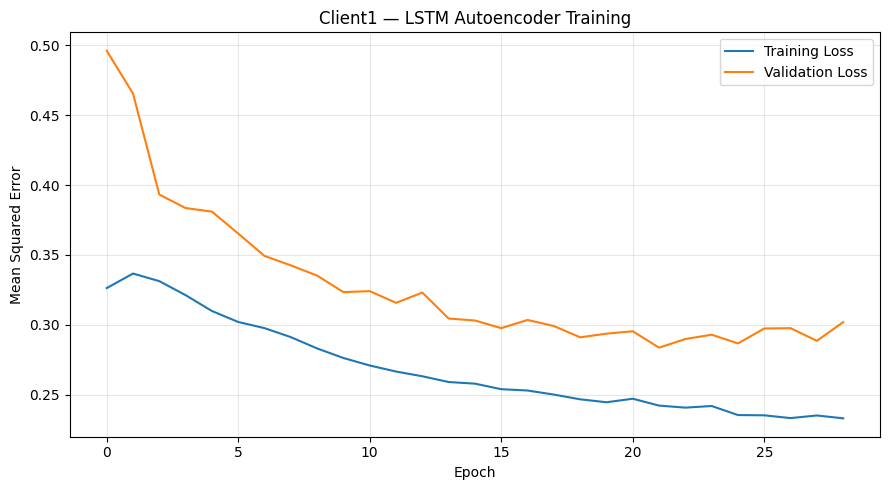


TRAINING MODEL: Client2

Training shape: (115881, 30, 7)
Validation shape: (24823, 30, 7)
Number of features: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 7)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 7)          │           455 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,455 (251.78 KB)

 Trainable params: 64,455 (251.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 51s 13ms/step - loss: 0.4606 - val_loss: 0.3898
Epoch 2/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4851 - val_loss: 0.3738
Epoch 3/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4771 - val_loss: 0.3337
Epoch 4/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4829 - val_loss: 0.3192
Epoch 5/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4751 - val_loss: 0.3230
Epoch 6/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4771 - val_loss: 0.3309
Epoch 7/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4831 - val_loss: 0.3446
Epoch 8/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4776 - val_loss: 0.3303
Epoch 9/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4716 - val_loss: 0.2843
Epoch 10/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4667 - val_loss: 0.3258
Epoch 11/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4661 - val_loss: 0.2776
Epoch 12

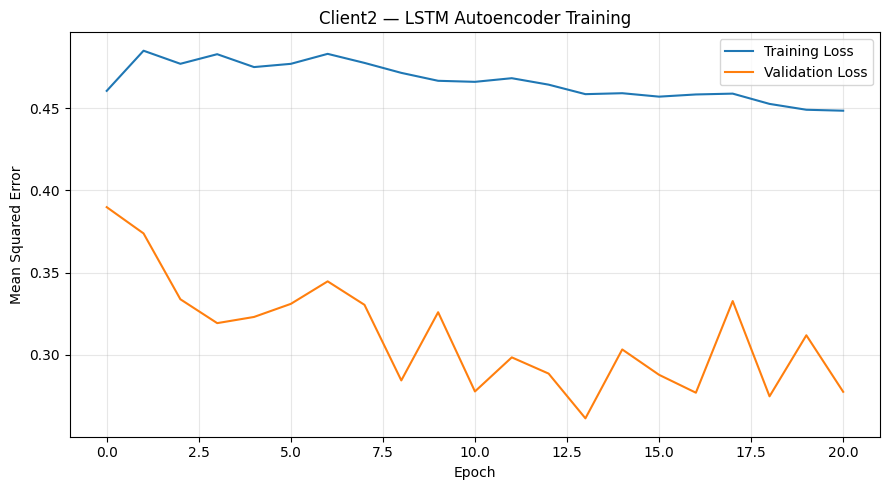


TRAINING MODEL: Client3

Training shape: (115740, 30, 7)
Validation shape: (24791, 30, 7)
Number of features: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 7)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 7)          │           455 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,455 (251.78 KB)

 Trainable params: 64,455 (251.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 47s 12ms/step - loss: 0.5096 - val_loss: 0.4676
Epoch 2/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - loss: 0.5101 - val_loss: 0.4850
Epoch 3/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 45s 12ms/step - loss: 0.5307 - val_loss: 0.4608
Epoch 4/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - loss: 0.5109 - val_loss: 0.4613
Epoch 5/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - loss: 0.5046 - val_loss: 0.4619
Epoch 6/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 45s 12ms/step - loss: 0.5105 - val_loss: 0.4587
Epoch 7/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - loss: 0.4910 - val_loss: 0.4888
Epoch 8/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 43s 12ms/step - loss: 0.5089 - val_loss: 0.4516
Epoch 9/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 43s 12ms/step - loss: 0.4937 - val_loss: 0.5201
Epoch 10/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 43s 12ms/step - loss: 0.4986 - val_loss: 0.5534
Epoch 11/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - loss: 0.4952 - val_loss: 0.5041
Epoch 12

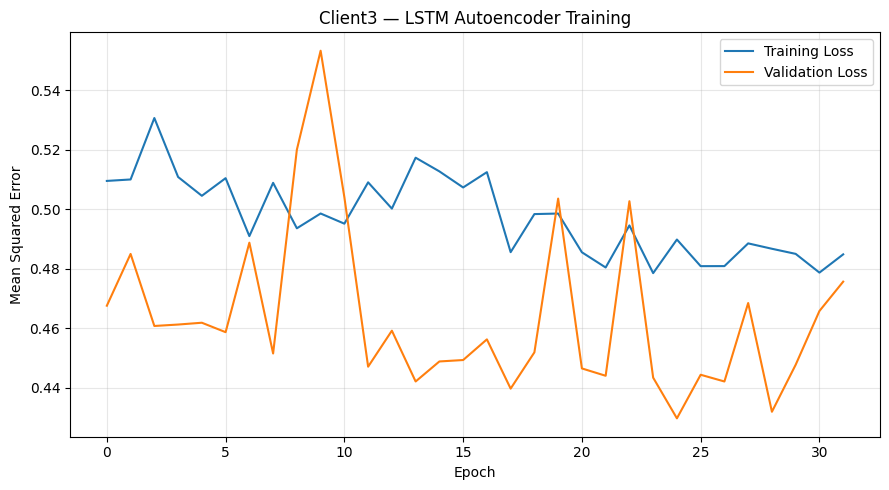


TRAINING MODEL: Switch

Training shape: (103187, 30, 4)
Validation shape: (22102, 30, 4)
Number of features: 4


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 4)          │           260 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,492 (248.02 KB)

 Trainable params: 63,492 (248.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 41s 12ms/step - loss: 0.4169 - val_loss: 0.5311
Epoch 2/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 38s 12ms/step - loss: 0.4505 - val_loss: 0.6187
Epoch 3/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 38s 12ms/step - loss: 0.4206 - val_loss: 0.5680
Epoch 4/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 38s 12ms/step - loss: 0.3826 - val_loss: 0.5004
Epoch 5/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 38s 12ms/step - loss: 0.3632 - val_loss: 0.3995
Epoch 6/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - loss: 0.3538 - val_loss: 0.3972
Epoch 7/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - loss: 0.3523 - val_loss: 0.4051
Epoch 8/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - loss: 0.3496 - val_loss: 0.4188
Epoch 9/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - loss: 0.3491 - val_loss: 0.4004
Epoch 10/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - loss: 0.3254 - val_loss: 0.4362
Epoch 11/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 39s 12ms/step - loss: 0.3188 - val_loss: 0.3953
Epoch 12

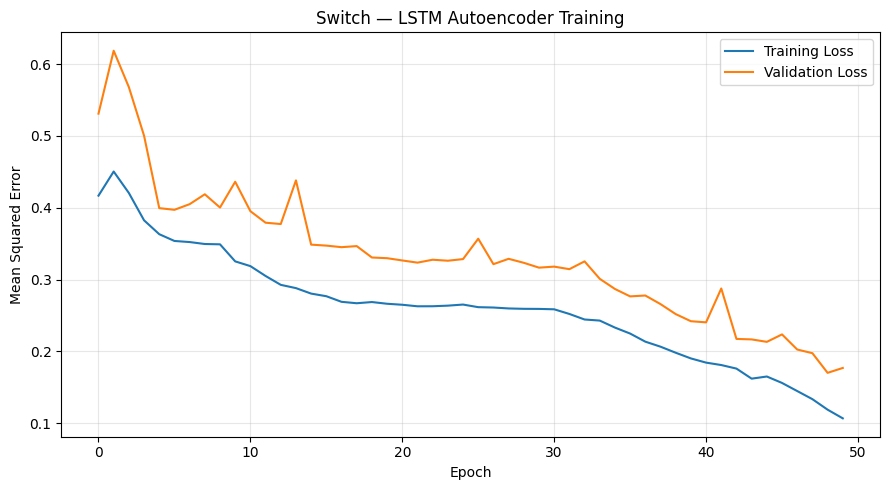


SECTION 5 COMPLETE

Training Summary:
 Device  Epochs_Completed  Best_Epoch  Final_Training_Loss  Best_Validation_Loss  Features  Sequences
Client1                29          22             0.233239              0.283748         7     115901
Client2                21          14             0.448533              0.261245         7     115881
Client3                32          25             0.484886              0.429742         7     115740
 Switch                50          49             0.106824              0.170183         4     103187

All models saved to: LSTM_Results\Models
Training summary saved to: LSTM_Results\Training_Summary.csv


In [5]:
# ============================================================
# SECTION 5 — BUILD AND TRAIN LSTM AUTOENCODER
# ============================================================

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, RepeatVector, TimeDistributed, Dense
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K

import gc

# ------------------------------------------------------------
# 5.1 Build the LSTM Autoencoder
# ------------------------------------------------------------

def build_lstm_autoencoder(sequence_length, n_features):
    """
    Build an LSTM Autoencoder.

    Input:
        (30, 7) for Raspberry Pis
        (30, 4) for Switch

    Output:
        Reconstructed sequence with the same shape.
    """

    inputs = Input(
        shape=(sequence_length, n_features)
    )

    # Encoder
    x = LSTM(
        64,
        activation="tanh",
        return_sequences=True
    )(inputs)

    x = LSTM(
        32,
        activation="tanh",
        return_sequences=False
    )(x)

    # Repeat encoded representation
    x = RepeatVector(sequence_length)(x)

    # Decoder
    x = LSTM(
        32,
        activation="tanh",
        return_sequences=True
    )(x)

    x = LSTM(
        64,
        activation="tanh",
        return_sequences=True
    )(x)

    # Reconstruct original features
    outputs = TimeDistributed(
        Dense(n_features)
    )(x)

    model = Model(inputs, outputs)

    # Compile model
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="mse"
    )

    return model


# ------------------------------------------------------------
# 5.2 Prepare model storage
# ------------------------------------------------------------

models = {}
training_history = {}
training_summary = []

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 5.3 Train each device independently
# ------------------------------------------------------------

for device, data in sequence_data.items():

    print("\n" + "=" * 60)
    print(f"TRAINING MODEL: {device}")
    print("=" * 60)

    # Clear previous TensorFlow graphs
    K.clear_session()

    # Retrieve sequences
    X_train = data["train"]
    X_val = data["val"]

    # Automatically detect input dimensions
    sequence_length = X_train.shape[1]
    n_features = X_train.shape[2]

    print("\nTraining shape:", X_train.shape)
    print("Validation shape:", X_val.shape)
    print("Number of features:", n_features)

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_lstm_autoencoder(
        sequence_length=sequence_length,
        n_features=n_features
    )

    model.summary()

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )

    # --------------------------------------------------------
    # Train model
    # --------------------------------------------------------

    history = model.fit(
        X_train,
        X_train,

        validation_data=(X_val, X_val),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=[early_stopping],

        shuffle=False,
        verbose=1
    )

    # --------------------------------------------------------
    # Save trained model
    # --------------------------------------------------------

    model_path = MODEL_DIR / f"{device}_LSTM_Autoencoder.keras"

    model.save(model_path)

    models[device] = model

    training_history[device] = history.history

    # --------------------------------------------------------
    # Record training results
    # --------------------------------------------------------

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    best_val_loss = float(
        np.min(history.history["val_loss"])
    )

    final_train_loss = float(
        history.history["loss"][-1]
    )

    training_summary.append({
        "Device": device,
        "Epochs_Completed": len(history.history["loss"]),
        "Best_Epoch": best_epoch,
        "Final_Training_Loss": final_train_loss,
        "Best_Validation_Loss": best_val_loss,
        "Features": n_features,
        "Sequences": len(X_train)
    })

    print("\nTraining Results:")
    print("Epochs completed:", len(history.history["loss"]))
    print("Best epoch:", best_epoch)
    print("Final training loss:", round(final_train_loss, 6))
    print("Best validation loss:", round(best_val_loss, 6))

    print("\nModel saved:", model_path)

    # --------------------------------------------------------
    # Plot training history
    # --------------------------------------------------------

    plt.figure(figsize=(9, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{device} — LSTM Autoencoder Training")
    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plot_path = PLOTS_DIR / f"{device}_Training_Loss.png"

    plt.savefig(plot_path, dpi=150)
    plt.show()
    plt.close()

    # Release temporary training objects
    del history, X_train, X_val
    gc.collect()


# ============================================================
# 5.4 FINAL TRAINING SUMMARY
# ============================================================

training_summary_df = pd.DataFrame(training_summary)

summary_path = OUTPUT_DIR / "Training_Summary.csv"

training_summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 60)
print("SECTION 5 COMPLETE")
print("=" * 60)

print("\nTraining Summary:")
print(training_summary_df.to_string(index=False))

print("\nAll models saved to:", MODEL_DIR)
print("Training summary saved to:", summary_path)

6 - Split and scale data


DEVICE: Client1

Anomaly threshold: 1.626298

Test Results:
Total sequences: 24827
Anomalous sequences: 330
Anomaly rate: 1.33%

Reconstruction Error:
Mean: 0.506671
Maximum: 2.190834


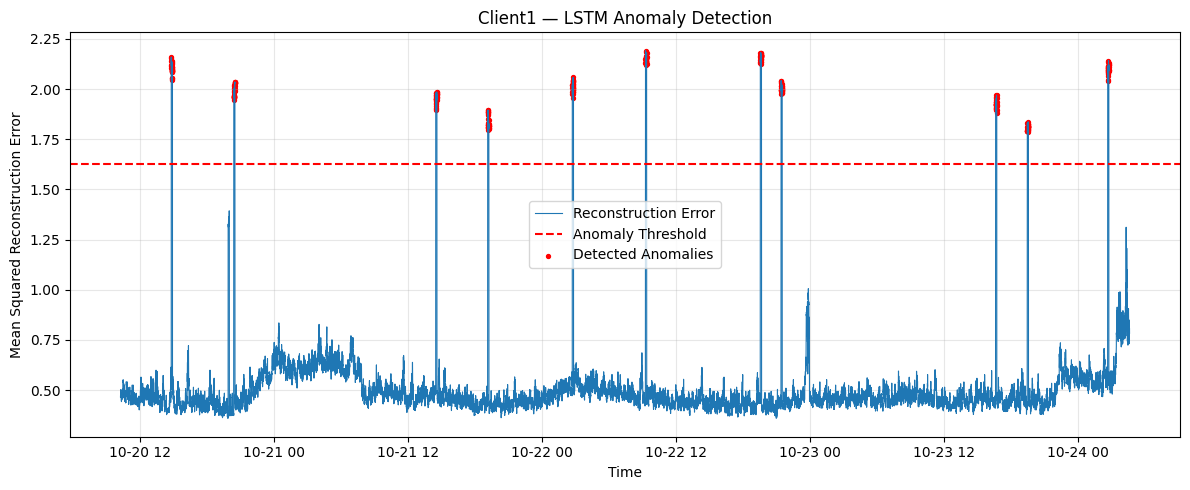


Results saved: LSTM_Results\Anomaly_Results\Client1_Anomaly_Results.csv

DEVICE: Client2

Anomaly threshold: 1.437925

Test Results:
Total sequences: 24824
Anomalous sequences: 826
Anomaly rate: 3.33%

Reconstruction Error:
Mean: 0.540374
Maximum: 4.212047


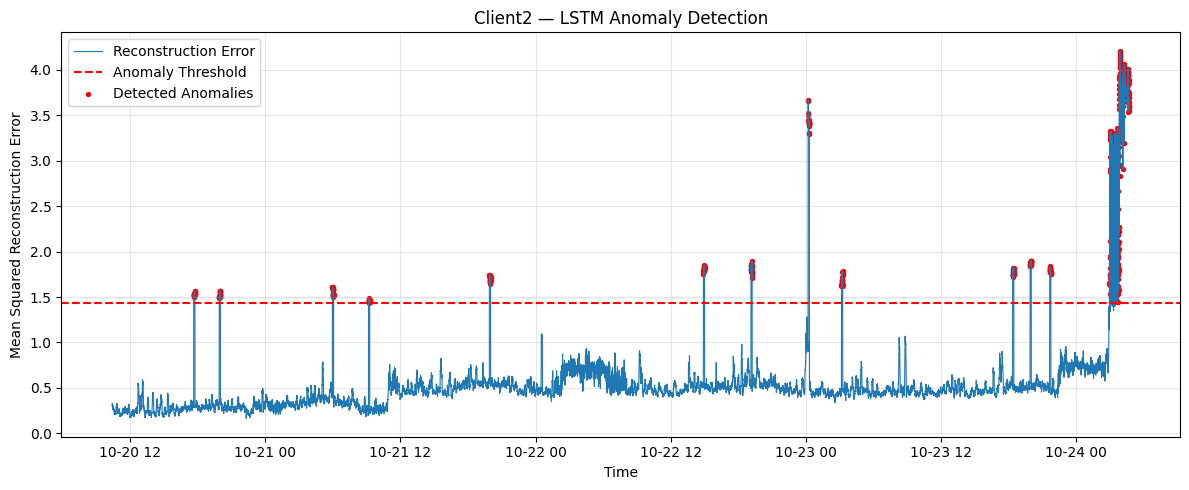


Results saved: LSTM_Results\Anomaly_Results\Client2_Anomaly_Results.csv

DEVICE: Client3

Anomaly threshold: 2.994029

Test Results:
Total sequences: 24791
Anomalous sequences: 257
Anomaly rate: 1.04%

Reconstruction Error:
Mean: 0.778665
Maximum: 3.912889


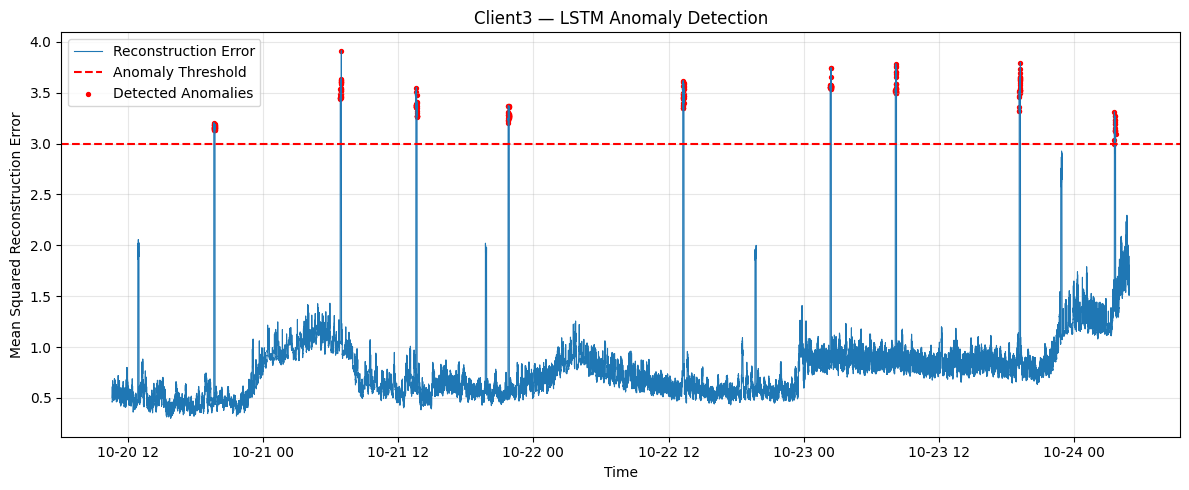


Results saved: LSTM_Results\Anomaly_Results\Client3_Anomaly_Results.csv

DEVICE: Switch

Anomaly threshold: 0.624612

Test Results:
Total sequences: 22045
Anomalous sequences: 327
Anomaly rate: 1.48%

Reconstruction Error:
Mean: 0.175652
Maximum: 1.465546


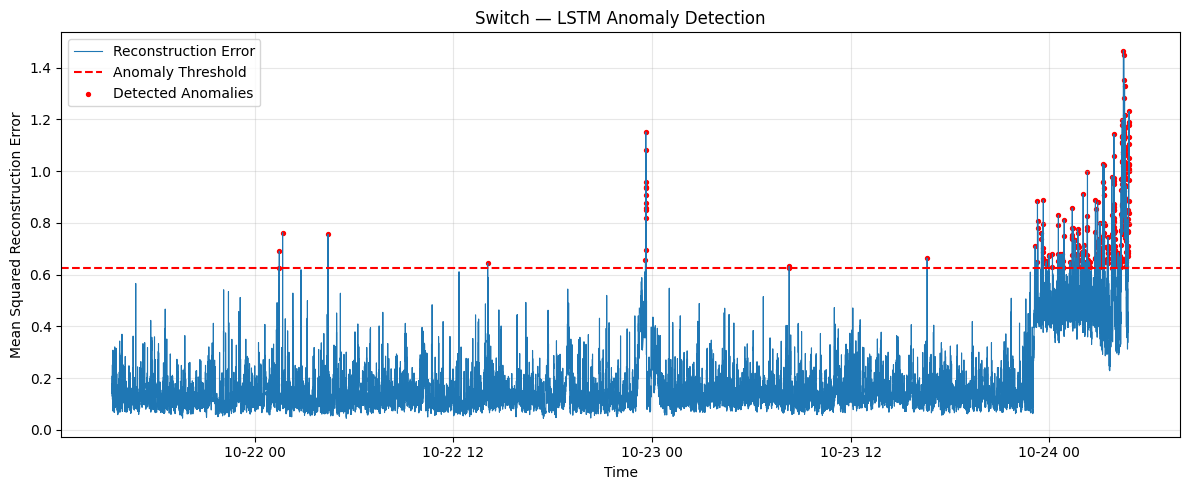


Results saved: LSTM_Results\Anomaly_Results\Switch_Anomaly_Results.csv

SECTION 6 COMPLETE

Anomaly Detection Summary:
 Device  Test_Sequences  Anomalous_Sequences  Anomaly_Rate_Percent  Threshold  Mean_Test_Error  Max_Test_Error
Client1           24827                  330              1.329198   1.626298         0.506671        2.190834
Client2           24824                  826              3.327425   1.437925         0.540374        4.212047
Client3           24791                  257              1.036667   2.994029         0.778665        3.912889
 Switch           22045                  327              1.483330   0.624612         0.175652        1.465546

Results saved to: LSTM_Results\Anomaly_Results
Plots saved to: LSTM_Results\Plots


In [6]:
# ============================================================
# SECTION 6 — ANOMALY DETECTION AND EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model

# ------------------------------------------------------------
# 6.1 Configuration
# ------------------------------------------------------------

ANOMALY_PERCENTILE = 99
PREDICTION_BATCH_SIZE = 256

# Store results
anomaly_results = {}
anomaly_summary = []
anomaly_thresholds = {}

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 6.2 Calculate reconstruction errors
# ------------------------------------------------------------

def calculate_reconstruction_errors(model, X):
    """
    Reconstruct LSTM sequences and calculate:

    1. Total MSE for each sequence
    2. MSE for each original metric

    Returns:
        sequence_errors: (number of sequences,)
        feature_errors:  (number of sequences, metrics)
    """

    # Allocate output arrays
    sequence_errors = np.empty(
        len(X), dtype=np.float64
    )

    feature_errors = np.empty(
        (len(X), X.shape[2]), dtype=np.float64
    )

    # Predict in batches to reduce memory usage
    for start in range(0, len(X), PREDICTION_BATCH_SIZE):

        end = min(start + PREDICTION_BATCH_SIZE, len(X))

        batch = X[start:end]

        reconstructed = model.predict(
            batch,
            batch_size=PREDICTION_BATCH_SIZE,
            verbose=0
        )

        # Squared reconstruction error
        squared_error = (
            batch.astype(np.float64)
            - reconstructed.astype(np.float64)
        ) ** 2

        # Average error across time and metrics
        sequence_errors[start:end] = squared_error.mean(
            axis=(1, 2)
        )

        # Average error across time for each metric
        feature_errors[start:end] = squared_error.mean(
            axis=1
        )

    return sequence_errors, feature_errors


# ------------------------------------------------------------
# 6.3 Process each device
# ------------------------------------------------------------

for device, data in sequence_data.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    # Load trained model if not already in memory
    if device in models:
        model = models[device]
    else:
        model_path = (
            MODEL_DIR / f"{device}_LSTM_Autoencoder.keras"
        )
        model = load_model(model_path)

    X_val = data["val"]
    X_test = data["test"]

    metrics = data["metrics"]

    # --------------------------------------------------------
    # Calculate validation reconstruction error
    # --------------------------------------------------------

    val_errors, _ = calculate_reconstruction_errors(
        model, X_val
    )

    # Determine anomaly threshold from validation only
    threshold = float(
        np.percentile(val_errors, ANOMALY_PERCENTILE)
    )

    anomaly_thresholds[device] = threshold

    print("\nAnomaly threshold:", round(threshold, 6))

    # --------------------------------------------------------
    # Calculate test reconstruction error
    # --------------------------------------------------------

    test_errors, feature_errors = (
        calculate_reconstruction_errors(model, X_test)
    )

    # Identify anomalous sequences
    is_anomaly = test_errors > threshold

    # Metric contributing most to reconstruction error
    highest_feature_index = np.argmax(
        feature_errors, axis=1
    )

    most_unusual_metric = [
        metrics[i] for i in highest_feature_index
    ]

    # --------------------------------------------------------
    # Create timestamped anomaly results
    # --------------------------------------------------------

    results = pd.DataFrame({
        "timestamp": data["test_timestamps"],
        "reconstruction_error": test_errors,
        "threshold": threshold,
        "is_anomaly": is_anomaly,
        "most_unusual_metric": most_unusual_metric
    })

    # Add individual metric reconstruction errors
    for i, metric in enumerate(metrics):
        results[f"{metric}_error"] = feature_errors[:, i]

    # Store results
    anomaly_results[device] = results

    # Save results to CSV
    output_file = (
        RESULTS_DIR / f"{device}_Anomaly_Results.csv"
    )

    results.to_csv(output_file, index=False)

    # --------------------------------------------------------
    # Calculate anomaly statistics
    # --------------------------------------------------------

    total_sequences = len(results)

    anomalous_sequences = int(is_anomaly.sum())

    anomaly_rate = (
        100 * anomalous_sequences / total_sequences
    )

    # Save summary
    anomaly_summary.append({
        "Device": device,
        "Test_Sequences": total_sequences,
        "Anomalous_Sequences": anomalous_sequences,
        "Anomaly_Rate_Percent": anomaly_rate,
        "Threshold": threshold,
        "Mean_Test_Error": float(np.mean(test_errors)),
        "Max_Test_Error": float(np.max(test_errors))
    })

    print("\nTest Results:")
    print("Total sequences:", total_sequences)
    print("Anomalous sequences:", anomalous_sequences)
    print(f"Anomaly rate: {anomaly_rate:.2f}%")

    print("\nReconstruction Error:")
    print("Mean:", round(np.mean(test_errors), 6))
    print("Maximum:", round(np.max(test_errors), 6))

    # --------------------------------------------------------
    # Plot reconstruction error
    # --------------------------------------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        results["timestamp"],
        results["reconstruction_error"],
        label="Reconstruction Error",
        linewidth=0.8
    )

    plt.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Anomaly Threshold"
    )

    plt.scatter(
        results.loc[is_anomaly, "timestamp"],
        results.loc[is_anomaly, "reconstruction_error"],
        color="red",
        s=8,
        label="Detected Anomalies"
    )

    plt.title(f"{device} — LSTM Anomaly Detection")
    plt.xlabel("Time")
    plt.ylabel("Mean Squared Reconstruction Error")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plot_path = (
        PLOTS_DIR / f"{device}_Anomaly_Detection.png"
    )

    plt.savefig(plot_path, dpi=150)
    plt.show()
    plt.close()

    print("\nResults saved:", output_file)


# ============================================================
# 6.4 FINAL ANOMALY SUMMARY
# ============================================================

anomaly_summary_df = pd.DataFrame(anomaly_summary)

summary_path = OUTPUT_DIR / "Anomaly_Summary.csv"

anomaly_summary_df.to_csv(
    summary_path,
    index=False
)

# Save device thresholds
import joblib

joblib.dump(
    anomaly_thresholds,
    MODEL_DIR / "Anomaly_Thresholds.joblib"
)

print("\n" + "=" * 60)
print("SECTION 6 COMPLETE")
print("=" * 60)

print("\nAnomaly Detection Summary:")
print(anomaly_summary_df.to_string(index=False))

print("\nResults saved to:", RESULTS_DIR)
print("Plots saved to:", PLOTS_DIR)

7 - Build LSTM Autoencoder


DEVICE: Client1

Total anomalous sequences: 330
Distinct anomaly events: 11

Event Summary:
 Event_ID                       Start_Time                         End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-20 14:49:06.325889+00:00 2026-10-20 14:55:26.244263+00:00          6.331973                   30    2.159061             1.327593         cpu_pct
        2 2026-10-20 20:24:42.814760+00:00 2026-10-20 20:31:02.686883+00:00          6.331202                   30    2.035008             1.251313         cpu_pct
        3 2026-10-21 14:30:23.583286+00:00 2026-10-21 14:36:43.486423+00:00          6.331719                   30    1.984792             1.220436         cpu_pct
        4 2026-10-21 19:09:26.226833+00:00 2026-10-21 19:15:46.078747+00:00          6.330865                   30    1.895531             1.165550         cpu_pct
        5 2026-10-22 02:44:16.190525+00:00 2026-10-22 02:50:36.361269+00:00          6.

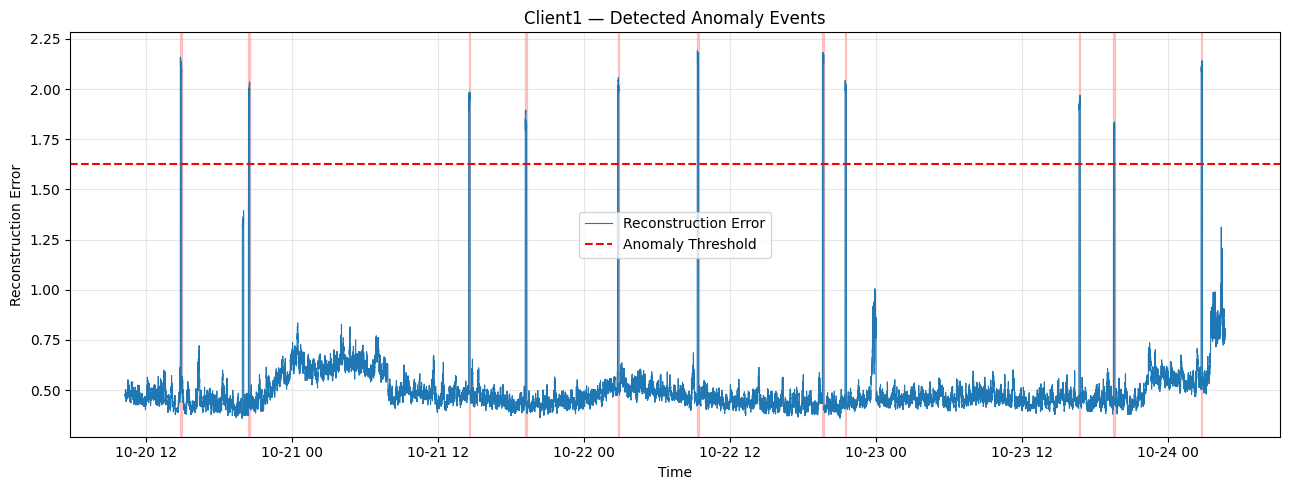


Saved: LSTM_Results\Anomaly_Events\Client1_Events.csv

DEVICE: Client2

Total anomalous sequences: 826
Distinct anomaly events: 18

Event Summary:
 Event_ID                       Start_Time                         End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-20 17:37:48.096361+00:00 2026-10-20 17:44:08.000643+00:00          6.331738                   30    1.565242             1.088542         cpu_pct
        2 2026-10-20 19:53:36.768535+00:00 2026-10-20 19:59:56.672341+00:00          6.331730                   30    1.567047             1.089798         cpu_pct
        3 2026-10-21 05:56:56.992351+00:00 2026-10-21 06:03:16.928159+00:00          6.332263                   30    1.615941             1.123801         cpu_pct
        4 2026-10-21 09:09:45.097908+00:00 2026-10-21 09:16:04.960477+00:00          6.331043                   28    1.491153             1.037017         cpu_pct
        5 2026-10-21 19:54:10.68

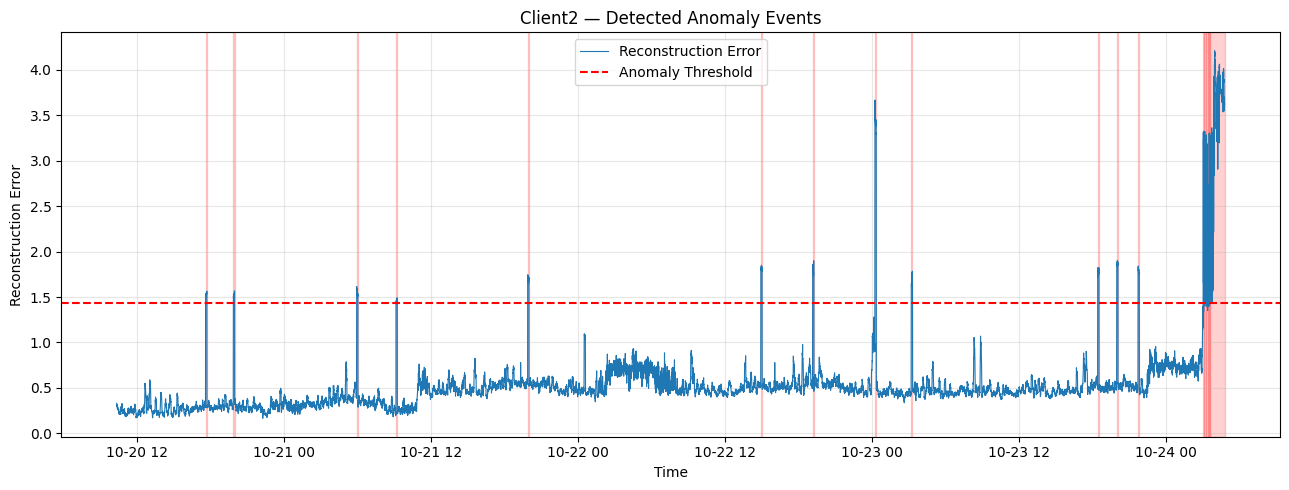


Saved: LSTM_Results\Anomaly_Events\Client2_Events.csv

DEVICE: Client3

Total anomalous sequences: 257
Distinct anomaly events: 15

Event Summary:
 Event_ID                       Start_Time                         End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-20 19:38:25.411188+00:00 2026-10-20 19:44:45.403788+00:00          6.333210                   30    3.205439             1.070611         cpu_pct
        2 2026-10-21 06:51:25.281314+00:00 2026-10-21 06:57:45.243550+00:00          6.332704                   30    3.912889             1.306898         cpu_pct
        3 2026-10-21 13:34:24.689184+00:00 2026-10-21 13:40:44.768914+00:00          6.334662                   30    3.550666             1.185916         cpu_pct
        4 2026-10-21 21:45:23.243634+00:00 2026-10-21 21:51:43.243505+00:00          6.333331                   30    3.373106             1.126611         cpu_pct
        5 2026-10-22 13:15:49.73

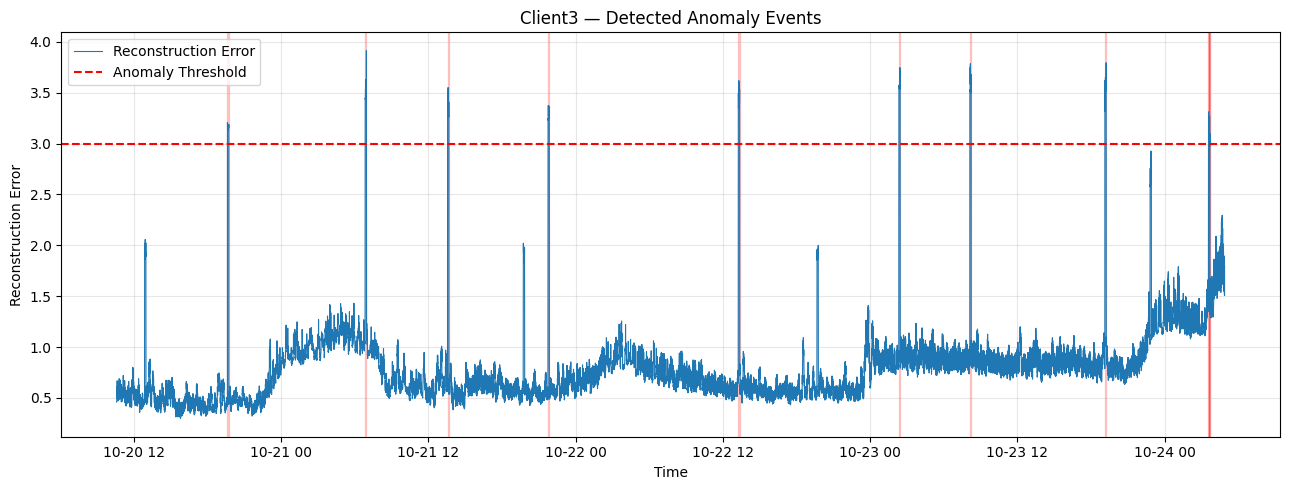


Saved: LSTM_Results\Anomaly_Events\Client3_Events.csv

DEVICE: Switch

Total anomalous sequences: 327
Distinct anomaly events: 95

Event Summary:
 Event_ID                Start_Time                  End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-22 01:29:50+00:00 2026-10-22 01:30:00+00:00          0.166667                    2    0.690590             1.105631         cpu_pct
        2 2026-10-22 01:41:50+00:00 2026-10-22 01:41:50+00:00          0.000000                    1    0.761939             1.219861         cpu_pct
        3 2026-10-22 04:26:30+00:00 2026-10-22 04:26:30+00:00          0.000000                    1    0.755556             1.209642         cpu_pct
        4 2026-10-22 14:04:50+00:00 2026-10-22 14:04:50+00:00          0.000000                    1    0.643892             1.030867         cpu_pct
        5 2026-10-22 23:36:30+00:00 2026-10-22 23:36:30+00:00          0.000000                    1   

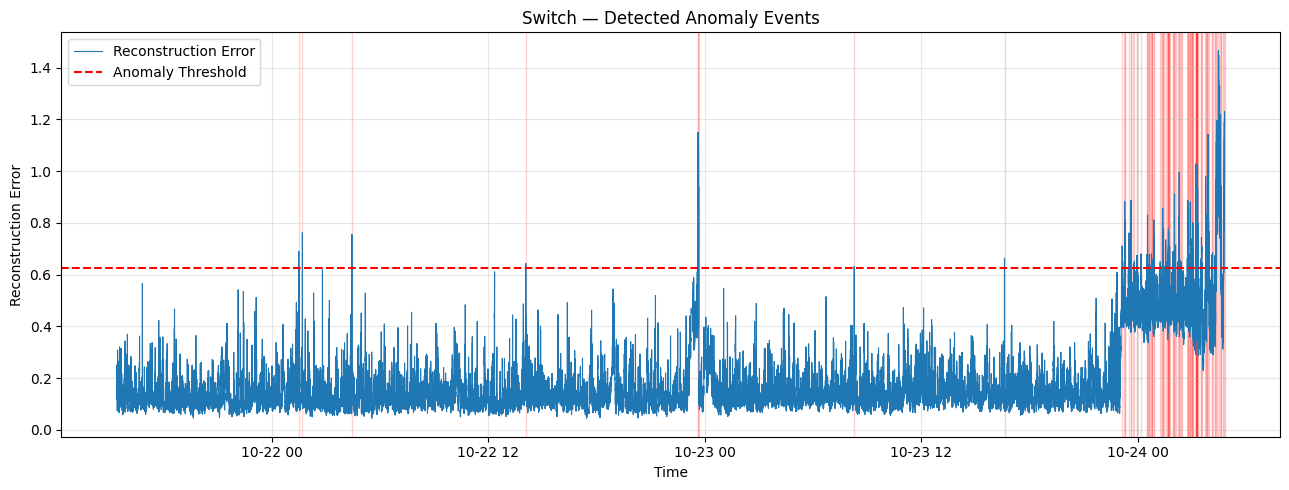


Saved: LSTM_Results\Anomaly_Events\Switch_Events.csv

SECTION 7 COMPLETE

Final Event Summary:
 Device  Total_Events  Anomalous_Sequences  Longest_Event_Minutes  Highest_Severity_Ratio
Client1            11                  330               6.336179                1.347130
Client2            18                  826              73.157709                2.929255
Client3            15                  257               6.334662                1.306898
 Switch            95                  327              17.166667                2.346332


In [7]:
# ============================================================
# SECTION 7 — ANOMALY EVENT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 7.1 Configuration
# ------------------------------------------------------------

# Maximum gap between consecutive anomalous sequence
# timestamps for grouping them into the same event.
EVENT_GAP_SECONDS = {
    "Client1": 30,
    "Client2": 30,
    "Client3": 30,
    "Switch": 20
}

EVENT_DIR = OUTPUT_DIR / "Anomaly_Events"
EVENT_DIR.mkdir(parents=True, exist_ok=True)

event_results = {}
event_summary = []

# ------------------------------------------------------------
# 7.2 Function to group anomalous sequences
# ------------------------------------------------------------

def identify_anomaly_events(results, device, metrics, max_gap):
    """
    Groups consecutive anomalous sequence timestamps into events.

    Returns:
        events: DataFrame containing individual anomaly events
        labelled_results: Original results with event IDs
    """

    df = results.copy()

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], utc=True
    )

    df = df.sort_values("timestamp").reset_index(drop=True)

    # Default: no event assigned
    df["event_id"] = pd.NA

    # Select anomalous sequences only
    anomalies = df[df["is_anomaly"]].copy()

    if anomalies.empty:
        return pd.DataFrame(), df

    # Time between anomalous sequence timestamps
    gaps = anomalies["timestamp"].diff().dt.total_seconds()

    # Start a new event after a large gap
    new_event = gaps.isna() | (gaps > max_gap)

    anomalies["event_id"] = new_event.cumsum().astype(int)

    # Copy event IDs into the full results
    df.loc[anomalies.index, "event_id"] = anomalies["event_id"]

    events = []

    # --------------------------------------------------------
    # 7.3 Summarise individual events
    # --------------------------------------------------------

    for event_id, group in anomalies.groupby("event_id"):

        first_time = group["timestamp"].min()
        last_time = group["timestamp"].max()

        # Duration covered by anomalous sequence end times
        duration_minutes = (
            (last_time - first_time).total_seconds() / 60
        )

        peak_error = group["reconstruction_error"].max()

        threshold = group["threshold"].iloc[0]

        severity_ratio = (
            peak_error / threshold
            if threshold > 0 else np.nan
        )

        # Calculate average reconstruction error for each metric
        metric_errors = {}

        for metric in metrics:
            column = f"{metric}_error"

            if column in group.columns:
                metric_errors[metric] = group[column].mean()

        dominant_metric = (
            max(metric_errors, key=metric_errors.get)
            if metric_errors else "Unknown"
        )

        events.append({
            "Device": device,
            "Event_ID": int(event_id),
            "Start_Time": first_time,
            "End_Time": last_time,
            "Duration_Minutes": duration_minutes,
            "Anomalous_Sequences": len(group),
            "Peak_Error": peak_error,
            "Threshold": threshold,
            "Peak_Severity_Ratio": severity_ratio,
            "Dominant_Metric": dominant_metric
        })

    return pd.DataFrame(events), df


# ------------------------------------------------------------
# 7.4 Analyse each device
# ------------------------------------------------------------

for device, results in anomaly_results.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    metrics = sequence_data[device]["metrics"]

    events, labelled_results = identify_anomaly_events(
        results=results,
        device=device,
        metrics=metrics,
        max_gap=EVENT_GAP_SECONDS[device]
    )

    event_results[device] = events

    # Save event table
    events_file = EVENT_DIR / f"{device}_Events.csv"
    events.to_csv(events_file, index=False)

    # Save sequence results with event IDs
    labelled_file = EVENT_DIR / f"{device}_Labelled_Anomalies.csv"
    labelled_results.to_csv(labelled_file, index=False)

    print("\nTotal anomalous sequences:",
          int(results["is_anomaly"].sum()))

    print("Distinct anomaly events:", len(events))

    if not events.empty:

        print("\nEvent Summary:")
        print(
            events[
                [
                    "Event_ID",
                    "Start_Time",
                    "End_Time",
                    "Duration_Minutes",
                    "Anomalous_Sequences",
                    "Peak_Error",
                    "Peak_Severity_Ratio",
                    "Dominant_Metric"
                ]
            ].to_string(index=False)
        )

        # Store summary
        event_summary.append({
            "Device": device,
            "Total_Events": len(events),
            "Anomalous_Sequences": int(
                results["is_anomaly"].sum()
            ),
            "Longest_Event_Minutes": events[
                "Duration_Minutes"
            ].max(),
            "Highest_Severity_Ratio": events[
                "Peak_Severity_Ratio"
            ].max()
        })

    else:

        event_summary.append({
            "Device": device,
            "Total_Events": 0,
            "Anomalous_Sequences": 0,
            "Longest_Event_Minutes": 0,
            "Highest_Severity_Ratio": 0
        })

    # --------------------------------------------------------
    # 7.5 Plot anomaly events
    # --------------------------------------------------------

    plt.figure(figsize=(13, 5))

    plt.plot(
        labelled_results["timestamp"],
        labelled_results["reconstruction_error"],
        linewidth=0.8,
        label="Reconstruction Error"
    )

    if not events.empty:

        for _, event in events.iterrows():

            plt.axvspan(
                event["Start_Time"],
                event["End_Time"],
                color="red",
                alpha=0.18
            )

    plt.axhline(
        labelled_results["threshold"].iloc[0],
        color="red",
        linestyle="--",
        label="Anomaly Threshold"
    )

    plt.title(f"{device} — Detected Anomaly Events")
    plt.xlabel("Time")
    plt.ylabel("Reconstruction Error")
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()

    plot_file = PLOTS_DIR / f"{device}_Anomaly_Events.png"

    plt.savefig(plot_file, dpi=150)
    plt.show()
    plt.close()

    print("\nSaved:", events_file)


# ============================================================
# 7.6 FINAL SUMMARY
# ============================================================

event_summary_df = pd.DataFrame(event_summary)

event_summary_df.to_csv(
    OUTPUT_DIR / "Event_Summary.csv",
    index=False
)

print("\n" + "=" * 60)
print("SECTION 7 COMPLETE")
print("=" * 60)

print("\nFinal Event Summary:")
print(event_summary_df.to_string(index=False))

8 - 

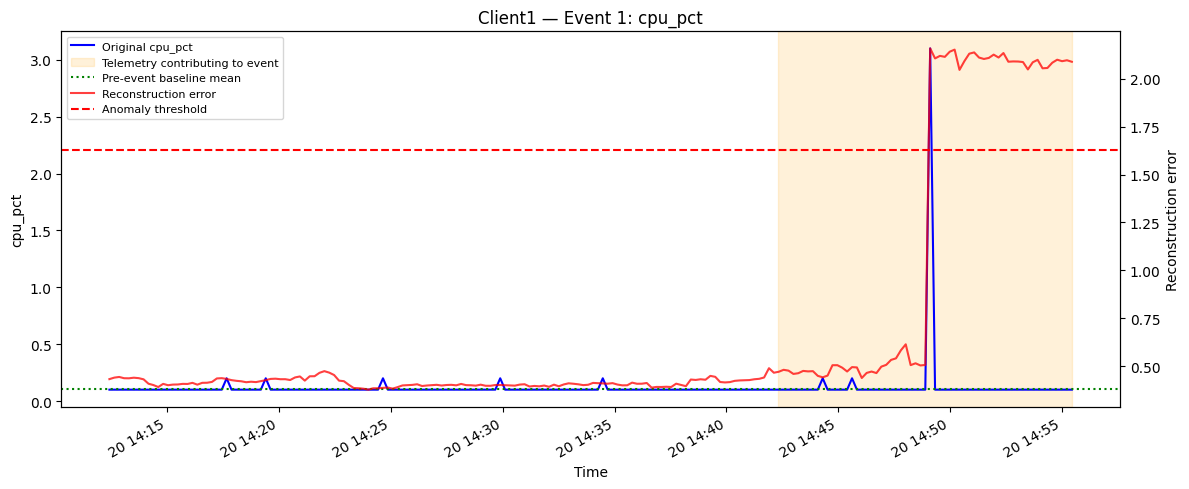

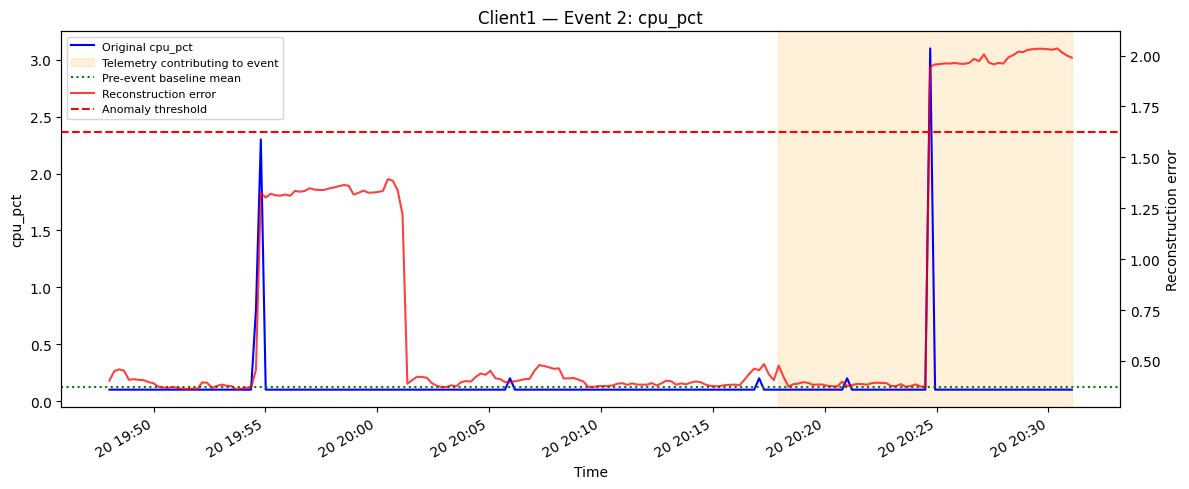

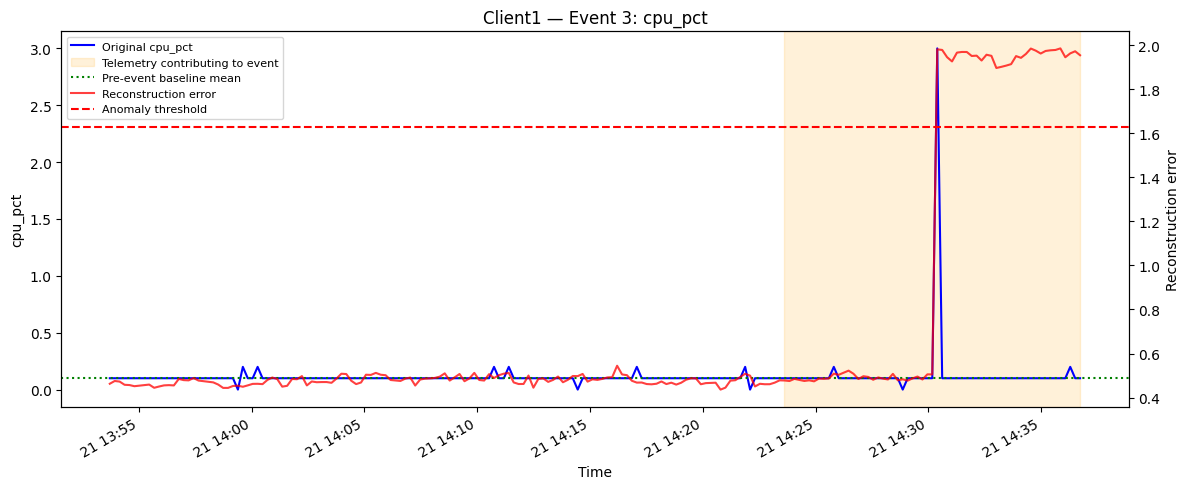

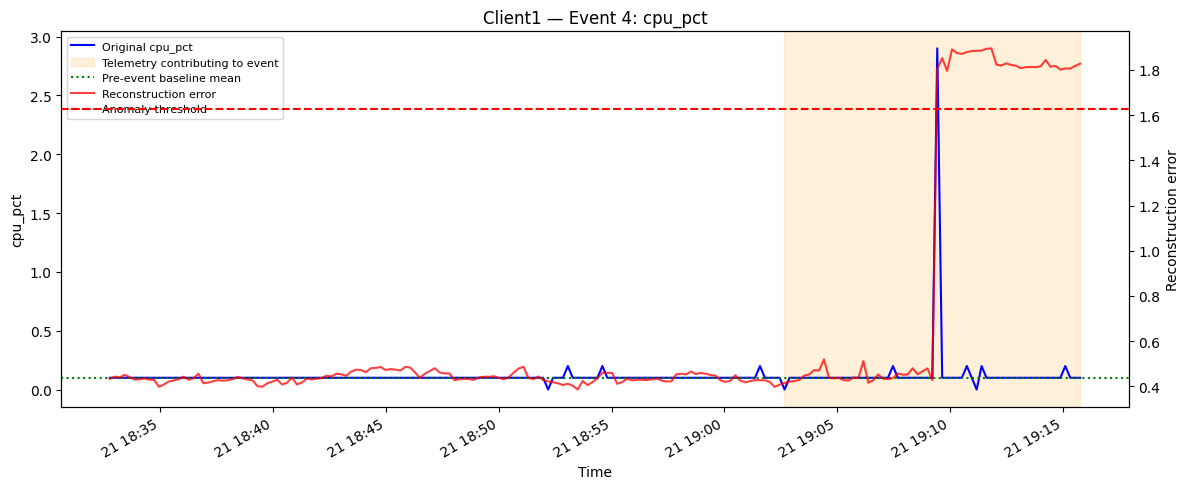

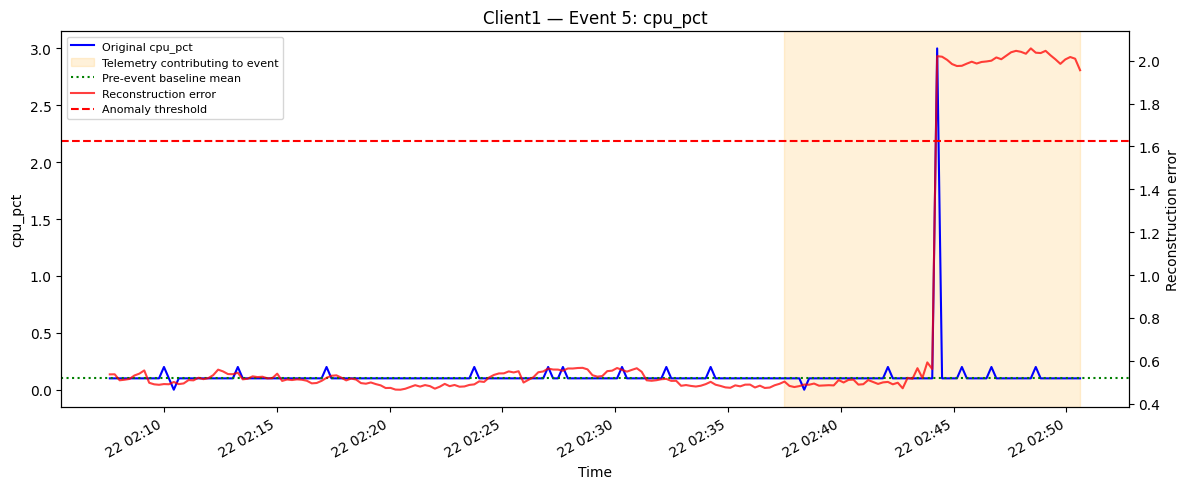

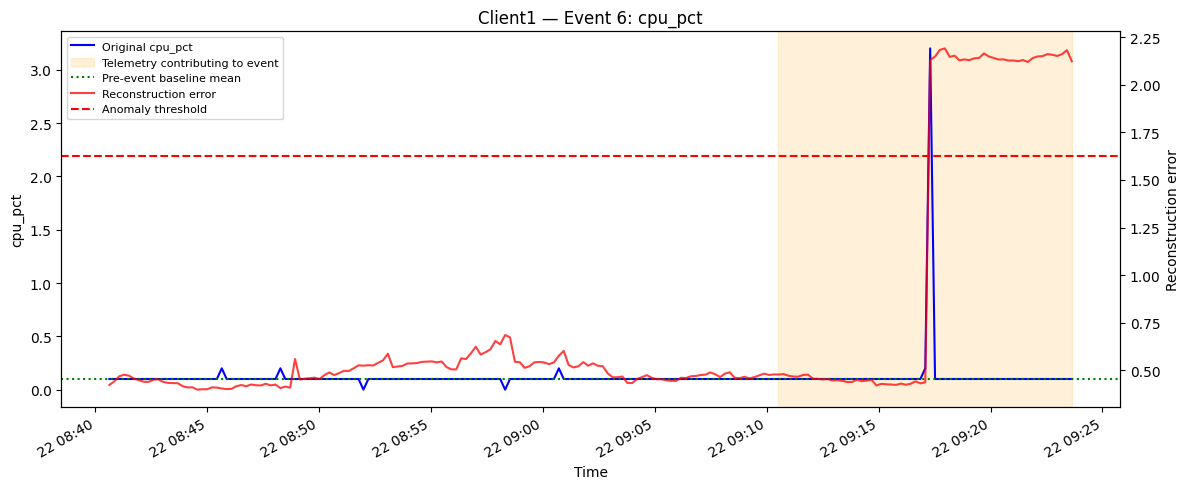

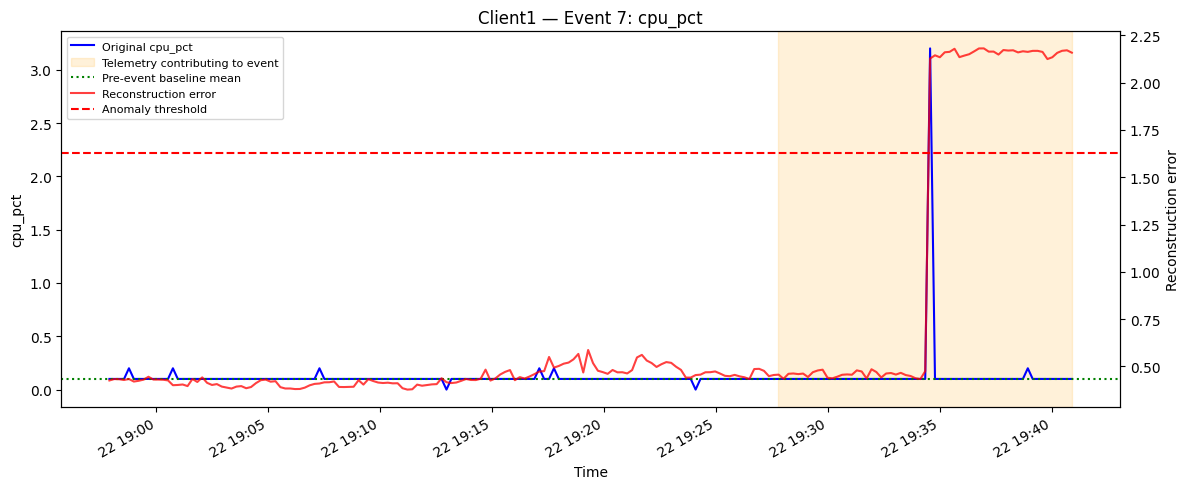

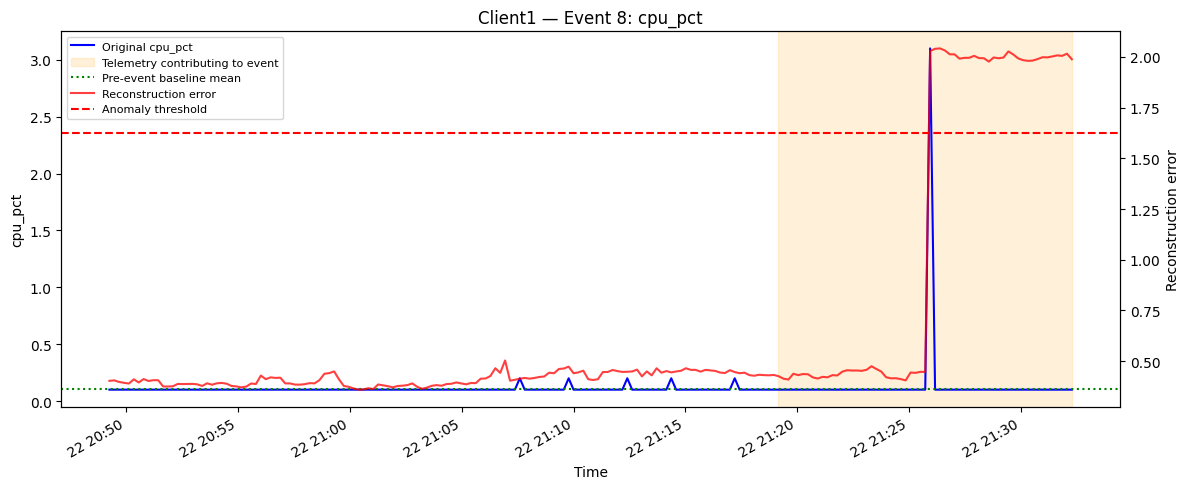

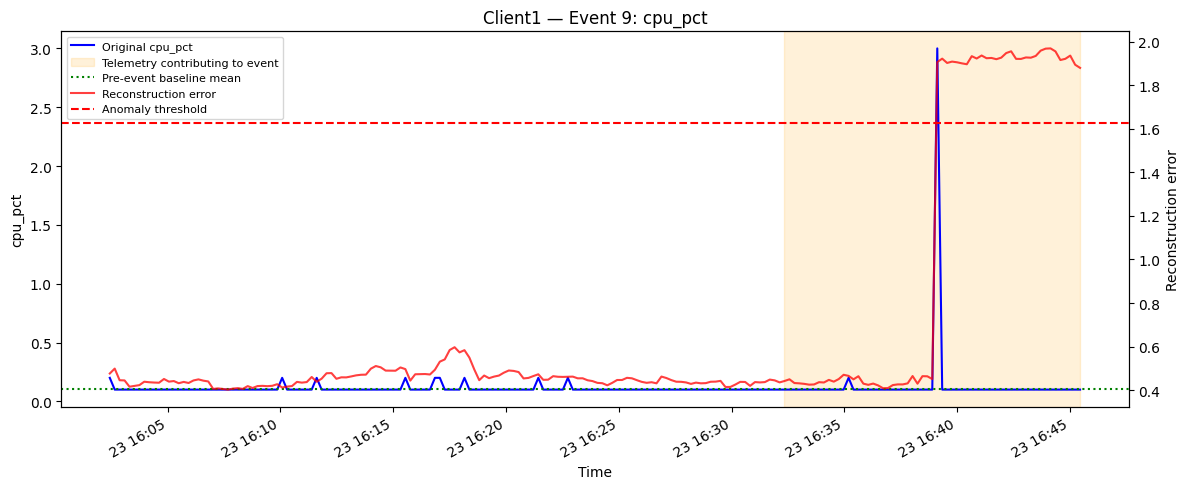

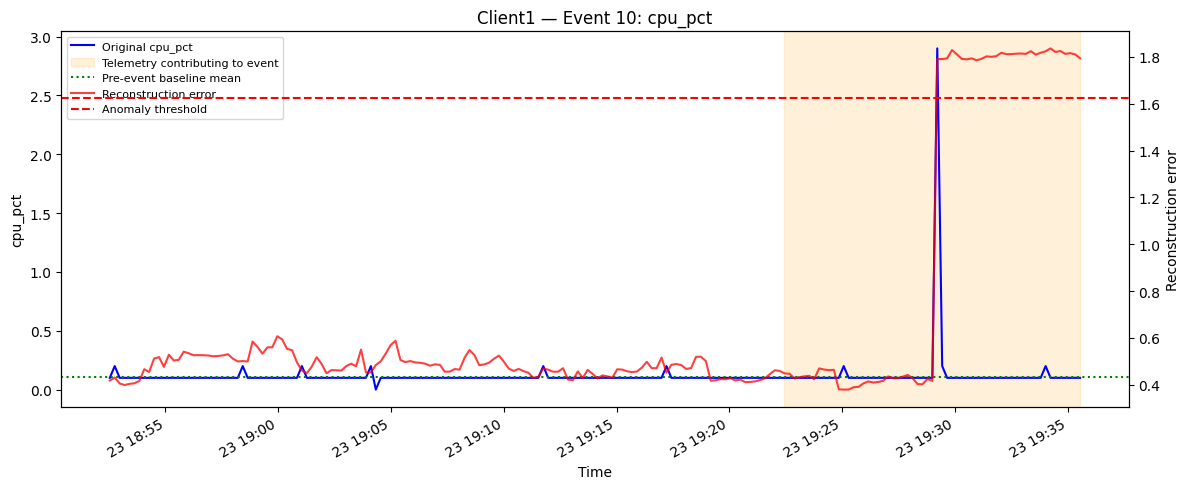

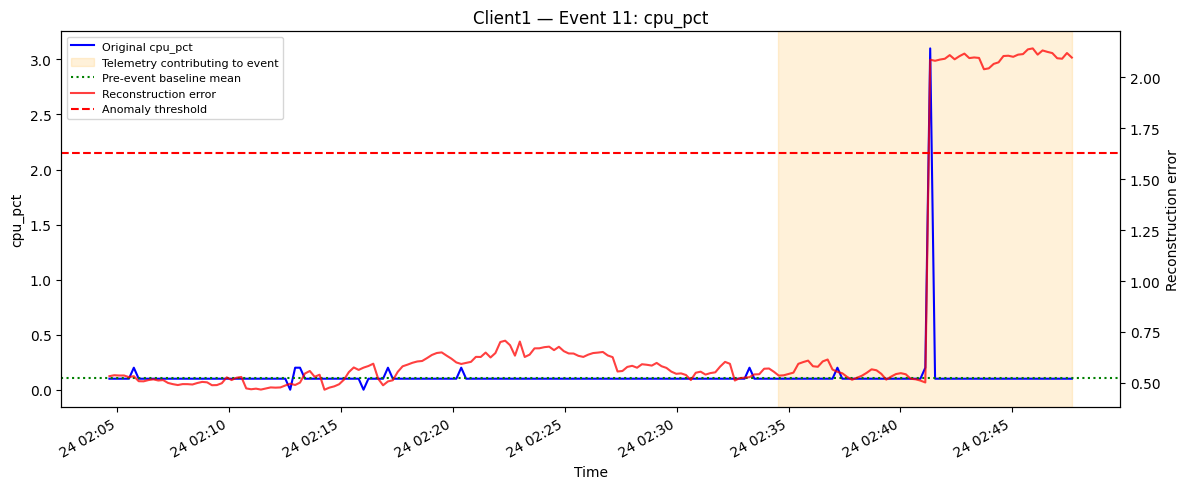

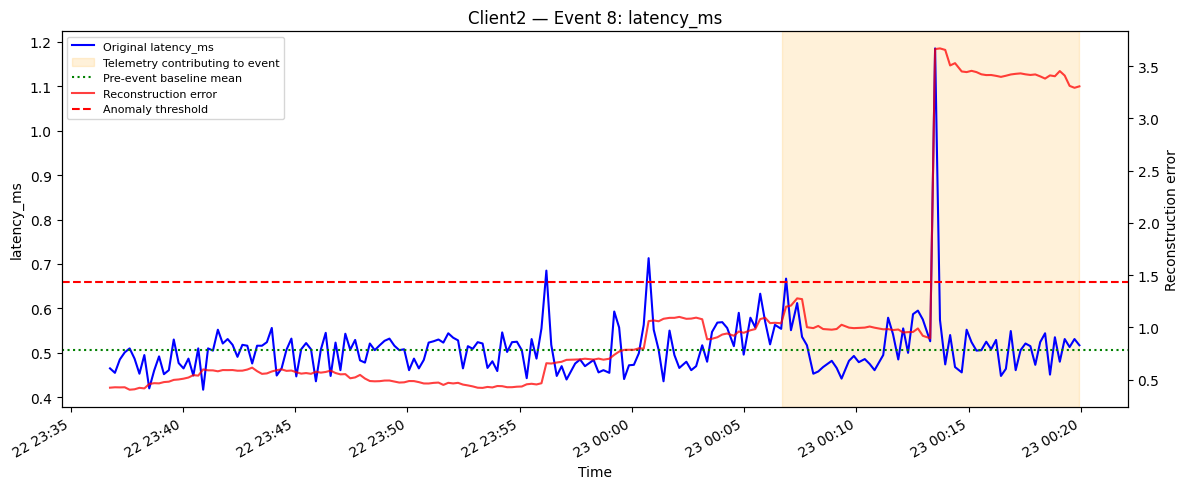

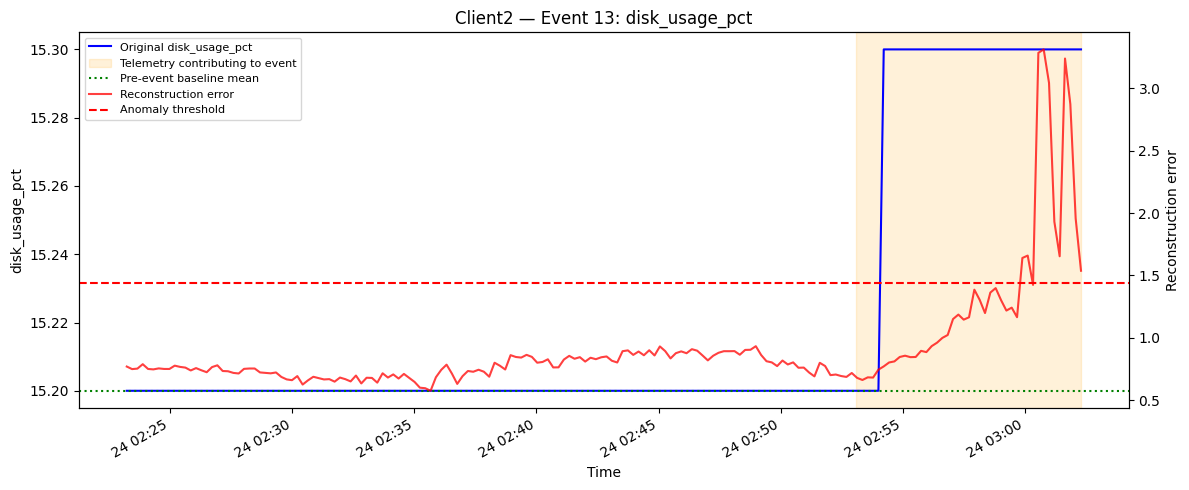

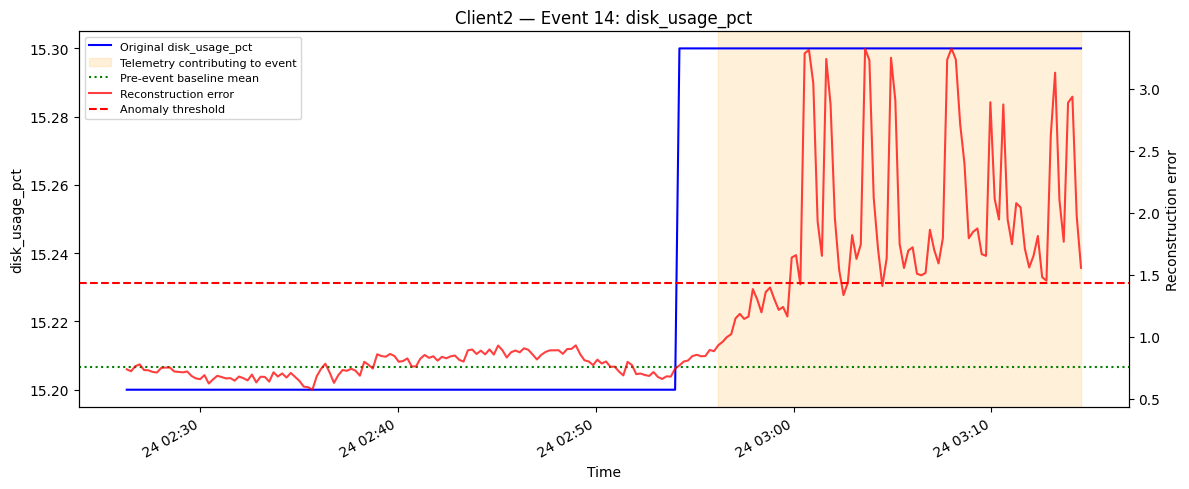

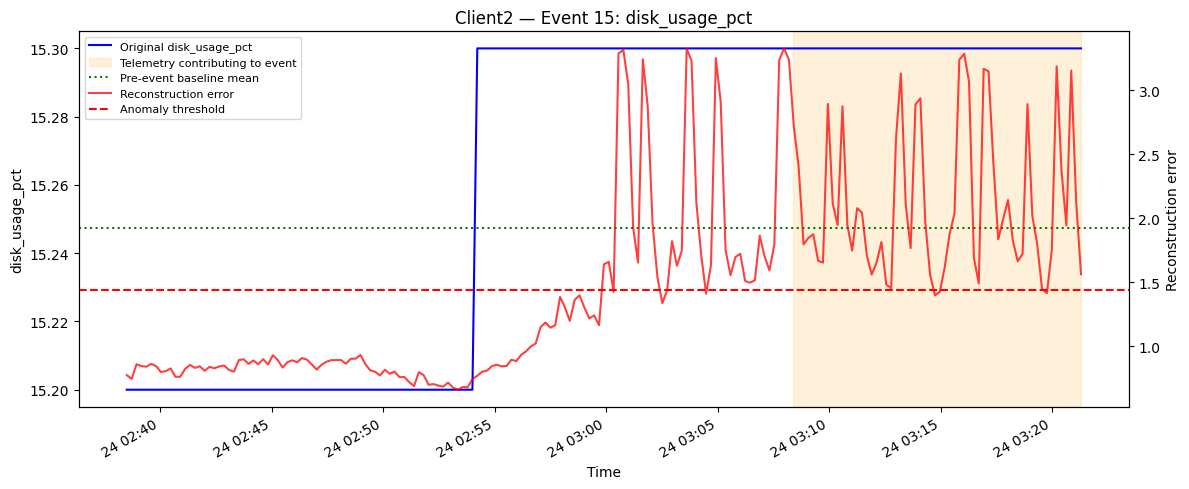

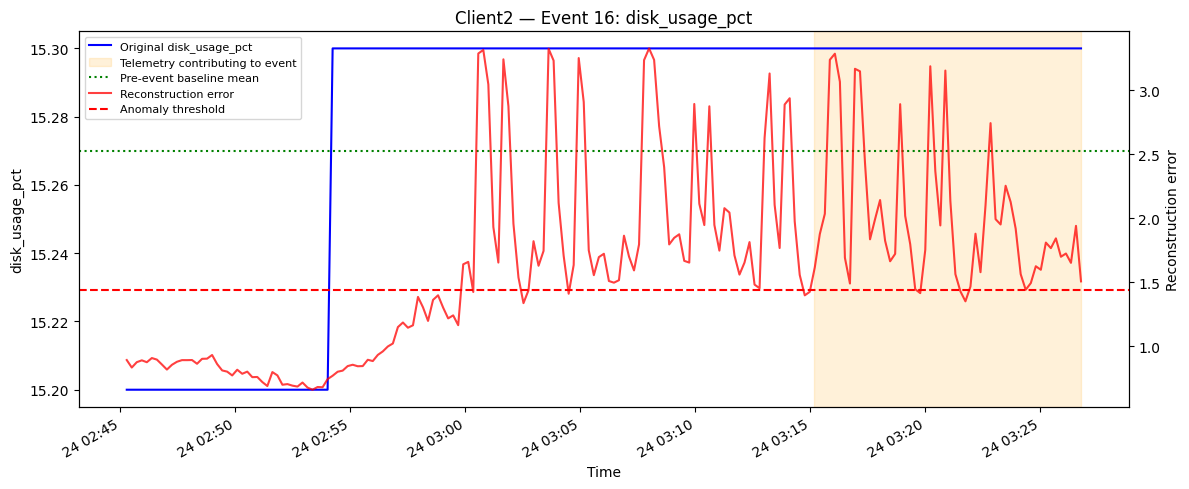

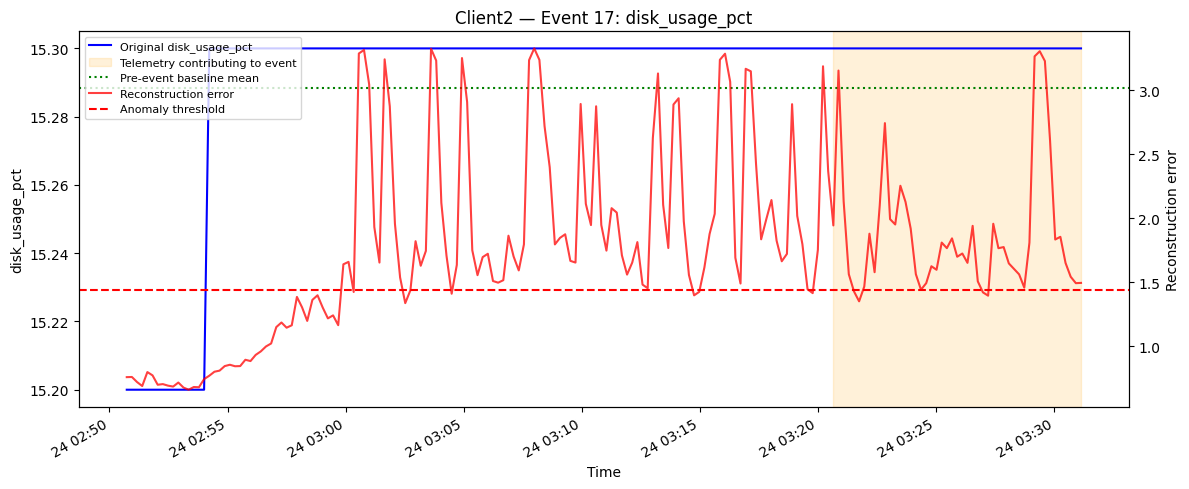

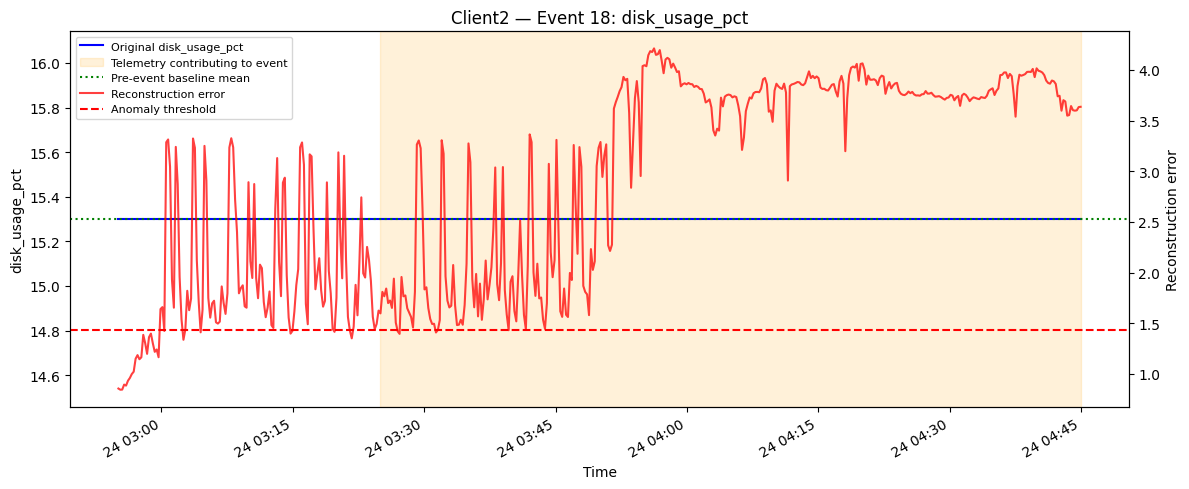

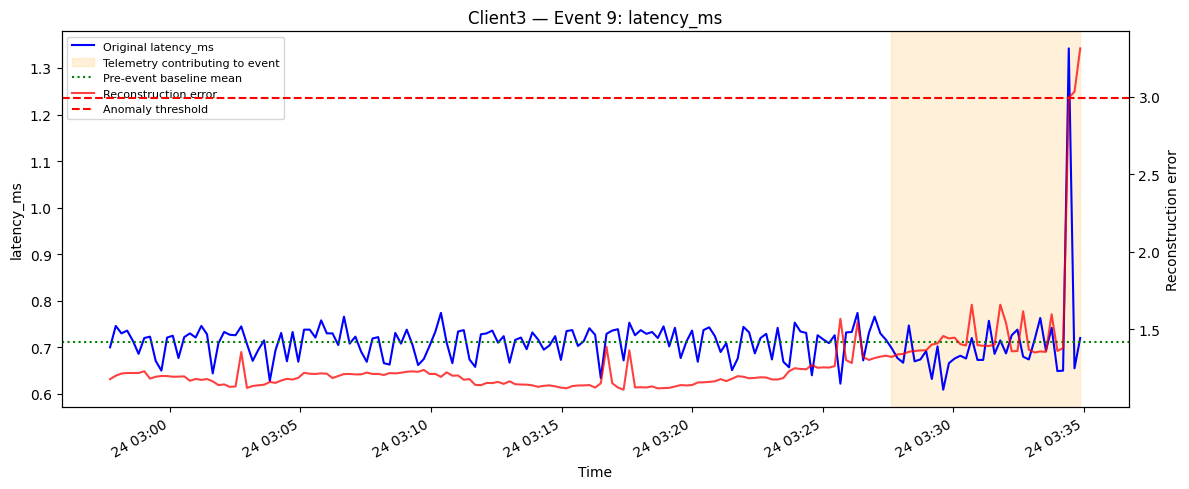

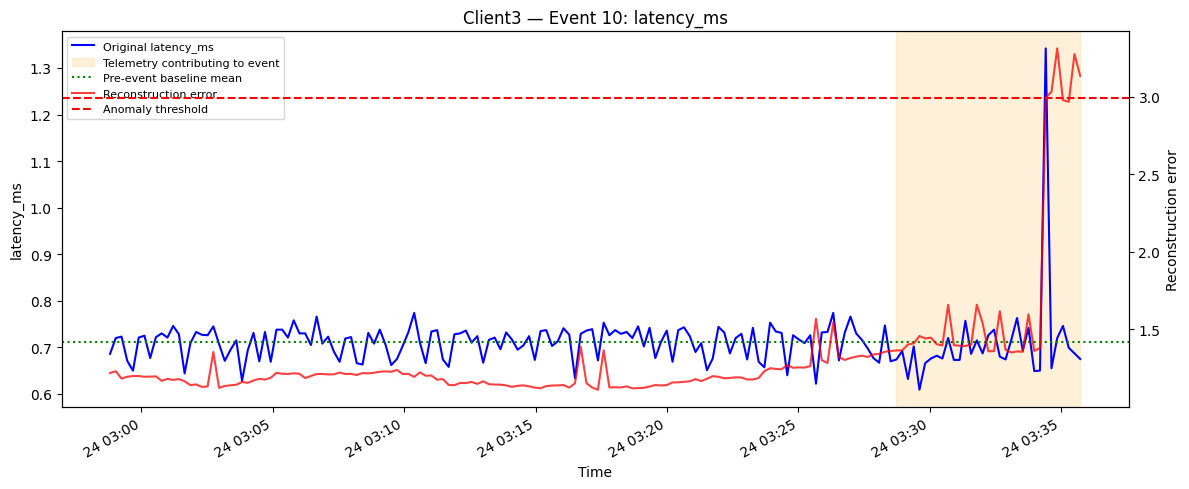

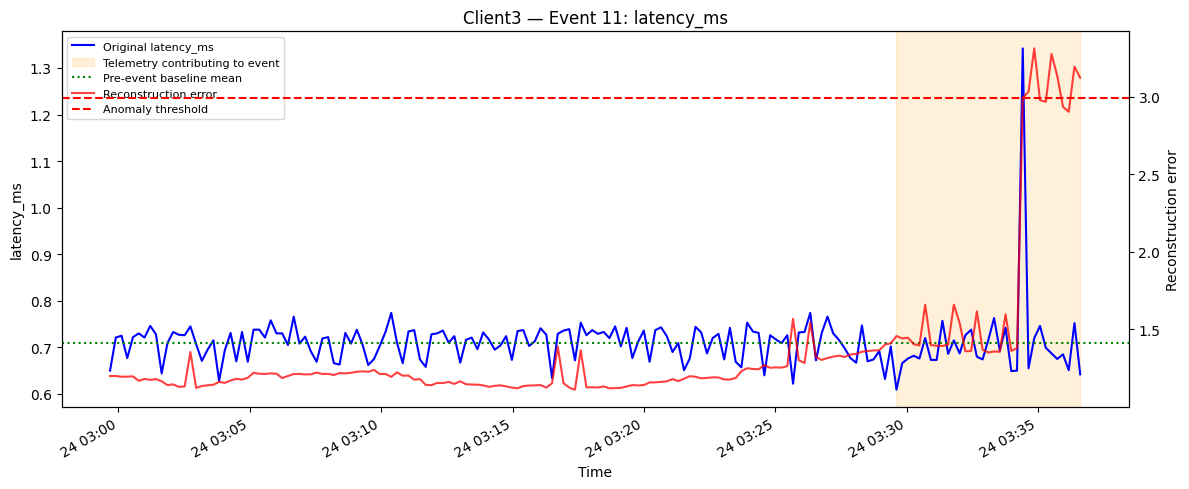

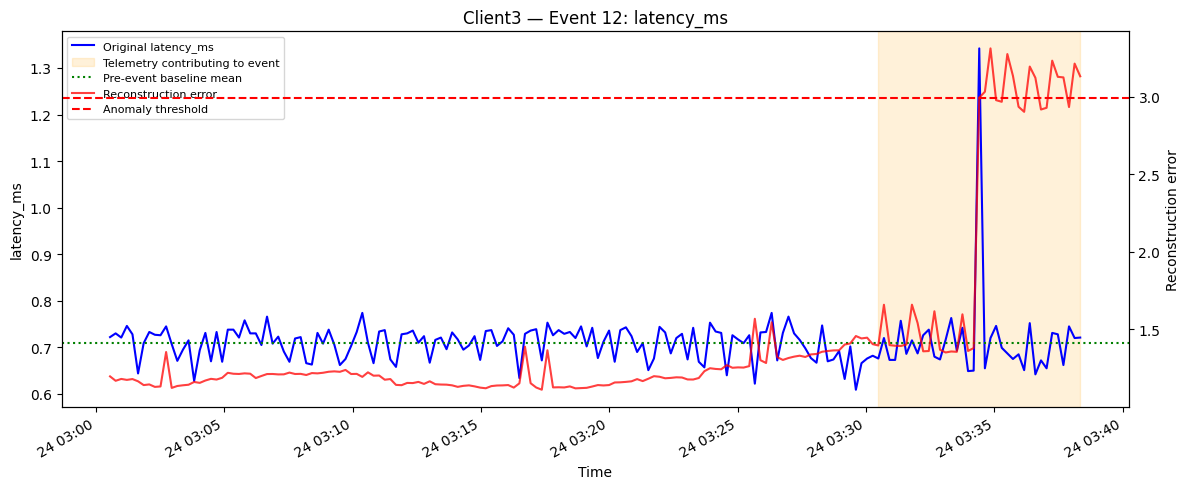

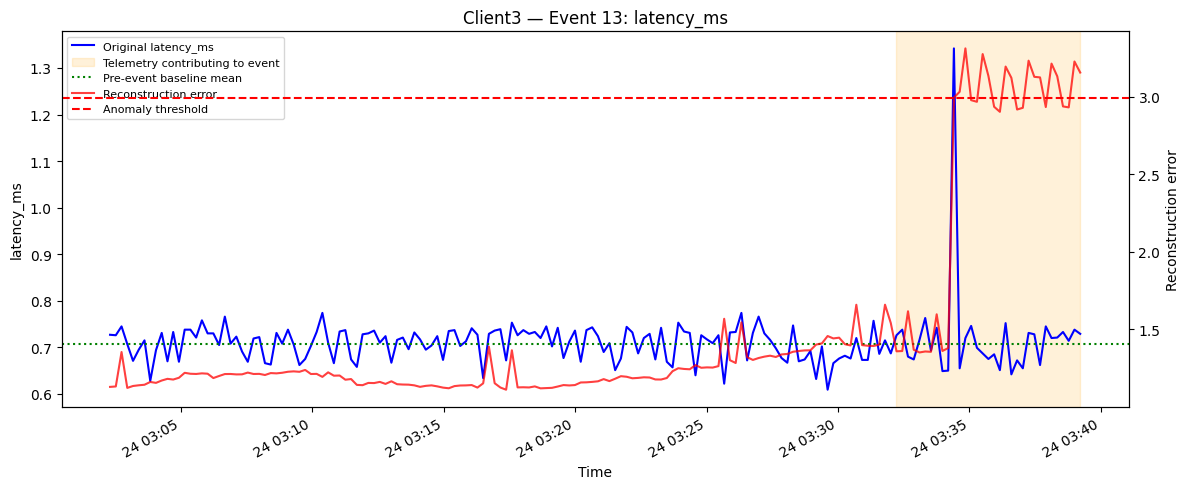

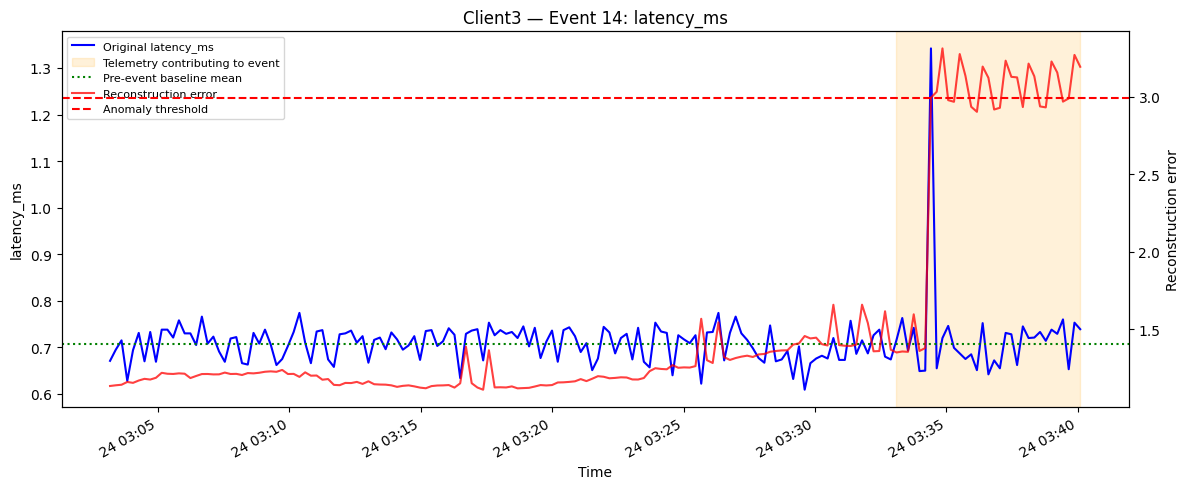

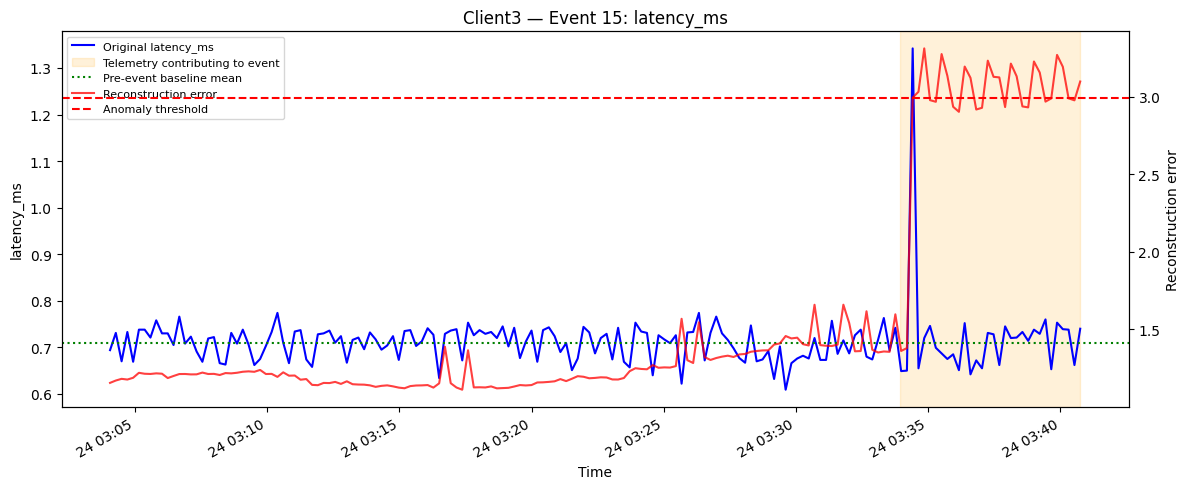

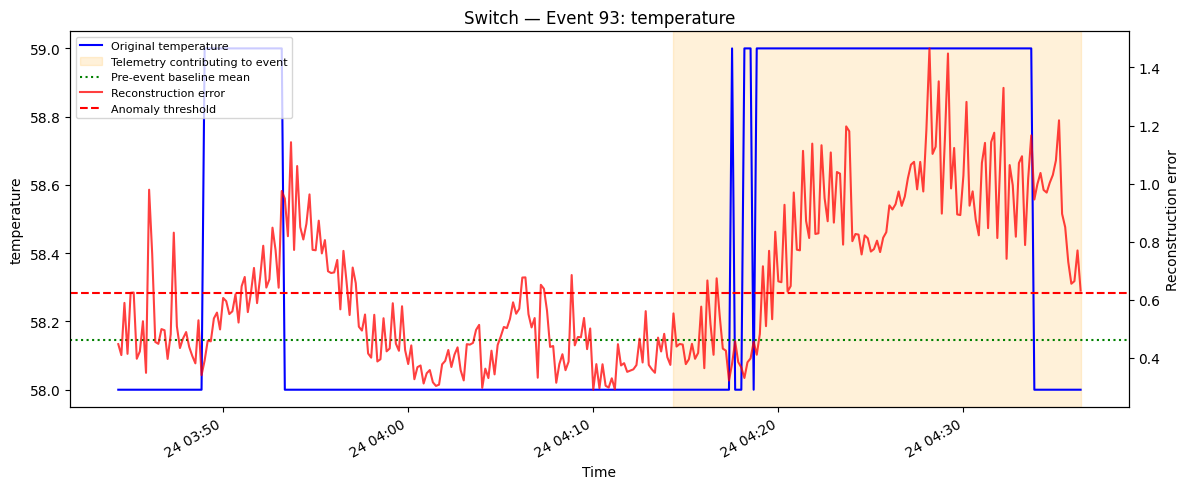

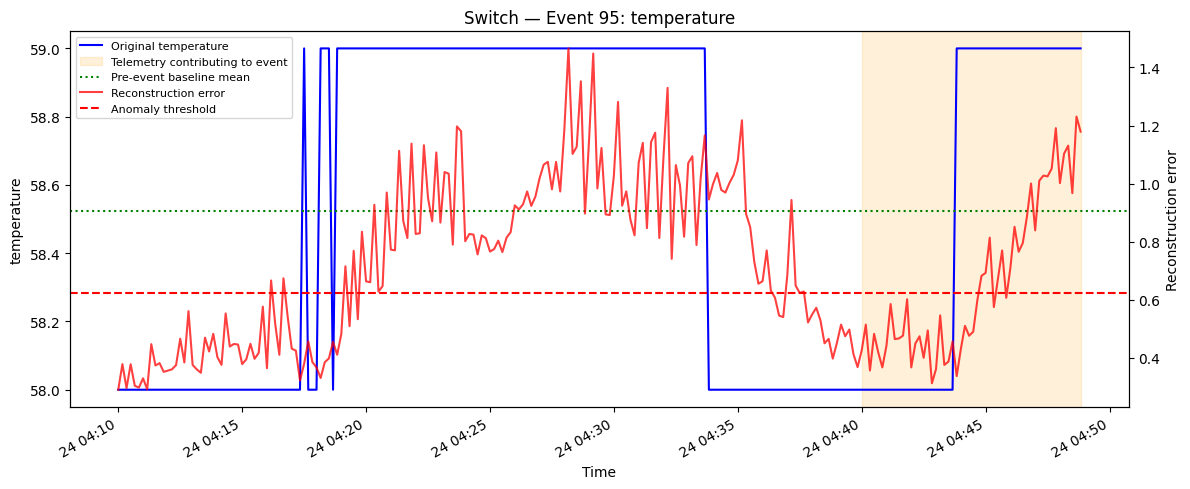


SECTION 8 COMPLETE
 Device  Event_ID         Metric  Baseline_Mean  Event_Mean  Event_Max   Mean_Change  Peak_Severity_Ratio
Client1         1        cpu_pct       0.103650    0.152459      3.100  4.880938e-02             1.327593
Client1         2        cpu_pct       0.122628    0.150820      3.100  2.819193e-02             1.251313
Client1         3        cpu_pct       0.102190    0.149180      3.000  4.699055e-02             1.220436
Client1         4        cpu_pct       0.101460    0.149180      2.900  4.772047e-02             1.165550
Client1         5        cpu_pct       0.105839    0.152459      3.000  4.661960e-02             1.265288
Client1         6        cpu_pct       0.100730    0.152459      3.200  5.172909e-02             1.347130
Client1         7        cpu_pct       0.102190    0.152459      3.200  5.026924e-02             1.341476
Client1         8        cpu_pct       0.103650    0.149180      3.100  4.553069e-02             1.255837
Client1         9        c

In [8]:
# ============================================================
# SECTION 8 — ANOMALY VALIDATION AGAINST ORIGINAL TELEMETRY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 8.1 Configuration
# ------------------------------------------------------------

EVENTS_TO_INSPECT = {
    "Client1": list(range(1, 12)),
    "Client2": [8, 13, 14, 15, 16, 17, 18],
    "Client3": [9, 10, 11, 12, 13, 14, 15],
    "Switch": [93, 95]
}

BASELINE_MINUTES = 30

VALIDATION_DIR = OUTPUT_DIR / "Anomaly_Validation"
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

validation_results = []

# ------------------------------------------------------------
# 8.2 Validate each event
# ------------------------------------------------------------

for device, event_ids in EVENTS_TO_INSPECT.items():

    telemetry = datasets[device].copy()
    events = event_results[device]
    errors = anomaly_results[device].copy()

    telemetry["timestamp"] = pd.to_datetime(
        telemetry["timestamp"], utc=True
    )

    errors["timestamp"] = pd.to_datetime(
        errors["timestamp"], utc=True
    )

    for event_id in event_ids:

        selected = events[
            events["Event_ID"] == event_id
        ]

        if selected.empty:
            print(f"{device}: Event {event_id} not found.")
            continue

        event = selected.iloc[0]

        metric = event["Dominant_Metric"]

        start = pd.Timestamp(event["Start_Time"])
        end = pd.Timestamp(event["End_Time"])

        # Account for the 30-observation LSTM window.
        # This is an approximate window duration.
        sample_seconds = (
            10 if device == "Switch" else 14.07
        )

        window_duration = pd.Timedelta(
            seconds=(SEQUENCE_LENGTH - 1) * sample_seconds
        )

        event_window_start = start - window_duration
        baseline_start = (
            event_window_start
            - pd.Timedelta(minutes=BASELINE_MINUTES)
        )

        # ----------------------------------------------------
        # Baseline and event telemetry
        # ----------------------------------------------------

        baseline = telemetry[
            (telemetry["timestamp"] >= baseline_start) &
            (telemetry["timestamp"] < event_window_start)
        ]

        event_data = telemetry[
            (telemetry["timestamp"] >= event_window_start) &
            (telemetry["timestamp"] <= end)
        ]

        if baseline.empty or event_data.empty:
            print(f"{device} Event {event_id}: insufficient data")
            continue

        baseline_mean = baseline[metric].mean()
        baseline_std = baseline[metric].std()

        event_mean = event_data[metric].mean()
        event_max = event_data[metric].max()
        event_min = event_data[metric].min()

        change = event_mean - baseline_mean

        # ----------------------------------------------------
        # Save quantitative comparison
        # ----------------------------------------------------

        validation_results.append({
            "Device": device,
            "Event_ID": event_id,
            "Metric": metric,
            "Start_Time": start,
            "End_Time": end,
            "Baseline_Mean": baseline_mean,
            "Baseline_Std": baseline_std,
            "Event_Mean": event_mean,
            "Event_Min": event_min,
            "Event_Max": event_max,
            "Mean_Change": change,
            "Peak_Severity_Ratio": event["Peak_Severity_Ratio"]
        })

        # ----------------------------------------------------
        # 8.3 Plot original metric and reconstruction error
        # ----------------------------------------------------

        fig, ax1 = plt.subplots(figsize=(12, 5))

        period = telemetry[
            (telemetry["timestamp"] >= baseline_start) &
            (telemetry["timestamp"] <= end)
        ]

        ax1.plot(
            period["timestamp"],
            period[metric],
            label=f"Original {metric}",
            color="blue"
        )

        ax1.axvspan(
            event_window_start,
            end,
            color="orange",
            alpha=0.15,
            label="Telemetry contributing to event"
        )

        ax1.axhline(
            baseline_mean,
            color="green",
            linestyle=":",
            label="Pre-event baseline mean"
        )

        ax1.set_xlabel("Time")
        ax1.set_ylabel(metric)

        # Reconstruction error on secondary axis
        ax2 = ax1.twinx()

        error_period = errors[
            (errors["timestamp"] >= baseline_start) &
            (errors["timestamp"] <= end)
        ]

        ax2.plot(
            error_period["timestamp"],
            error_period["reconstruction_error"],
            color="red",
            alpha=0.75,
            label="Reconstruction error"
        )

        ax2.axhline(
            event["Threshold"],
            color="red",
            linestyle="--",
            label="Anomaly threshold"
        )

        ax2.set_ylabel("Reconstruction error")

        plt.title(f"{device} — Event {event_id}: {metric}")

        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()

        ax1.legend(
            lines1 + lines2,
            labels1 + labels2,
            loc="upper left",
            fontsize=8
        )

        fig.autofmt_xdate()
        plt.tight_layout()

        plot_path = (
            VALIDATION_DIR /
            f"{device}_Event_{event_id}.png"
        )

        plt.savefig(plot_path, dpi=150)
        plt.show()
        plt.close()

# ============================================================
# 8.4 SAVE VALIDATION SUMMARY
# ============================================================

validation_df = pd.DataFrame(validation_results)

validation_file = (
    VALIDATION_DIR / "Anomaly_Validation_Summary.csv"
)

validation_df.to_csv(validation_file, index=False)

print("\n" + "=" * 60)
print("SECTION 8 COMPLETE")
print("=" * 60)

if not validation_df.empty:
    print(
        validation_df[
            [
                "Device",
                "Event_ID",
                "Metric",
                "Baseline_Mean",
                "Event_Mean",
                "Event_Max",
                "Mean_Change",
                "Peak_Severity_Ratio"
            ]
        ].to_string(index=False)
    )

print("\nResults saved to:", VALIDATION_DIR)

Section 9 - synthetic fault injection and general evaluation


Client1
  CPU_Overload — 30_seconds complete
  CPU_Overload — 2_minutes complete
  CPU_Overload — 5_minutes complete
  High_Latency — 30_seconds complete
  High_Latency — 2_minutes complete
  High_Latency — 5_minutes complete
  Packet_Loss — 30_seconds complete
  Packet_Loss — 2_minutes complete
  Packet_Loss — 5_minutes complete
  High_Temperature — 30_seconds complete
  High_Temperature — 2_minutes complete
  High_Temperature — 5_minutes complete

Client2
  CPU_Overload — 30_seconds complete
  CPU_Overload — 2_minutes complete
  CPU_Overload — 5_minutes complete
  High_Latency — 30_seconds complete
  High_Latency — 2_minutes complete
  High_Latency — 5_minutes complete
  Packet_Loss — 30_seconds complete
  Packet_Loss — 2_minutes complete
  Packet_Loss — 5_minutes complete
  High_Temperature — 30_seconds complete
  High_Temperature — 2_minutes complete
  High_Temperature — 5_minutes complete

Client3
  CPU_Overload — 30_seconds complete
  CPU_Overload — 2_minutes complete
  CPU_Over

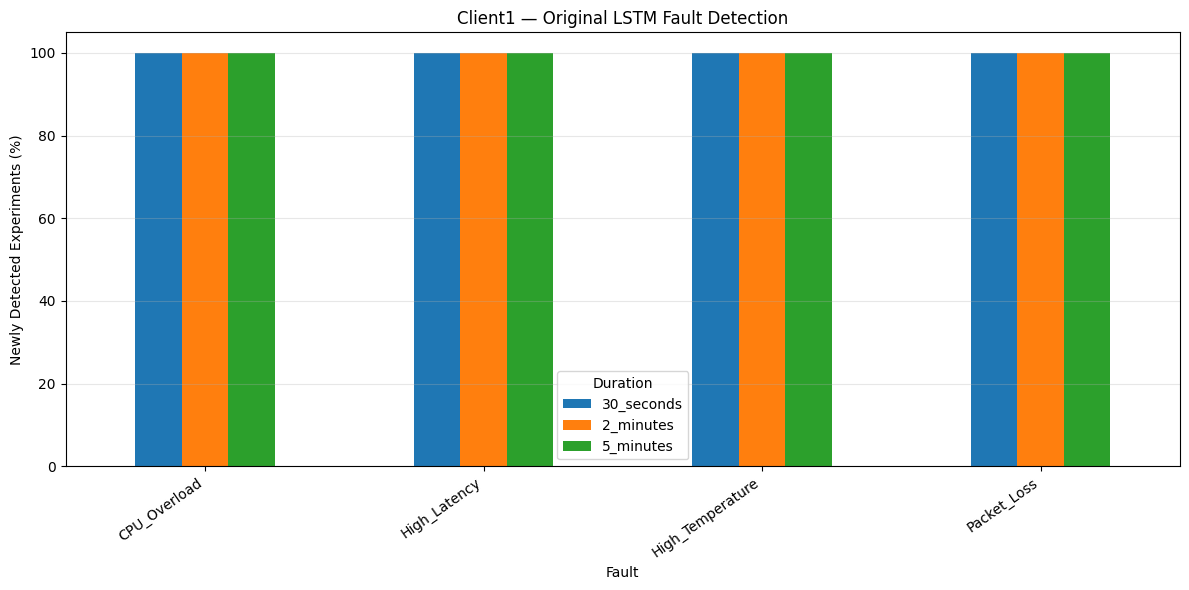

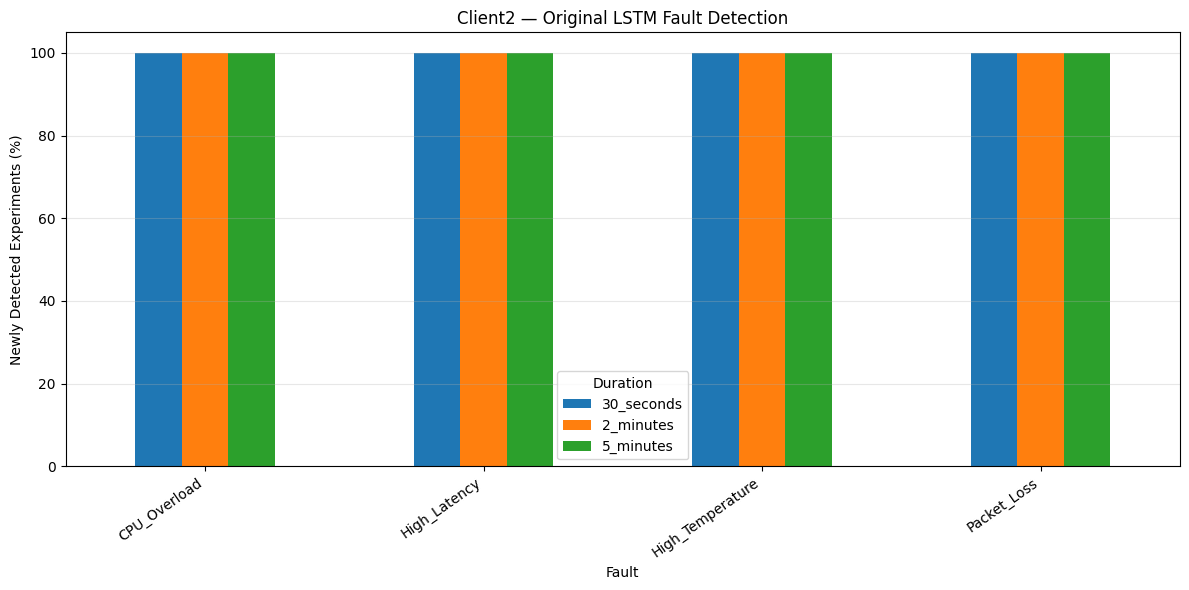

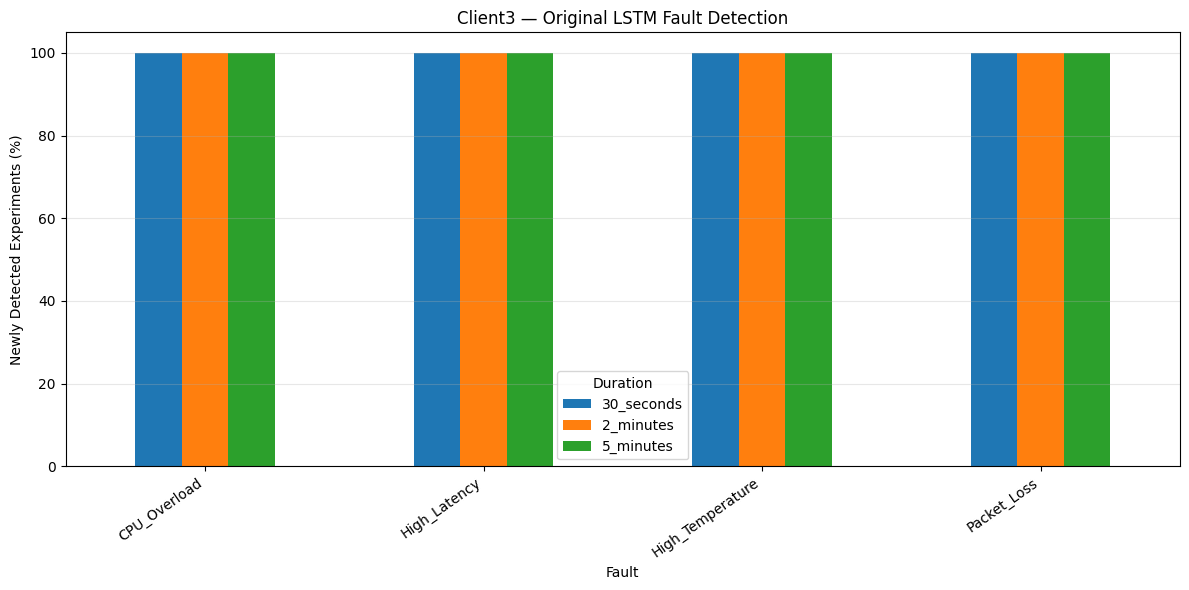

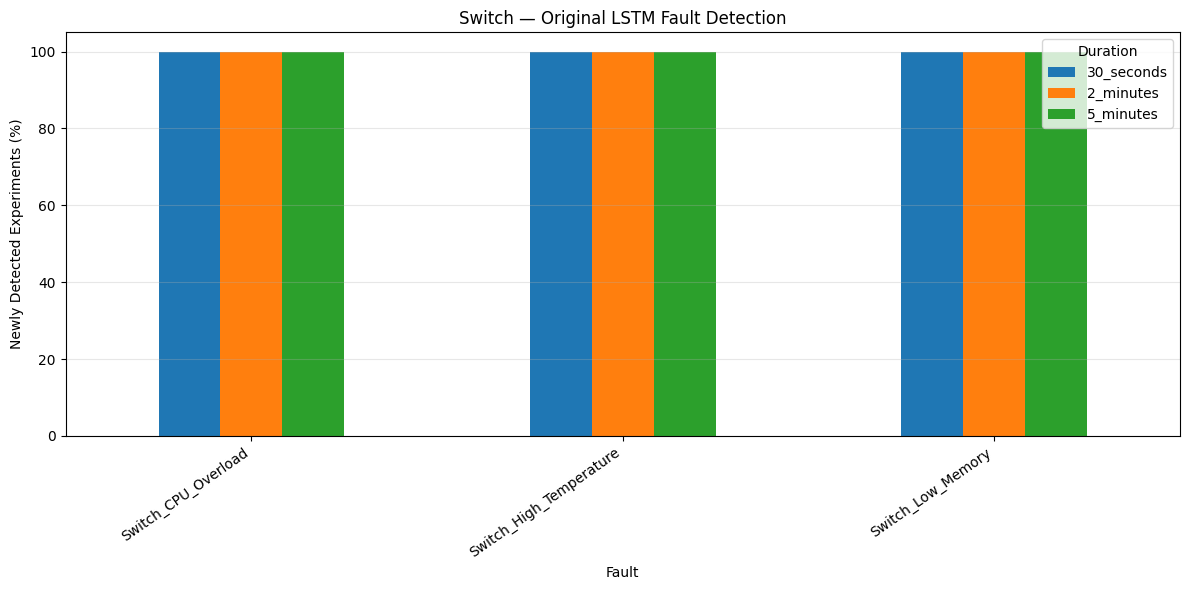


SECTION 9A COMPLETE
Total experiments: 225
 Device                   Fault   Duration  Experiments  Detected  Newly_Detected  Mean_Detection_Delay   Mean_Error  New_Detection_Rate_Pct
Client1            CPU_Overload  2_minutes            5         5               5              0.000000 9.781770e+03                   100.0
Client1            CPU_Overload 30_seconds            5         5               5              0.000000 3.576659e+03                   100.0
Client1            CPU_Overload  5_minutes            5         5               5              0.000000 1.687278e+04                   100.0
Client1            High_Latency  2_minutes            5         5               5              0.000000 1.036559e+05                   100.0
Client1            High_Latency 30_seconds            5         5               5              0.000000 3.787937e+04                   100.0
Client1            High_Latency  5_minutes            5         5               5              0.000000 1.7904

In [9]:

# ============================================================
# SECTION 9A — SYNTHETIC FAULT INJECTION
# ORIGINAL-METRICS LSTM AUTOENCODER
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("LSTM_Results") / "Original_Fault_Injection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FAULT_DURATIONS = {
    "30_seconds": 30,
    "2_minutes": 120,
    "5_minutes": 300,
}

INJECTION_POSITIONS = [0.12, 0.30, 0.48, 0.66, 0.83]
DEVICE_ORDER = ["Client1", "Client2", "Client3", "Switch"]

CLIENT_FAULTS = {
    "CPU_Overload": ("cpu_pct", 85.0, "set"),
    "High_Latency": ("latency_ms", 50.0, "set"),
    "Packet_Loss": ("packet_loss_pct", 20.0, "set"),
    "High_Temperature": ("temperature_c", 80.0, "set"),
}

SWITCH_FAULTS = {
    "Switch_CPU_Overload": ("cpu_pct", 85.0, "set"),
    "Switch_High_Temperature": ("temperature", 80.0, "set"),
    "Switch_Low_Memory": (
        "free_memory", 0.10, "fraction_of_median"
    ),
}

METRIC_ALIASES = {
    "temperature_c": ["temperature_c", "temp_c"],
    "temperature": ["temperature", "temp"],
    "free_memory": ["free_memory", "free_ram"],
    "cpu_pct": ["cpu_pct", "cpu_load"],
}

def reconstruction_error(model, X):
    prediction = model.predict(
        np.asarray(X, dtype=np.float32),
        batch_size=256,
        verbose=0
    )
    return np.mean(
        (np.asarray(X, dtype=np.float64) - prediction) ** 2,
        axis=(1, 2)
    )

def evaluate_original_faults():
    records = []
    sequence_records = []

    for device in DEVICE_ORDER:
        print(f"\n{'=' * 60}\n{device}\n{'=' * 60}")

        data = sequence_data[device]
        metrics = list(data["metrics"])
        X_test = np.asarray(data["test"])
        scaler = scalers[device]

        model = models.get(device)
        if model is None:
            from tensorflow import keras
            model = keras.models.load_model(
                Path("LSTM_Results") / "Models" /
                f"{device}_LSTM_Autoencoder.keras"
            )

        threshold = float(anomaly_thresholds[device])
        if threshold <= 0:
            raise ValueError(f"{device}: Invalid threshold")

        observation_times = pd.DatetimeIndex(
            pd.to_datetime(
                split_data[device]["test_timestamps"], utc=True
            )
        )
        sequence_times = pd.DatetimeIndex(
            pd.to_datetime(data["test_timestamps"], utc=True)
        )

        end_indices = observation_times.get_indexer(sequence_times)
        seq_len = X_test.shape[1]
        start_indices = end_indices - seq_len + 1

        if np.any(start_indices < 0):
            raise ValueError(f"{device}: Sequence alignment failed")

        scaled_train = np.asarray(
            split_data[device]["train"]
        )
        raw_train = scaler.inverse_transform(scaled_train)

        baseline_errors = reconstruction_error(model, X_test)

        faults = (
            SWITCH_FAULTS if device == "Switch"
            else CLIENT_FAULTS
        )

        for fault_name, (metric, value, method) in faults.items():
            aliases = METRIC_ALIASES.get(metric, [metric])
            found = next(
                (name for name in aliases if name in metrics),
                None
            )
            if found is None:
                raise ValueError(
                    f"{device}: Missing metric for {fault_name}"
                )

            metric_idx = metrics.index(found)

            if method == "set":
                raw_value = value
            else:
                raw_value = (
                    np.median(raw_train[:, metric_idx]) * value
                )

            scaled_value = (
                raw_value - scaler.mean_[metric_idx]
            ) / scaler.scale_[metric_idx]

            for duration_name, duration_s in FAULT_DURATIONS.items():
                for injection_number, position in enumerate(
                    INJECTION_POSITIONS, start=1
                ):
                    idx = int(len(observation_times) * position)
                    inject_start = observation_times[idx]
                    inject_end = inject_start + pd.Timedelta(
                        seconds=duration_s
                    )

                    injected_rows = np.flatnonzero(
                        (observation_times >= inject_start) &
                        (observation_times < inject_end)
                    )

                    if len(injected_rows) == 0:
                        raise ValueError(
                            f"{device}: No samples in injection"
                        )

                    first_row = injected_rows[0]
                    last_row = injected_rows[-1]

                    affected = np.flatnonzero(
                        (end_indices >= first_row) &
                        (start_indices <= last_row)
                    )

                    modified = X_test[affected].copy()

                    row_indices = (
                        end_indices[affected, None]
                        - np.arange(seq_len - 1, -1, -1)[None, :]
                    )

                    mask = (
                        (row_indices >= first_row) &
                        (row_indices <= last_row)
                    )

                    modified[:, :, metric_idx] = np.where(
                        mask,
                        scaled_value,
                        modified[:, :, metric_idx]
                    )

                    original_errors = baseline_errors[affected]
                    injected_errors = reconstruction_error(
                        model, modified
                    )

                    original_flags = original_errors > threshold
                    injected_flags = injected_errors > threshold
                    new_flags = injected_flags & ~original_flags

                    first_detection = (
                        sequence_times[affected][
                            np.flatnonzero(new_flags)[0]
                        ]
                        if new_flags.any() else pd.NaT
                    )

                    delay = (
                        (first_detection - inject_start).total_seconds()
                        if new_flags.any() else np.nan
                    )

                    experiment_id = (
                        f"{device}_{fault_name}_"
                        f"{duration_name}_{injection_number}"
                    )

                    records.append({
                        "Experiment_ID": experiment_id,
                        "Device": device,
                        "Model": "Original",
                        "Fault": fault_name,
                        "Metric": found,
                        "Duration": duration_name,
                        "Duration_Seconds": duration_s,
                        "Injection_Start": inject_start,
                        "Injection_End": inject_end,
                        "Injected_Value": raw_value,
                        "Injected_Observations": len(injected_rows),
                        "Affected_Sequences": len(affected),
                        "Original_Anomalies": int(original_flags.sum()),
                        "Detected_Sequences": int(injected_flags.sum()),
                        "Newly_Detected_Sequences": int(new_flags.sum()),
                        "Detected_Any": bool(injected_flags.any()),
                        "Newly_Detected_Any": bool(new_flags.any()),
                        "Detection_Rate_Pct": injected_flags.mean() * 100,
                        "New_Detection_Rate_Pct": new_flags.mean() * 100,
                        "Detection_Delay_Seconds": delay,
                        "Original_Mean_Error": original_errors.mean(),
                        "Injected_Mean_Error": injected_errors.mean(),
                        "Peak_Threshold_Ratio": injected_errors.max() / threshold,
                        "Threshold": threshold,
                    })

                    for j, sequence_idx in enumerate(affected):
                        sequence_records.append({
                            "Experiment_ID": experiment_id,
                            "Device": device,
                            "timestamp": sequence_times[sequence_idx],
                            "original_error": original_errors[j],
                            "injected_error": injected_errors[j],
                            "original_anomaly": bool(original_flags[j]),
                            "injected_anomaly": bool(injected_flags[j]),
                            "newly_detected": bool(new_flags[j]),
                        })

                print(f"  {fault_name} — {duration_name} complete")

    results = pd.DataFrame(records)
    sequence_results = pd.DataFrame(sequence_records)

    assert len(results) == 225, (
        f"Expected 225 experiments, got {len(results)}"
    )

    summary = (
        results.groupby(["Device", "Fault", "Duration"], as_index=False)
        .agg(
            Experiments=("Experiment_ID", "count"),
            Detected=("Detected_Any", "sum"),
            Newly_Detected=("Newly_Detected_Any", "sum"),
            Mean_Detection_Delay=("Detection_Delay_Seconds", "mean"),
            Mean_Error=("Injected_Mean_Error", "mean"),
        )
    )
    summary["New_Detection_Rate_Pct"] = (
        summary["Newly_Detected"] / summary["Experiments"] * 100
    )

    results.to_csv(
        OUTPUT_DIR / "Original_All_Fault_Results.csv", index=False
    )
    sequence_results.to_csv(
        OUTPUT_DIR / "Original_Sequence_Results.csv", index=False
    )
    summary.to_csv(
        OUTPUT_DIR / "Original_Fault_Summary.csv", index=False
    )

    for device in DEVICE_ORDER:
        subset = summary[summary["Device"] == device]
        pivot = subset.pivot(
            index="Fault",
            columns="Duration",
            values="New_Detection_Rate_Pct"
        ).reindex(columns=list(FAULT_DURATIONS))

        ax = pivot.plot(kind="bar", figsize=(12, 6))
        ax.set_title(f"{device} — Original LSTM Fault Detection")
        ax.set_ylabel("Newly Detected Experiments (%)")
        ax.set_ylim(0, 105)
        ax.grid(axis="y", alpha=0.3)
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"Original_{device}_Detection.png",
            dpi=180
        )
        plt.show()
        plt.close()

    print("\nSECTION 9A COMPLETE")
    print(f"Total experiments: {len(results)}")
    print(summary.to_string(index=False))

    return results, sequence_results, summary

original_results, original_sequences, original_summary = (
    evaluate_original_faults()
)


Section 10 - Final Model Evaluation


10.3 — Loading original LSTM results
Client1: 24827 test sequences
Client2: 24824 test sequences
Client3: 24791 test sequences
Switch: 22045 test sequences

SECTION 10 — ORIGINAL LSTM EVALUATION
Devices loaded: 4
Fault experiments: 225
Sequence-level records: 9360
Fault file: C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\LSTM_Results\Original_Fault_Injection\Original_All_Fault_Results.csv

10.4 — Generating original telemetry box plots


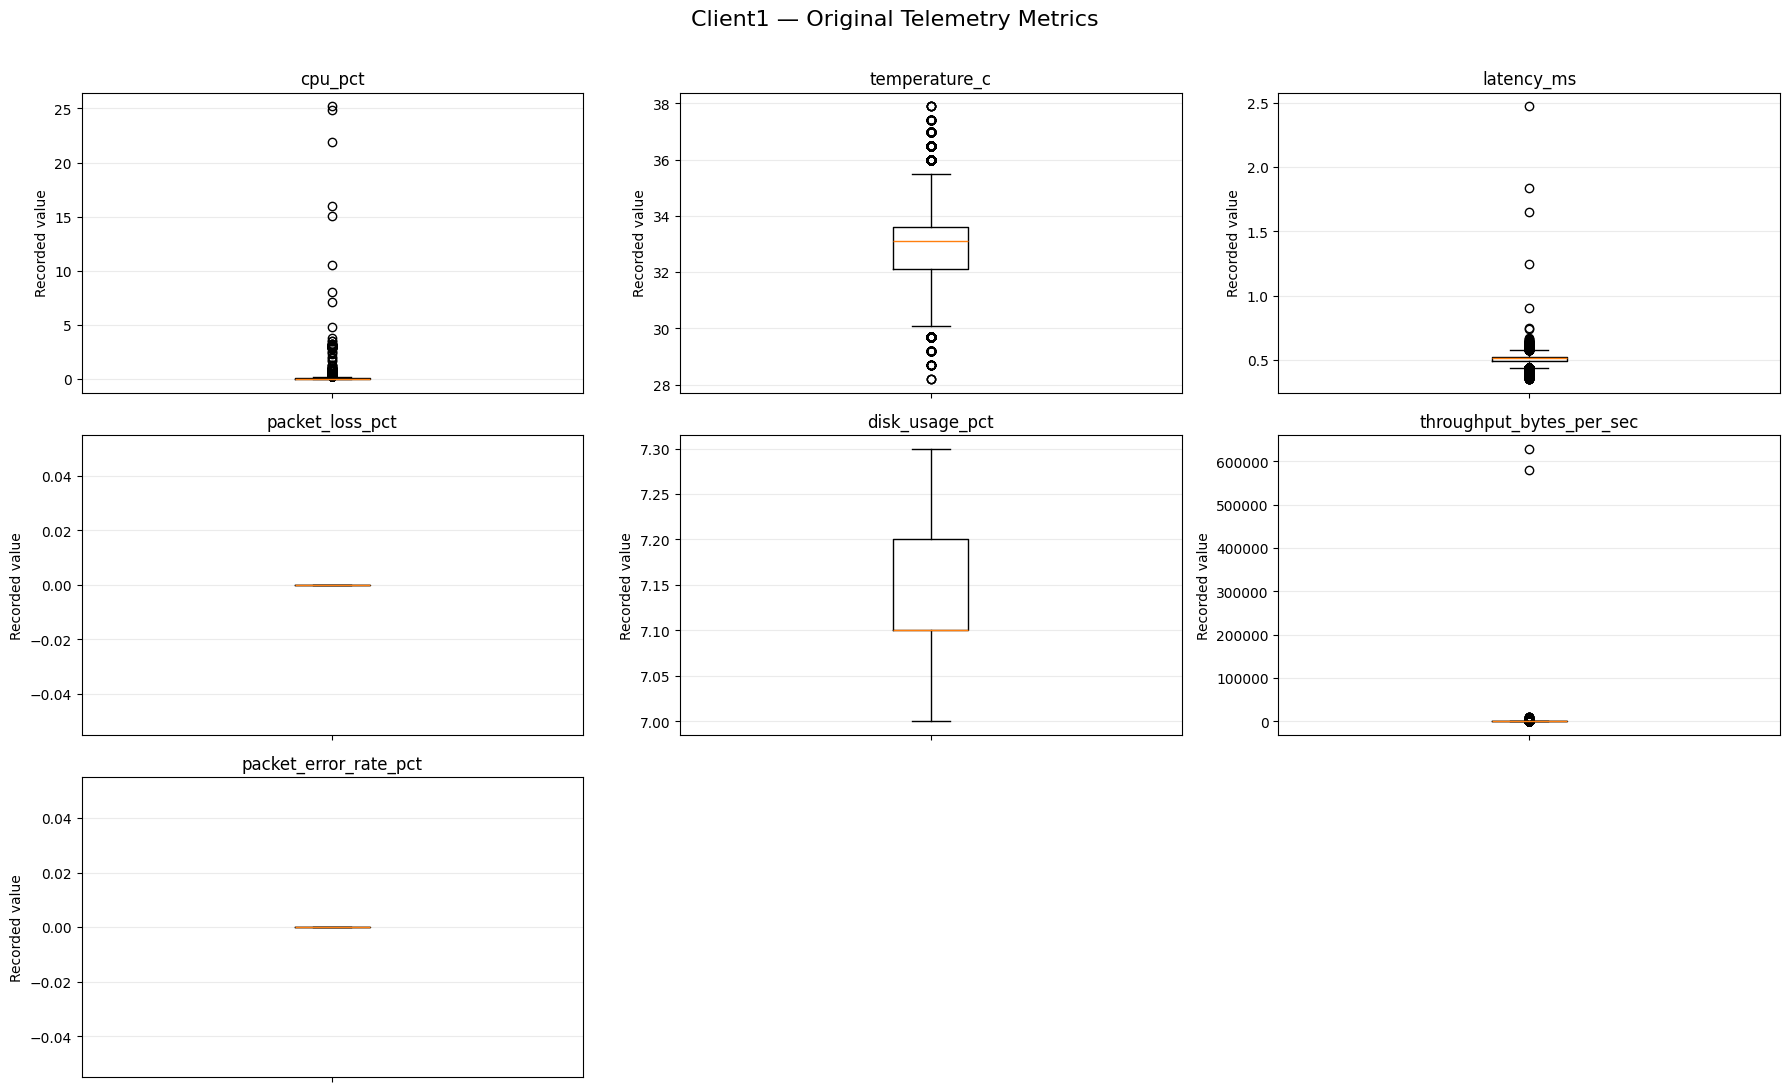

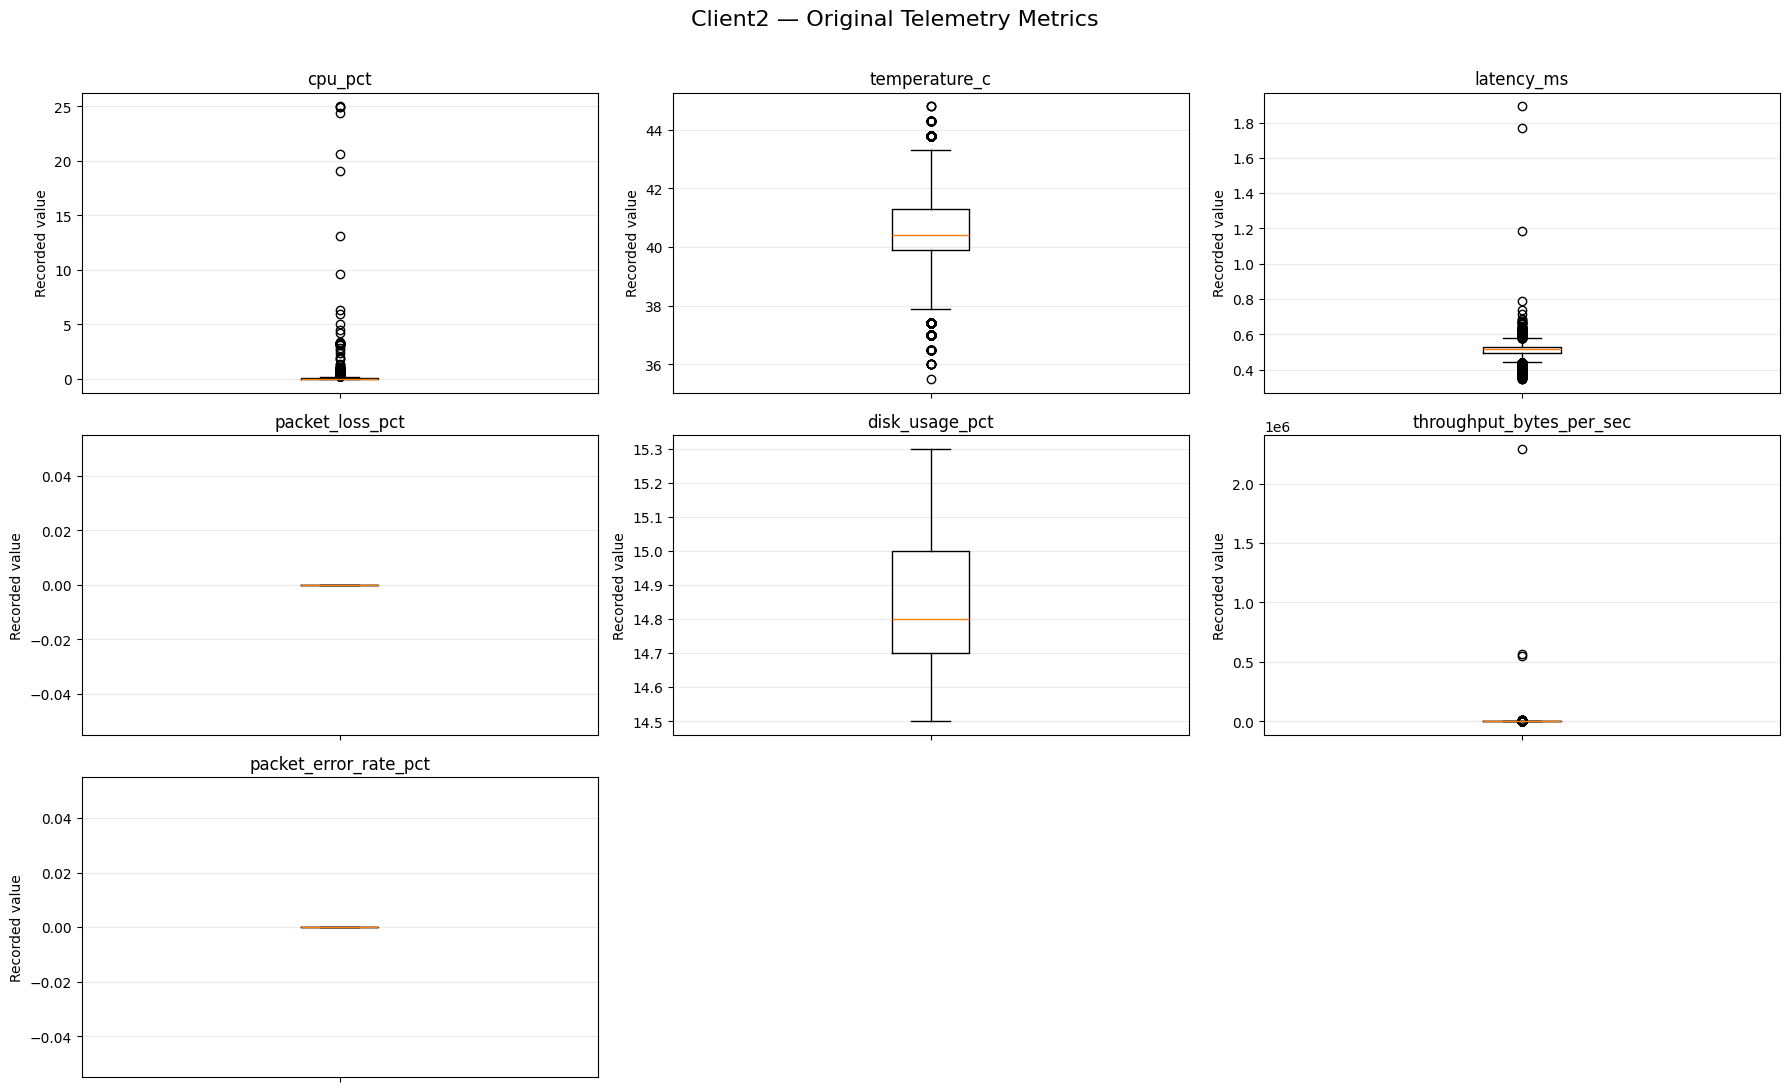

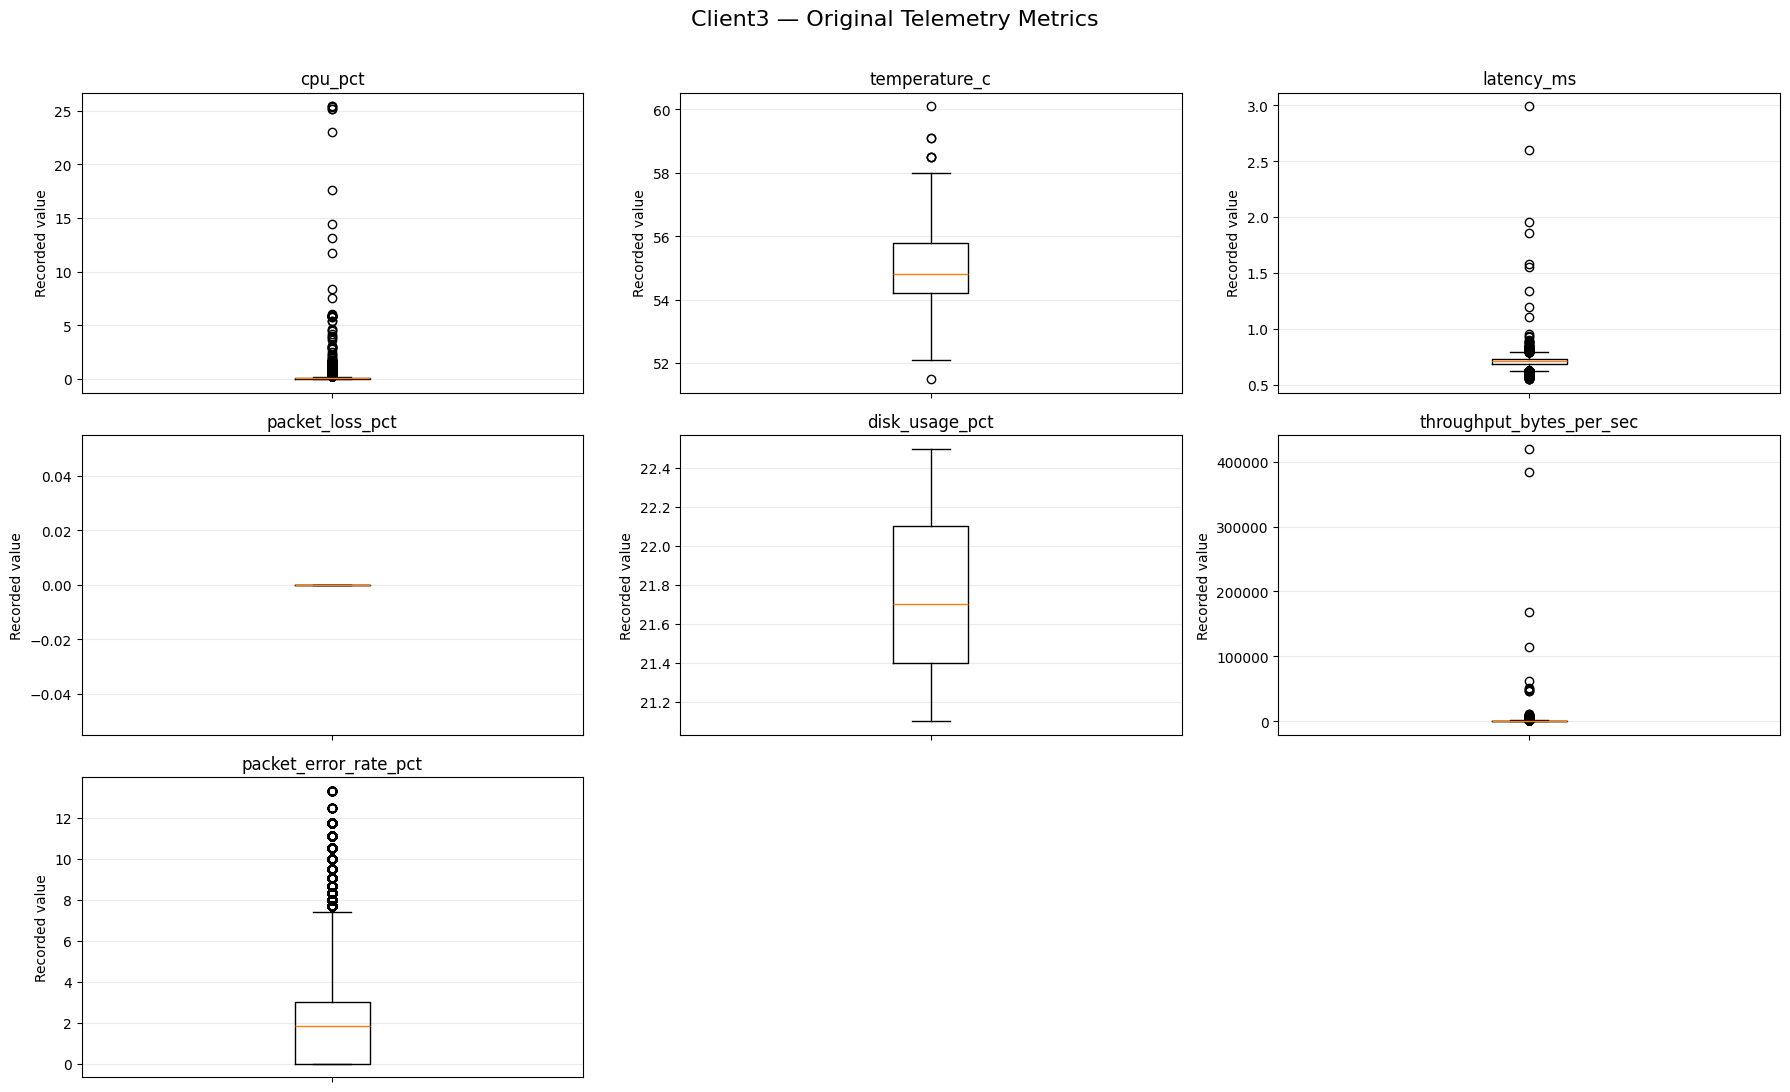

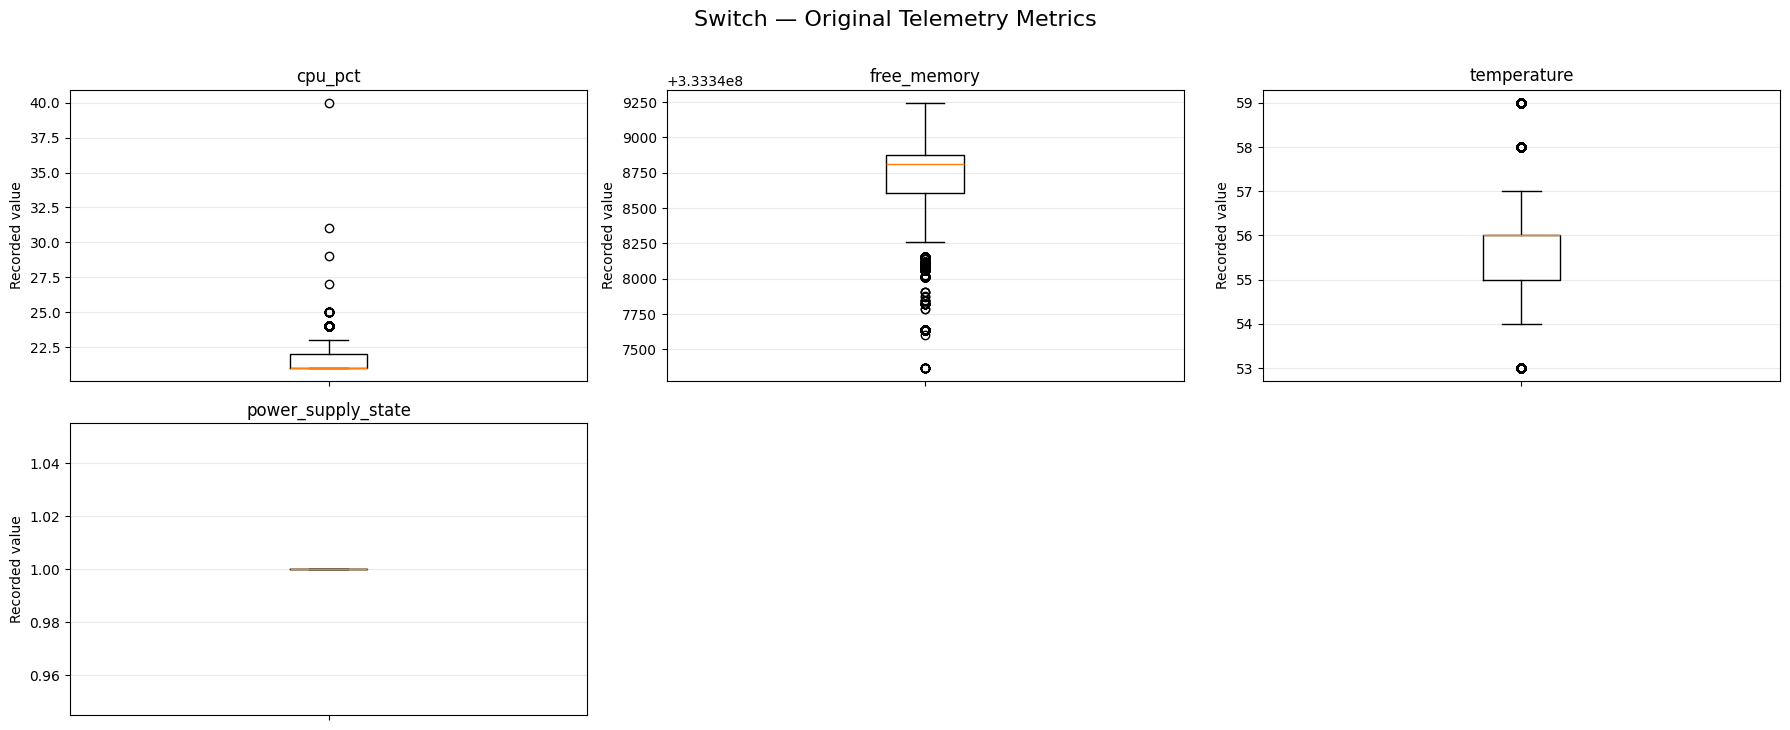


10.5 — Per-metric reconstruction-error box plots


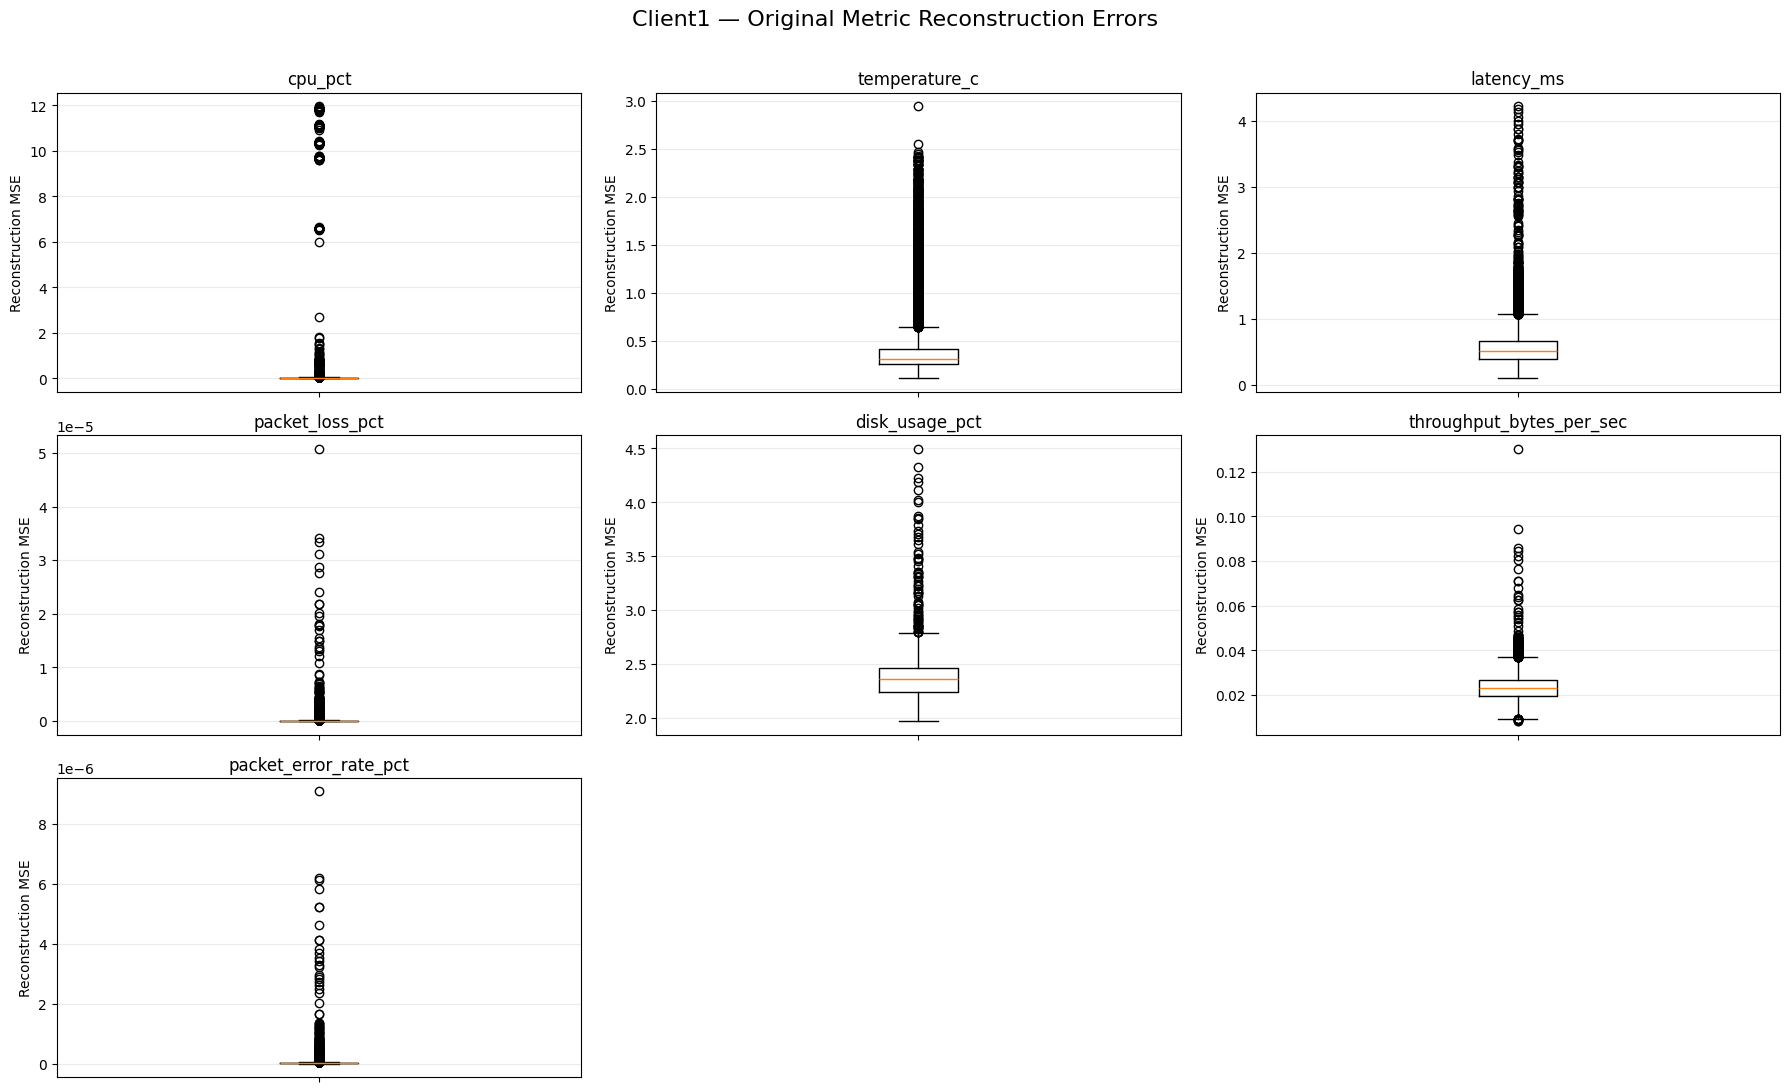

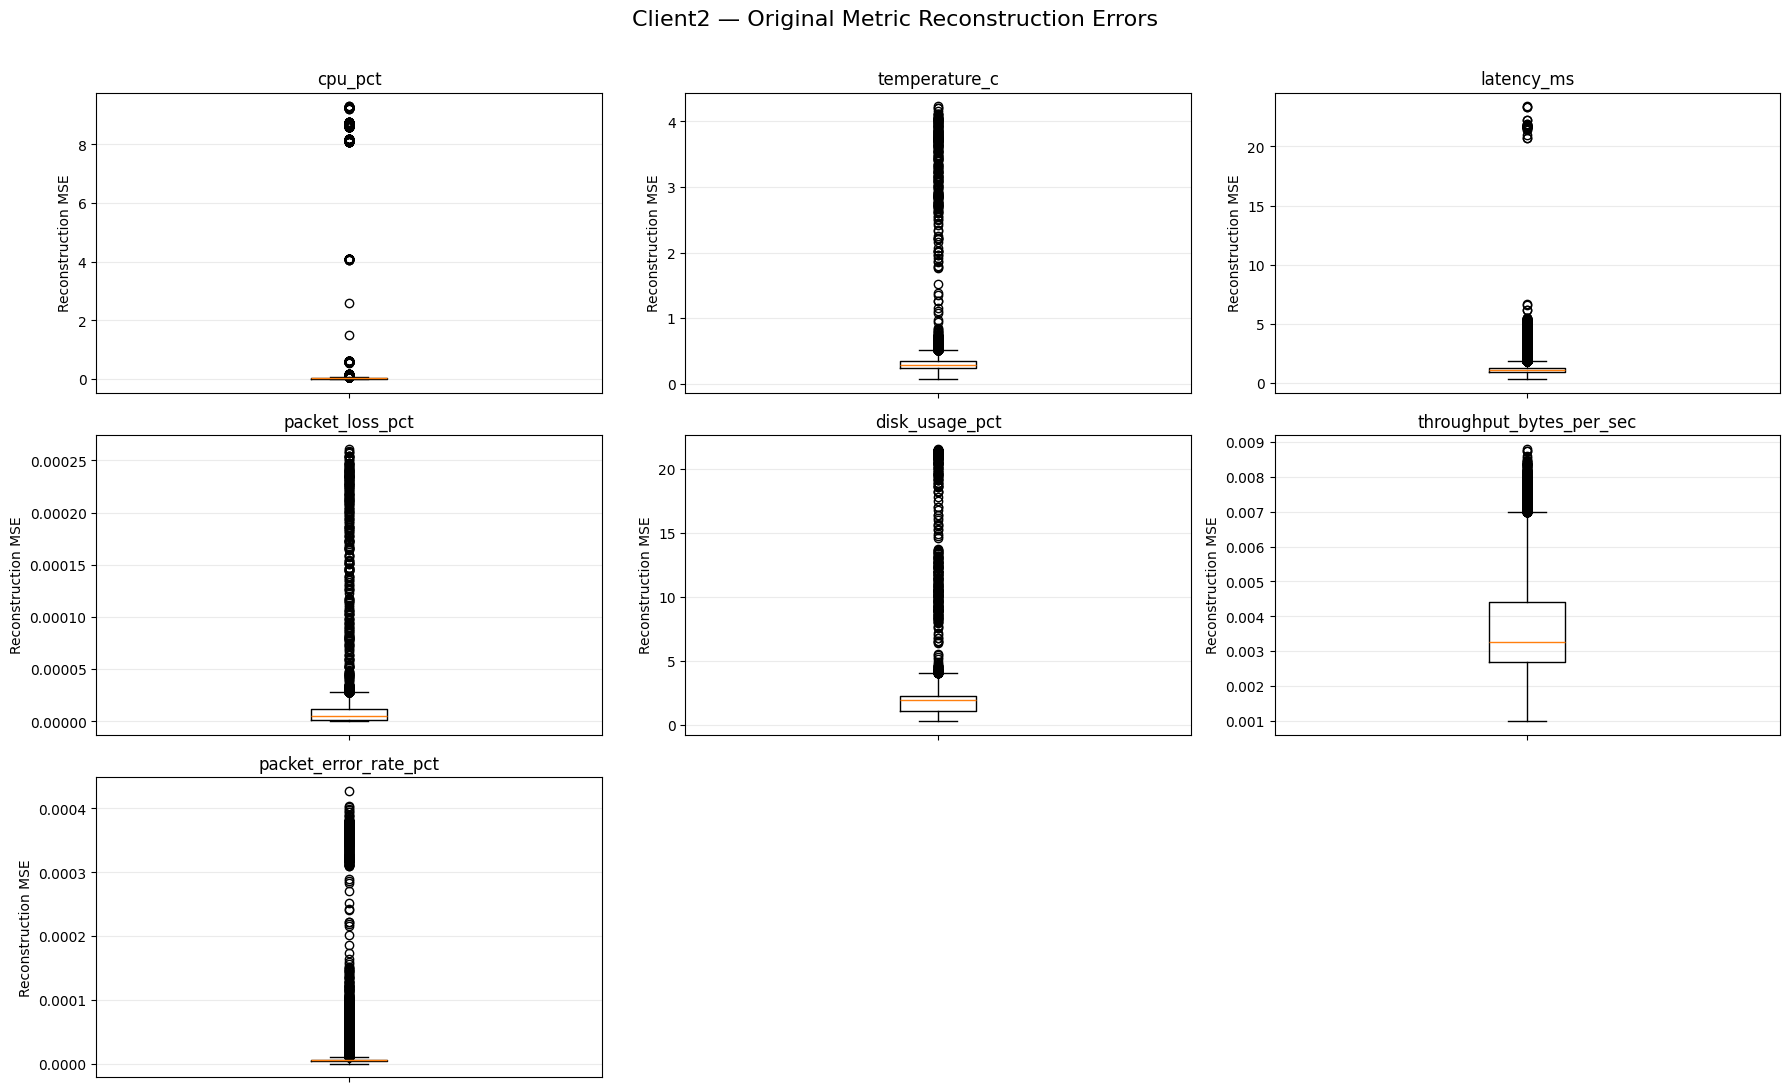

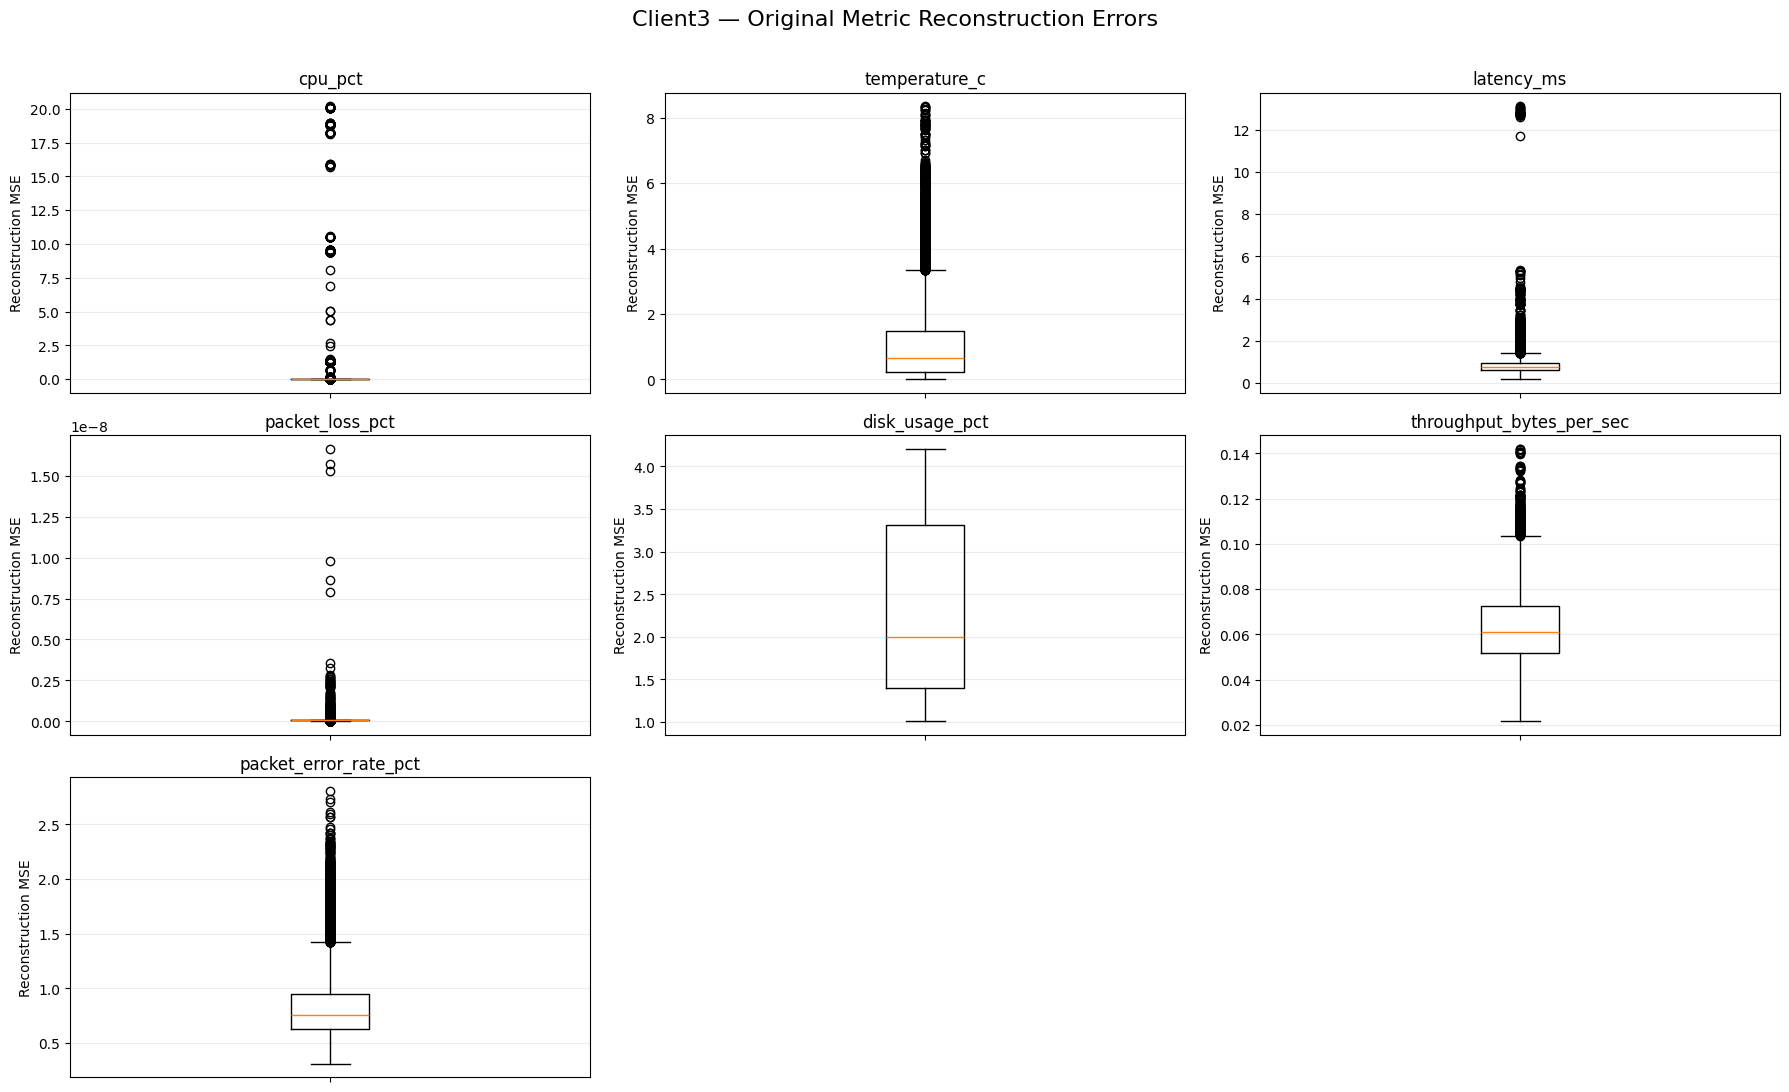

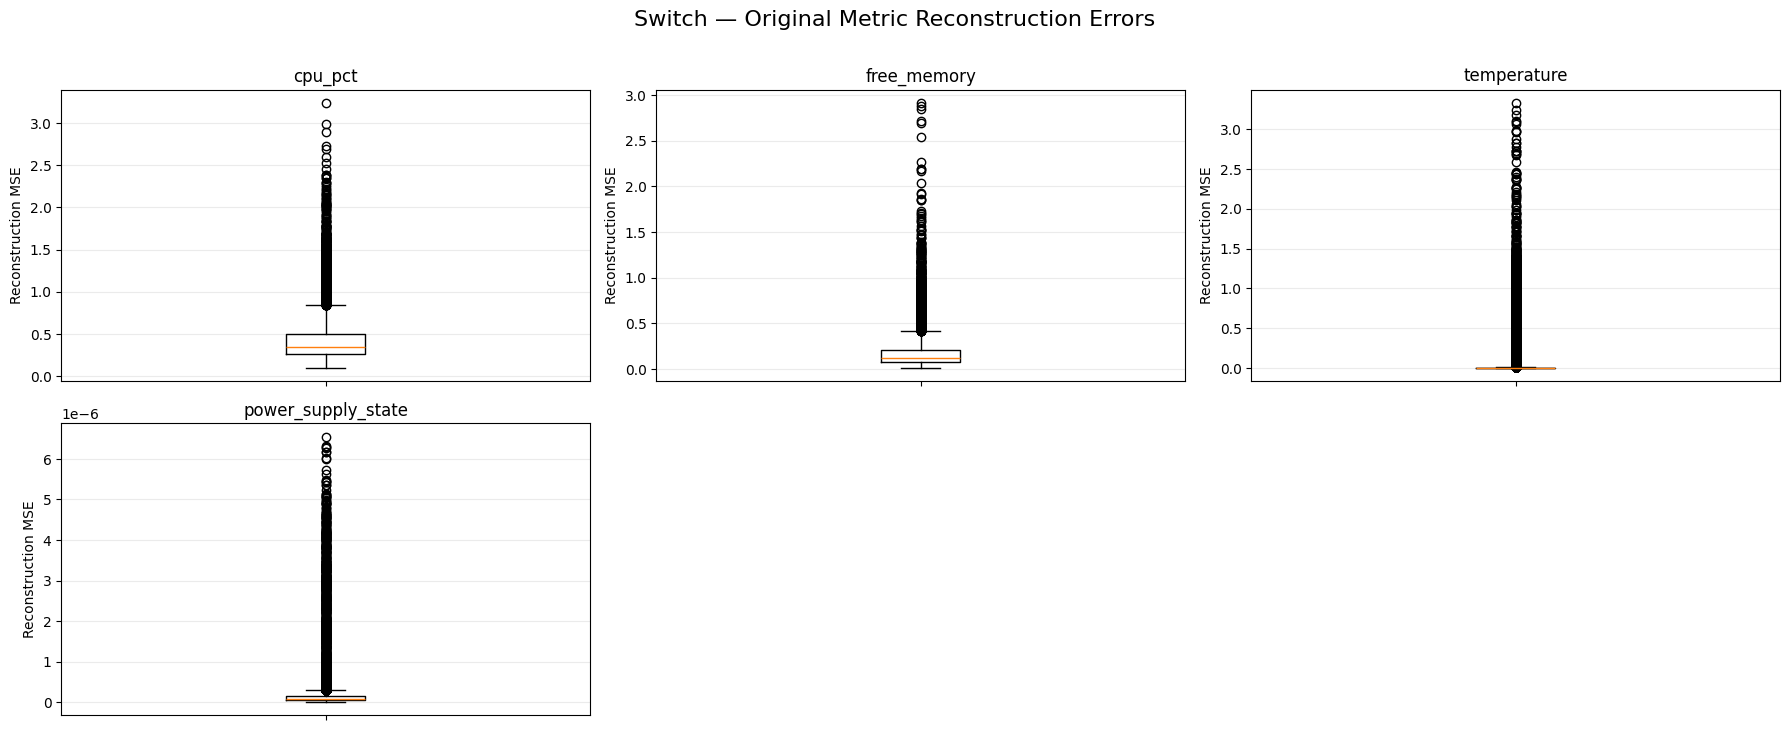


10.6 — Overall reconstruction error comparison


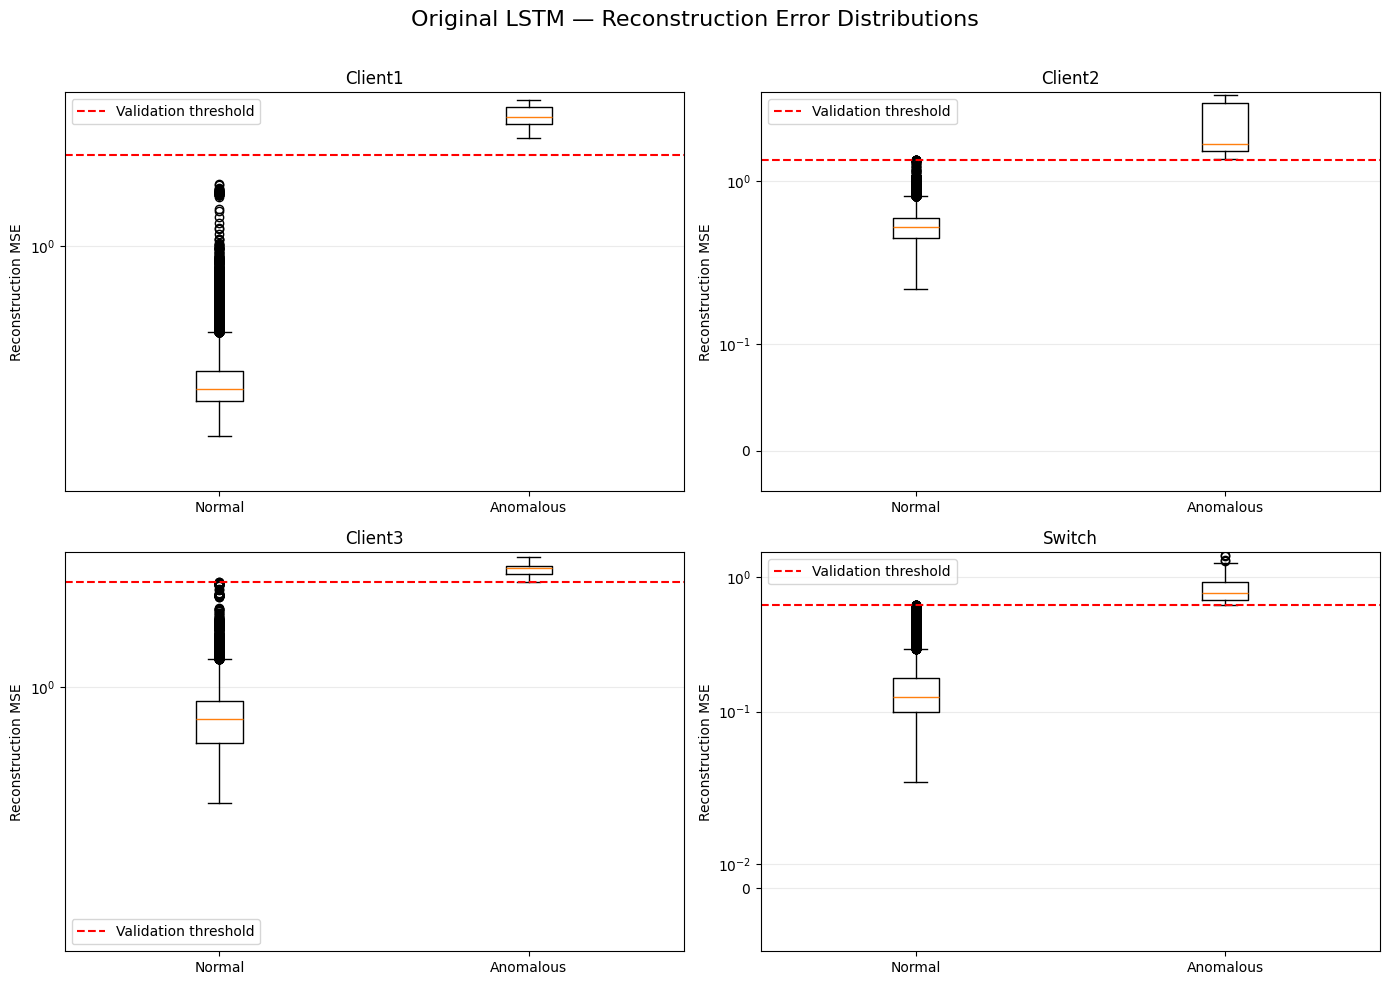


10.7 — Normalised reconstruction-error comparison


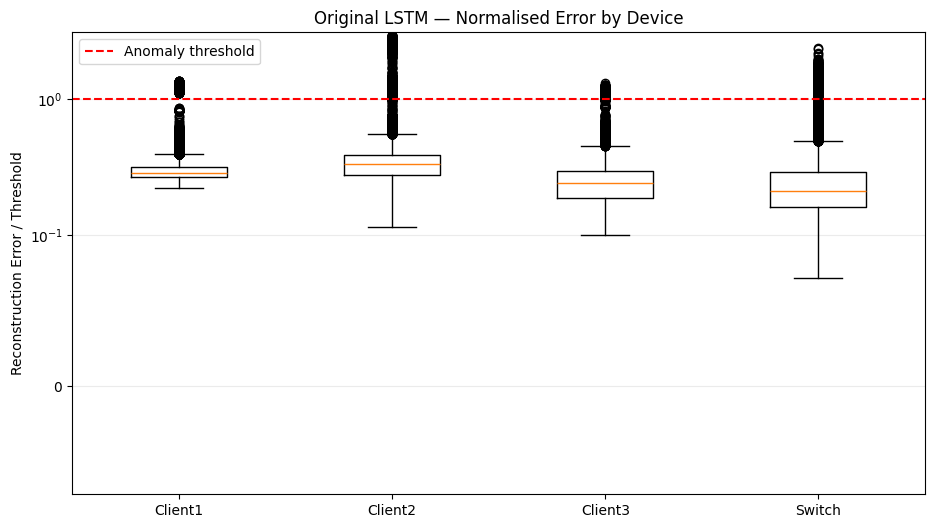


10.8 — Evaluating anomaly events

10.9 — Generating composite anomaly-event graphs


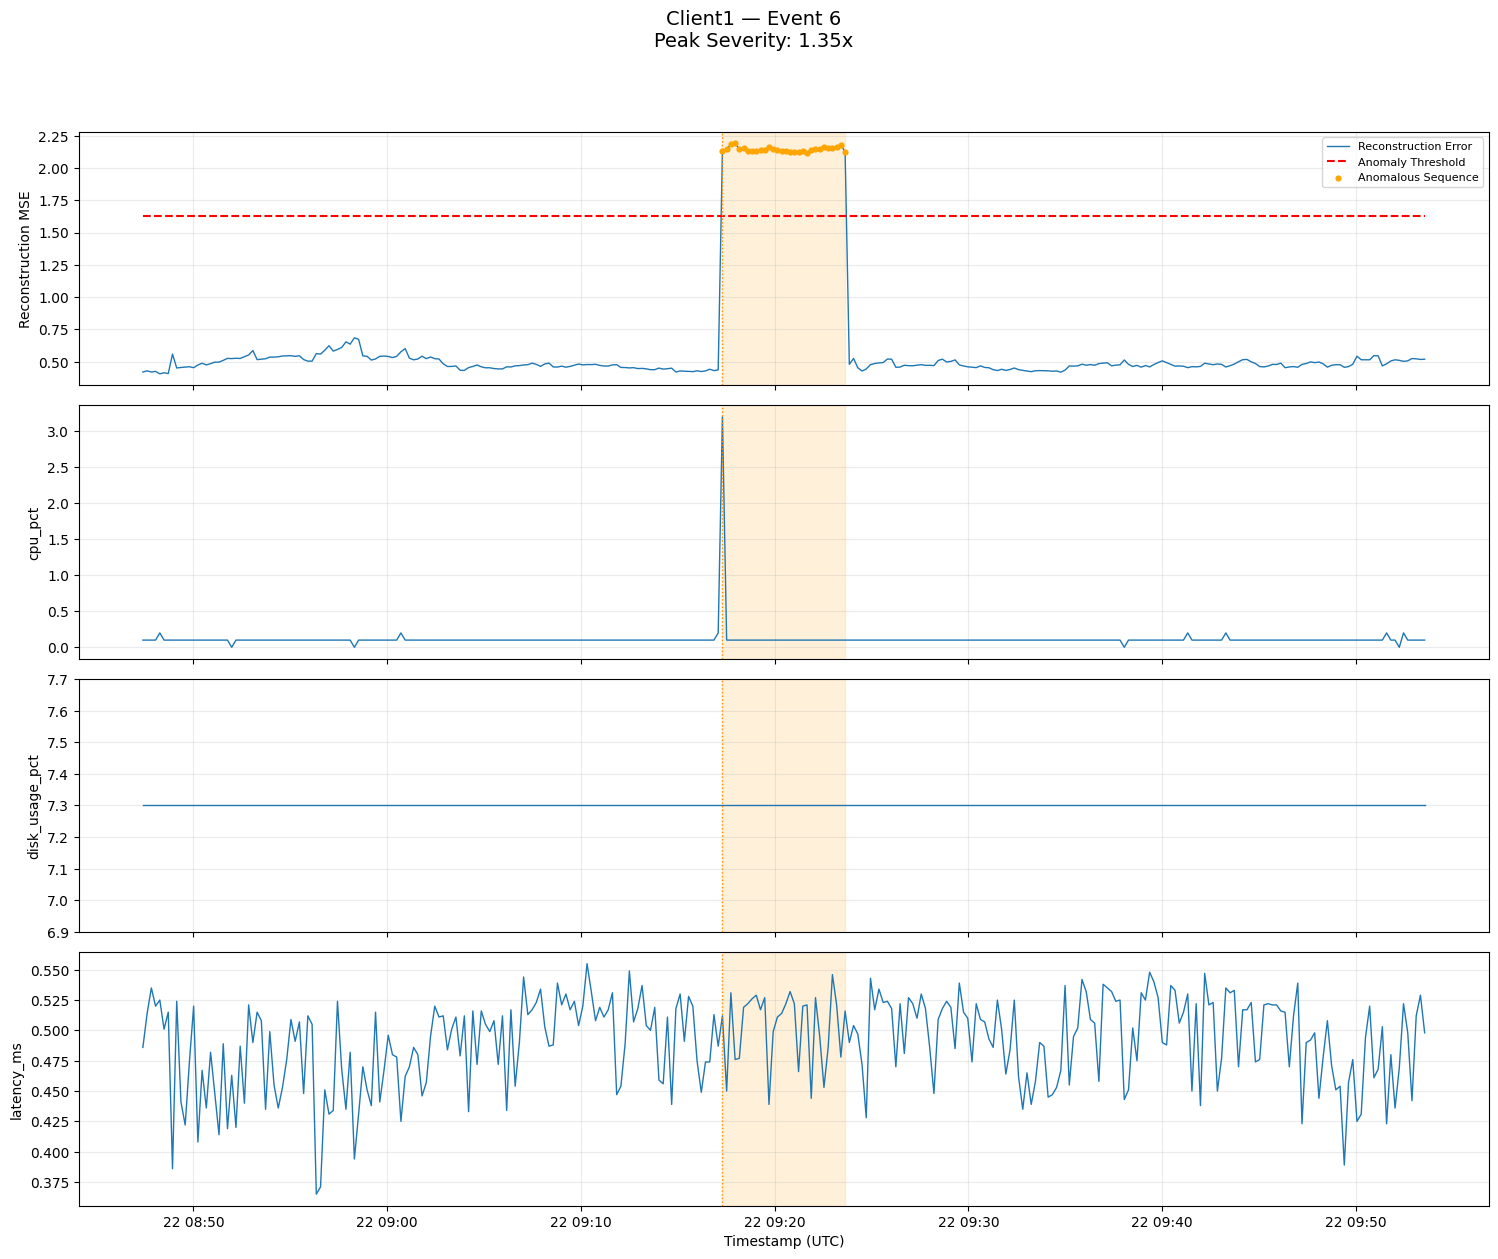

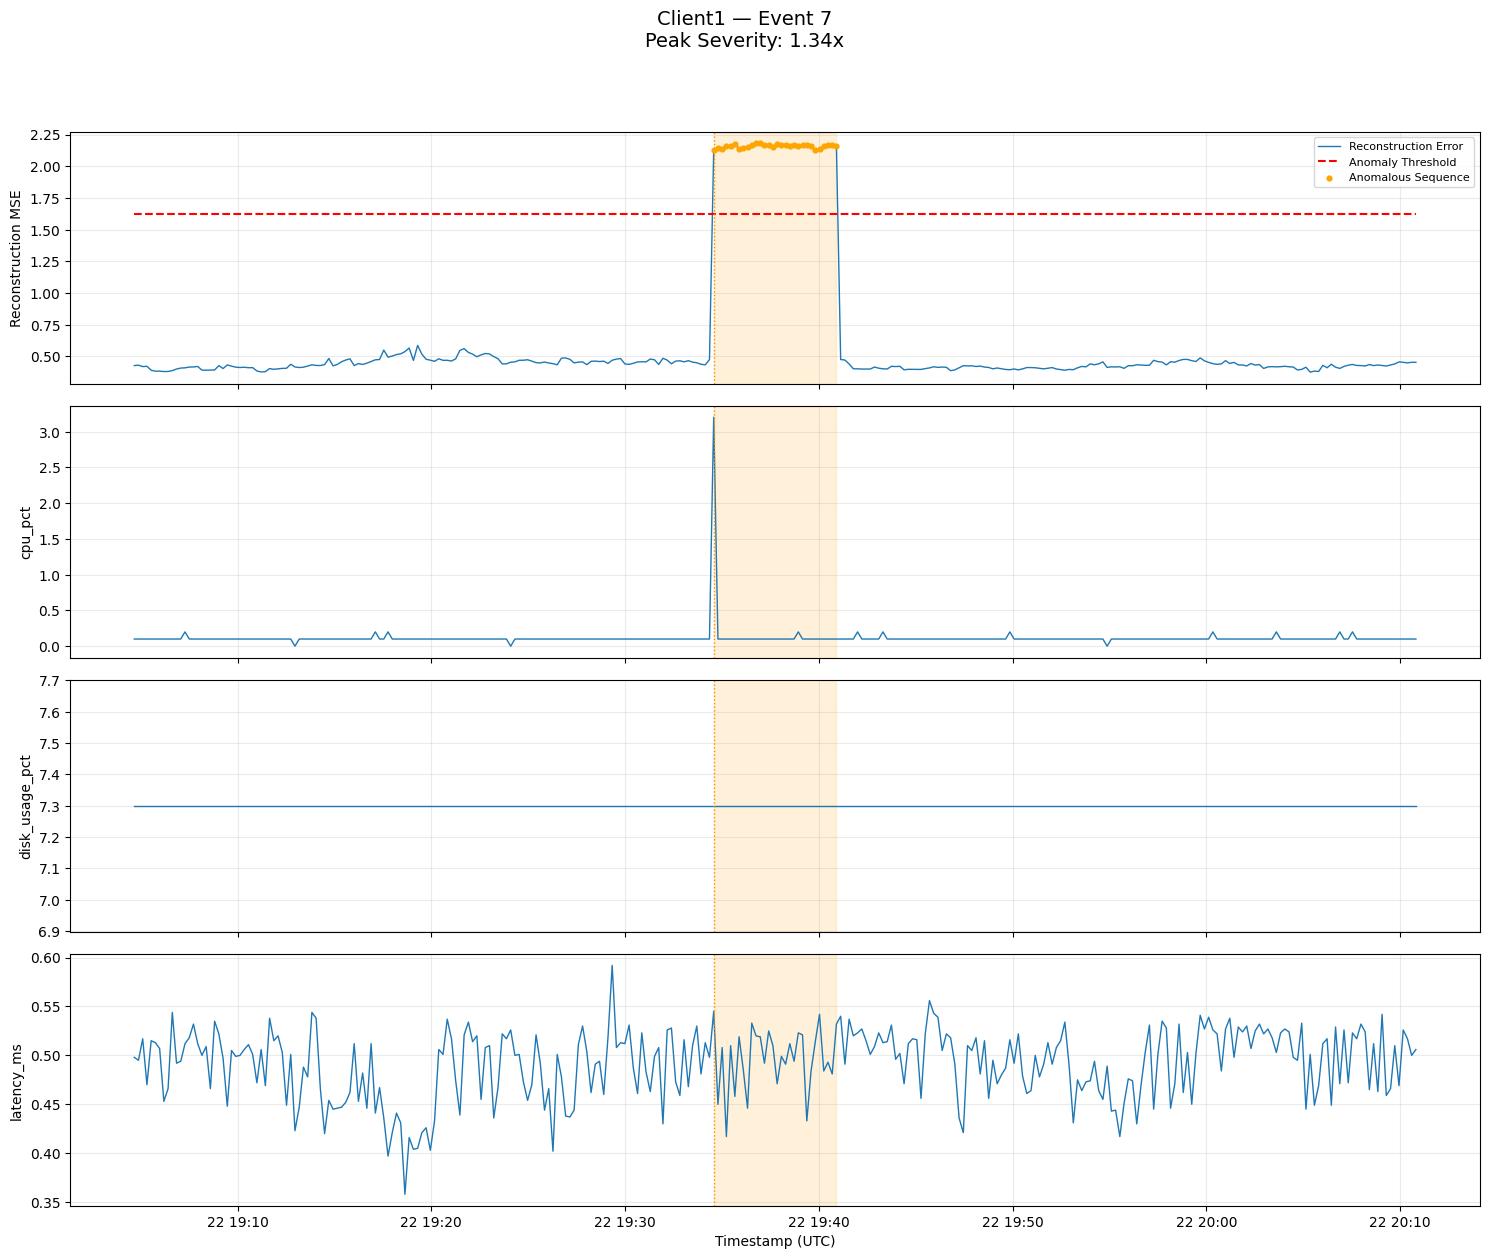

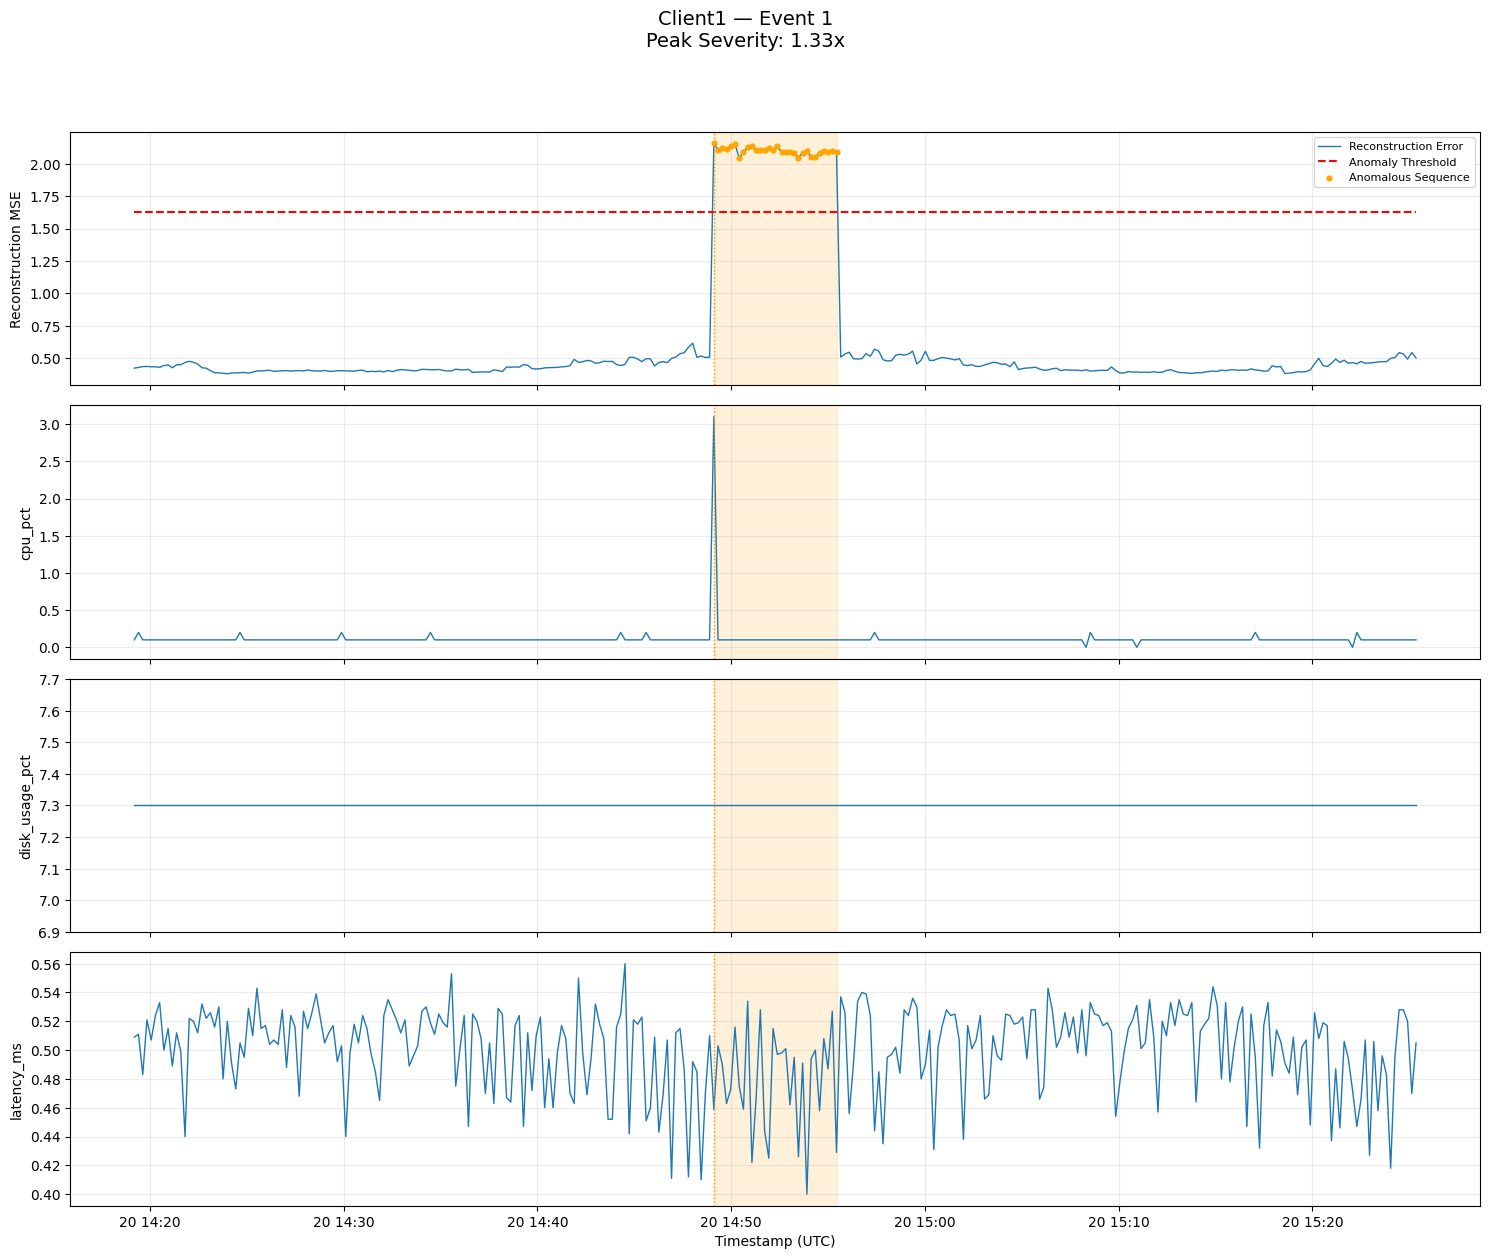

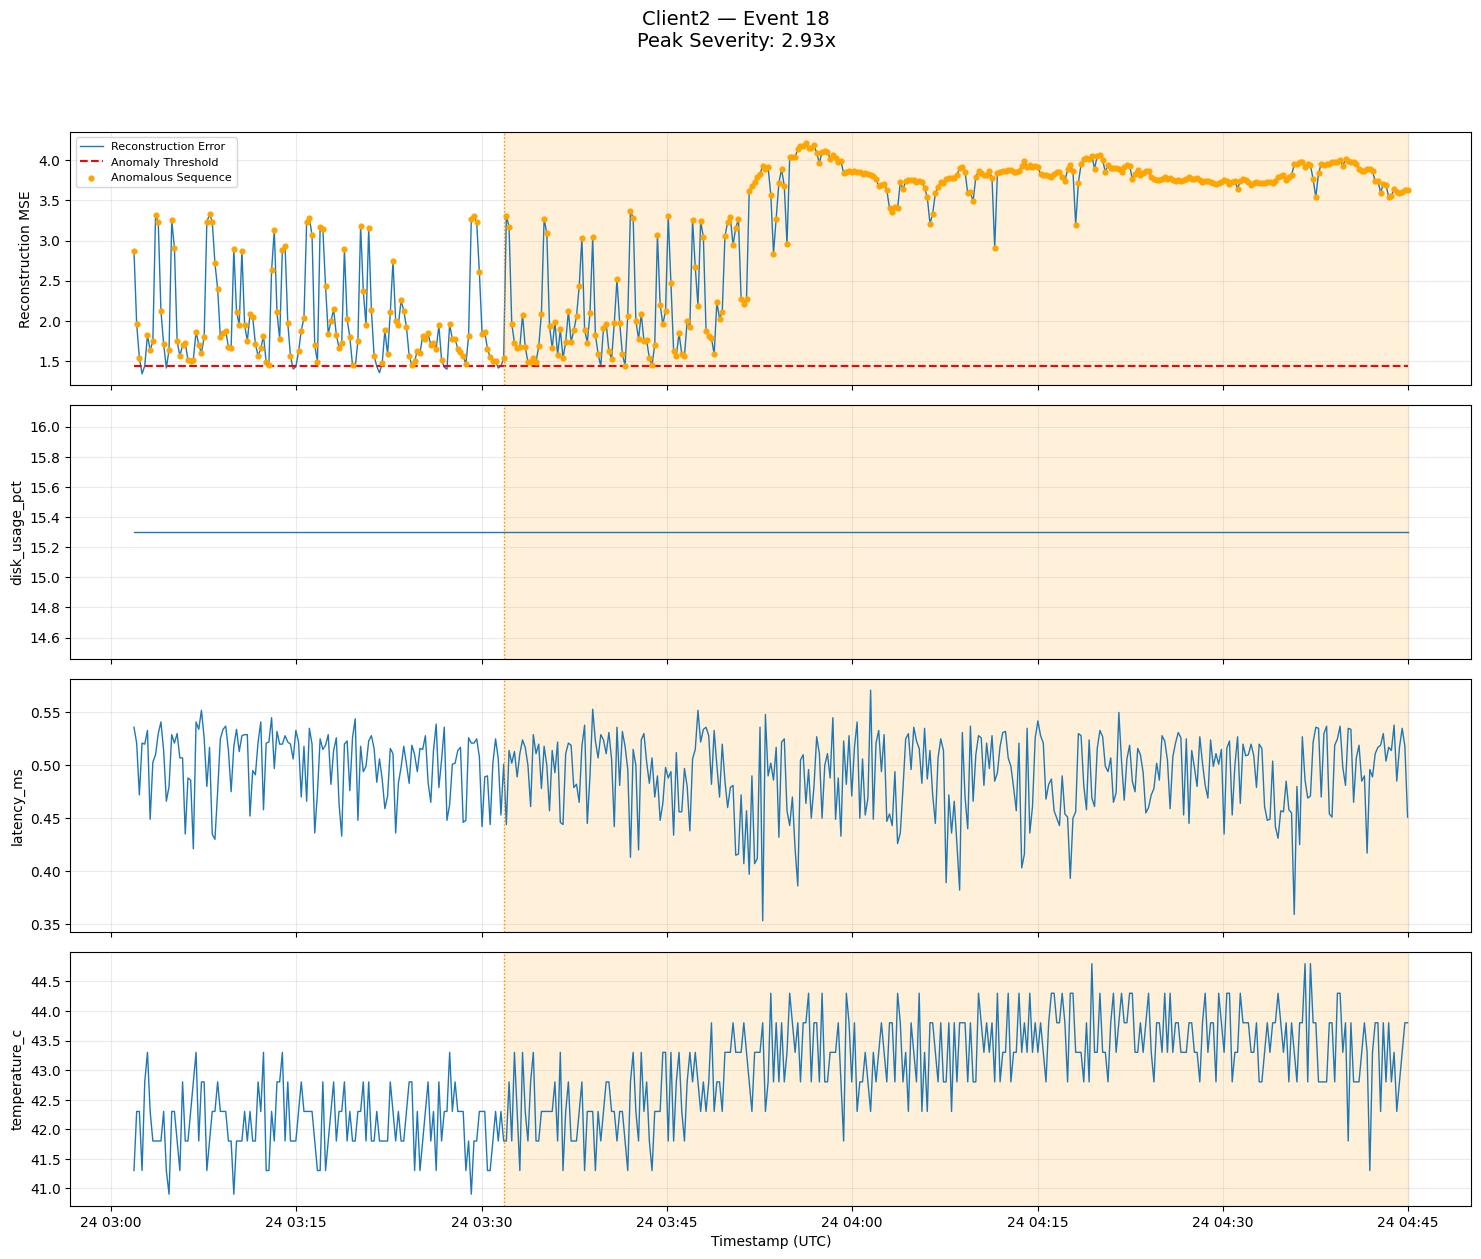

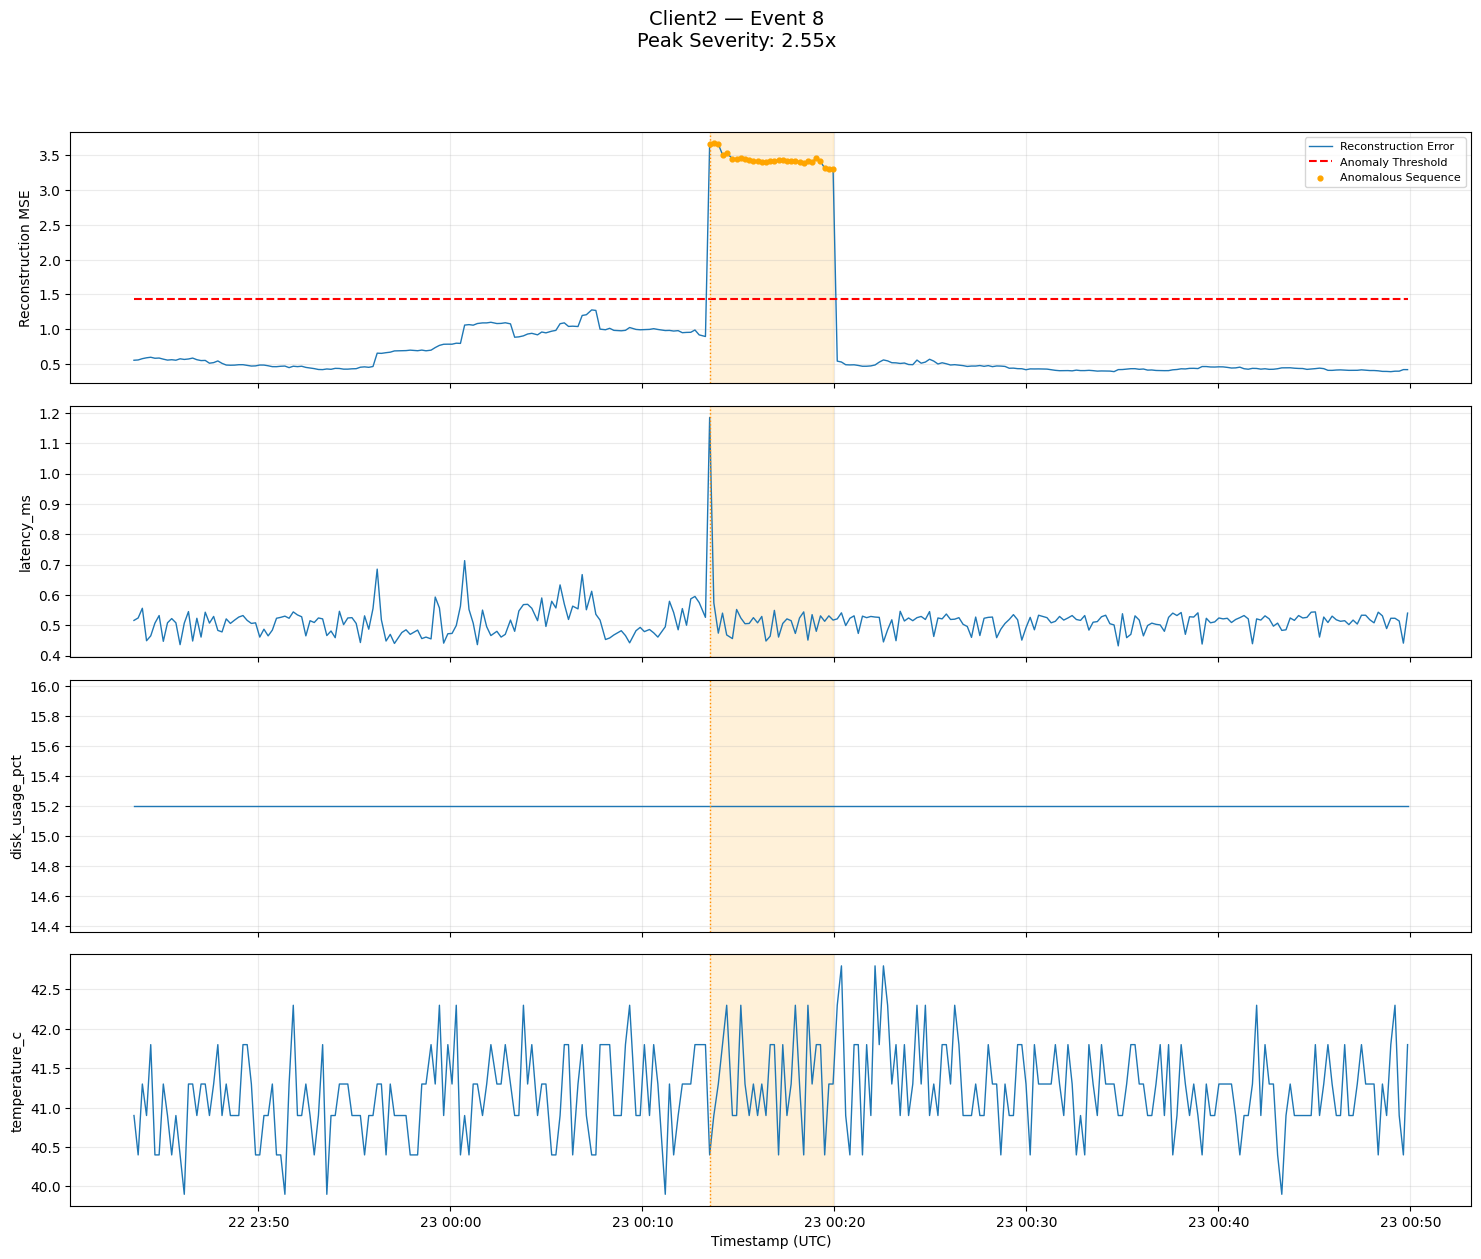

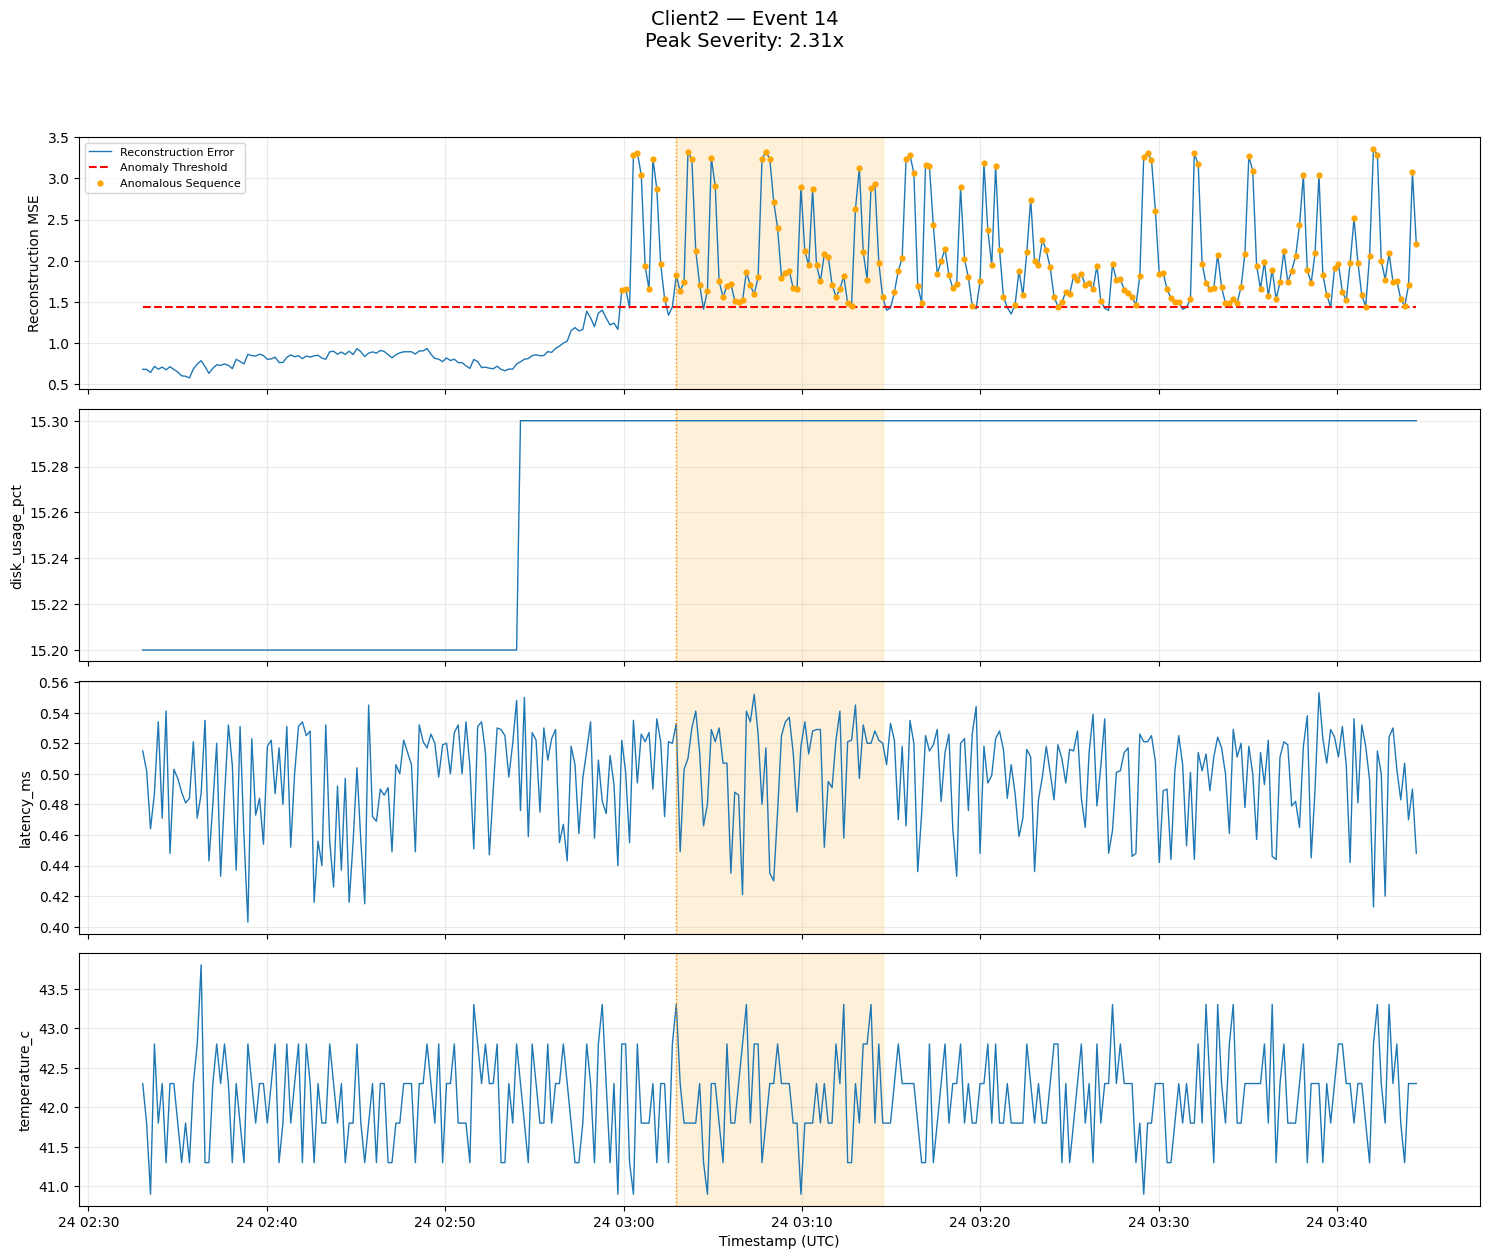

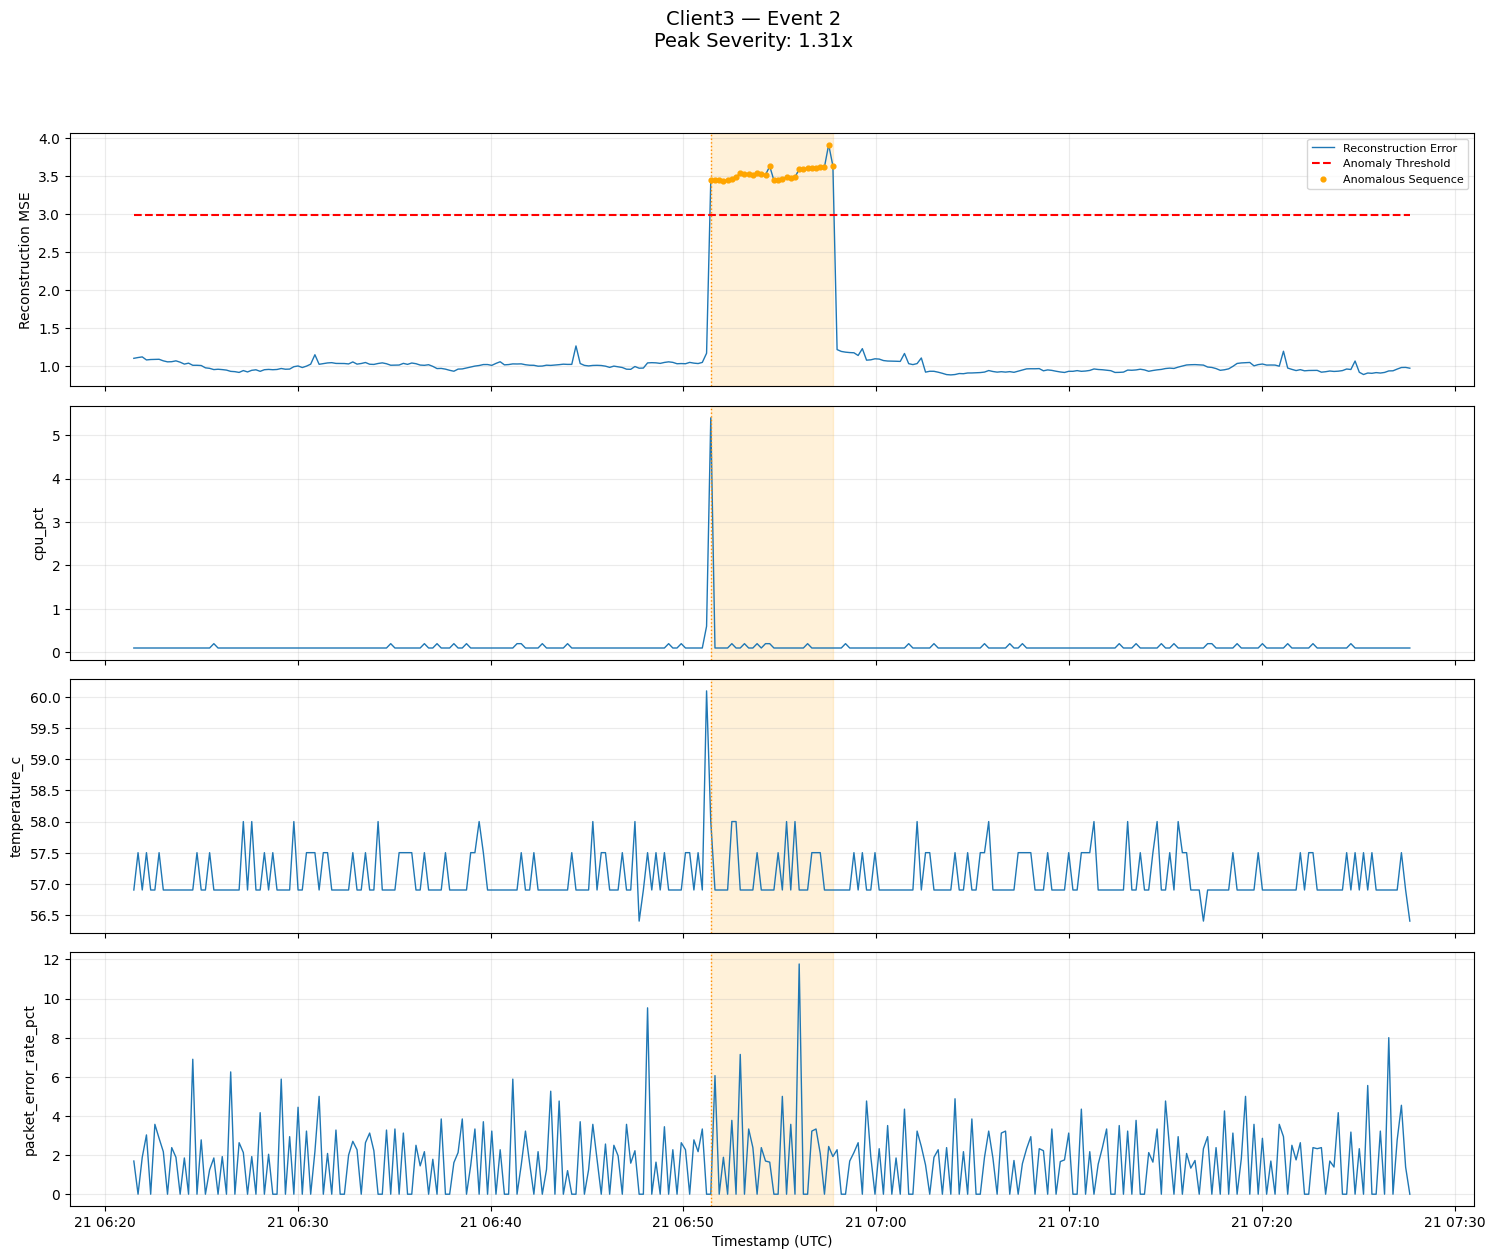

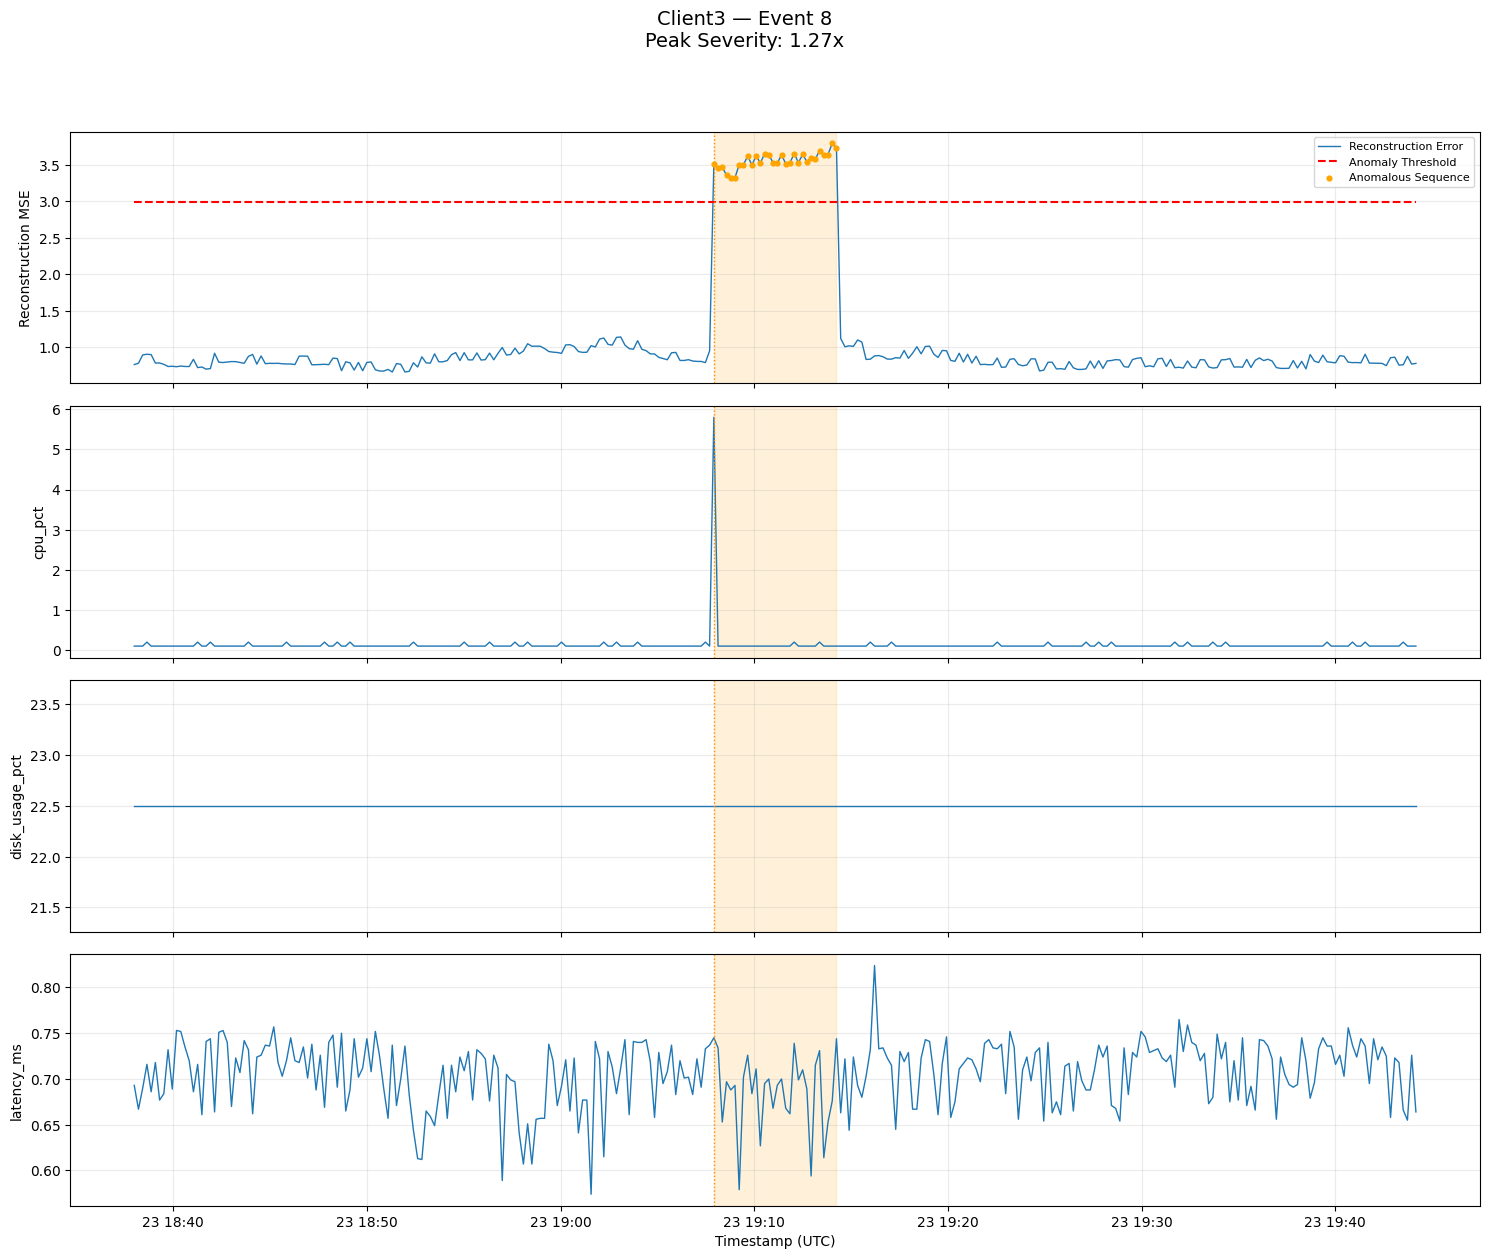

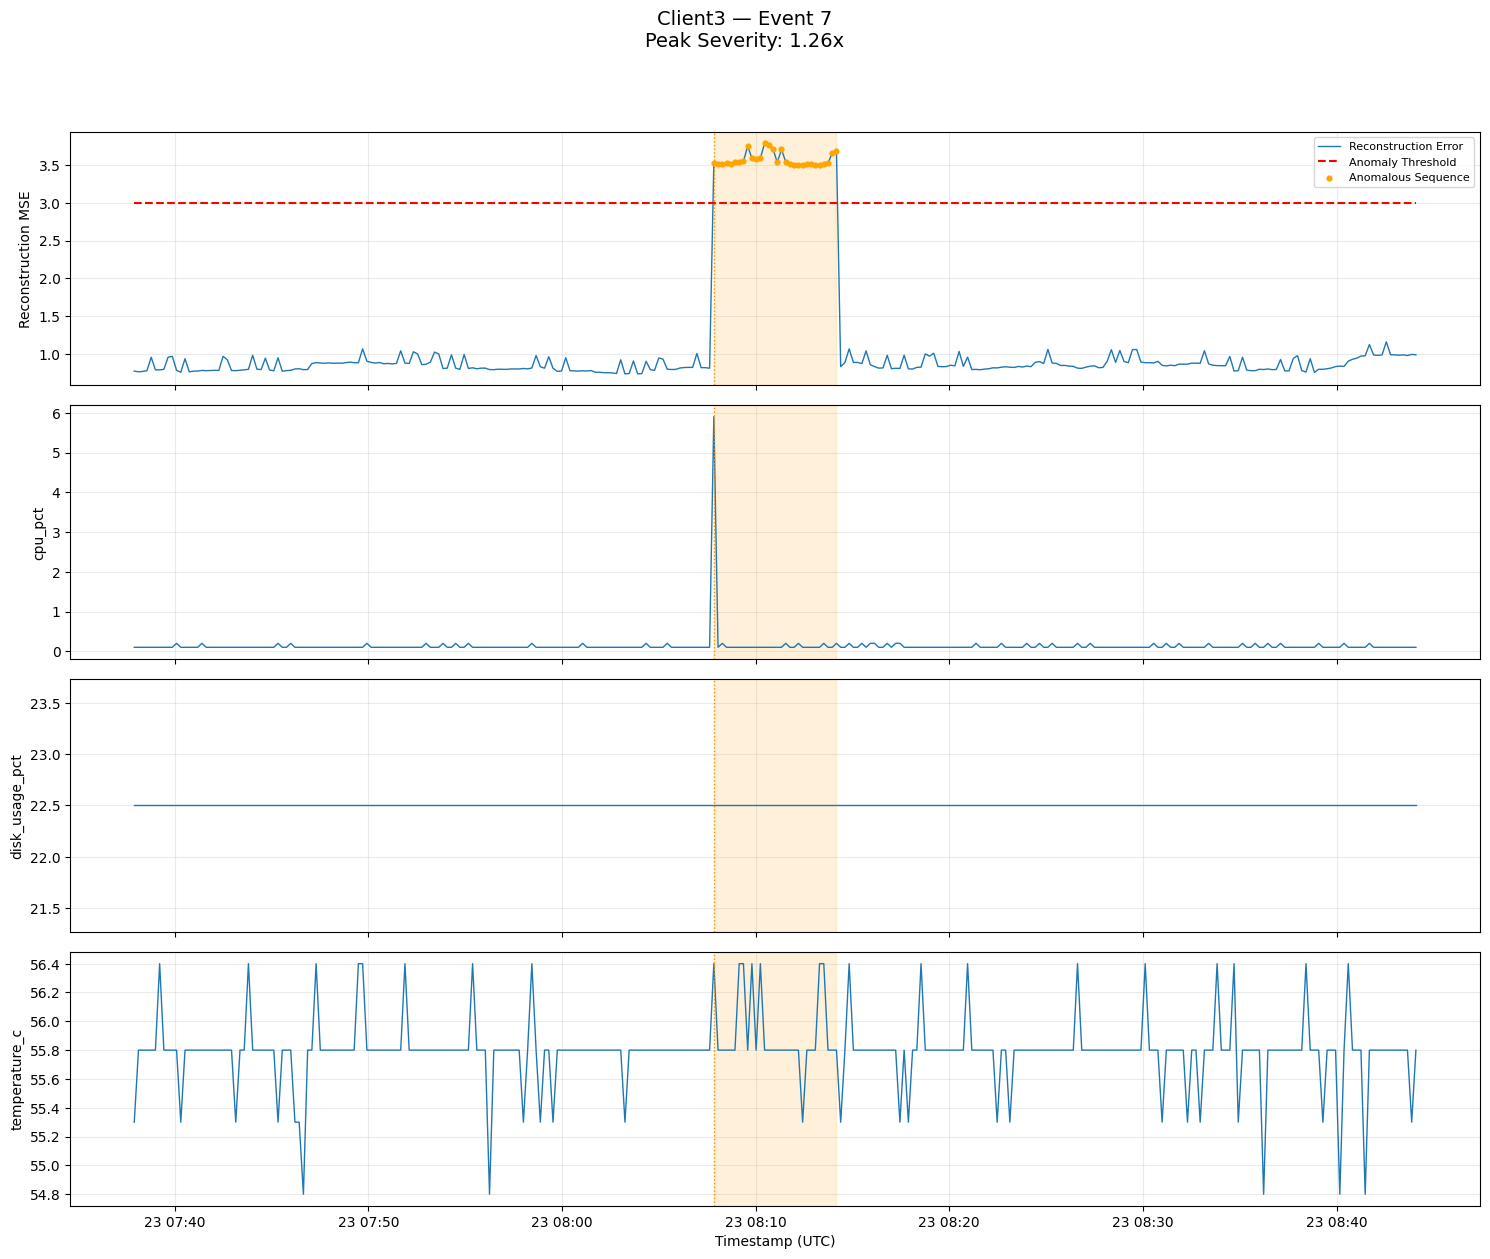

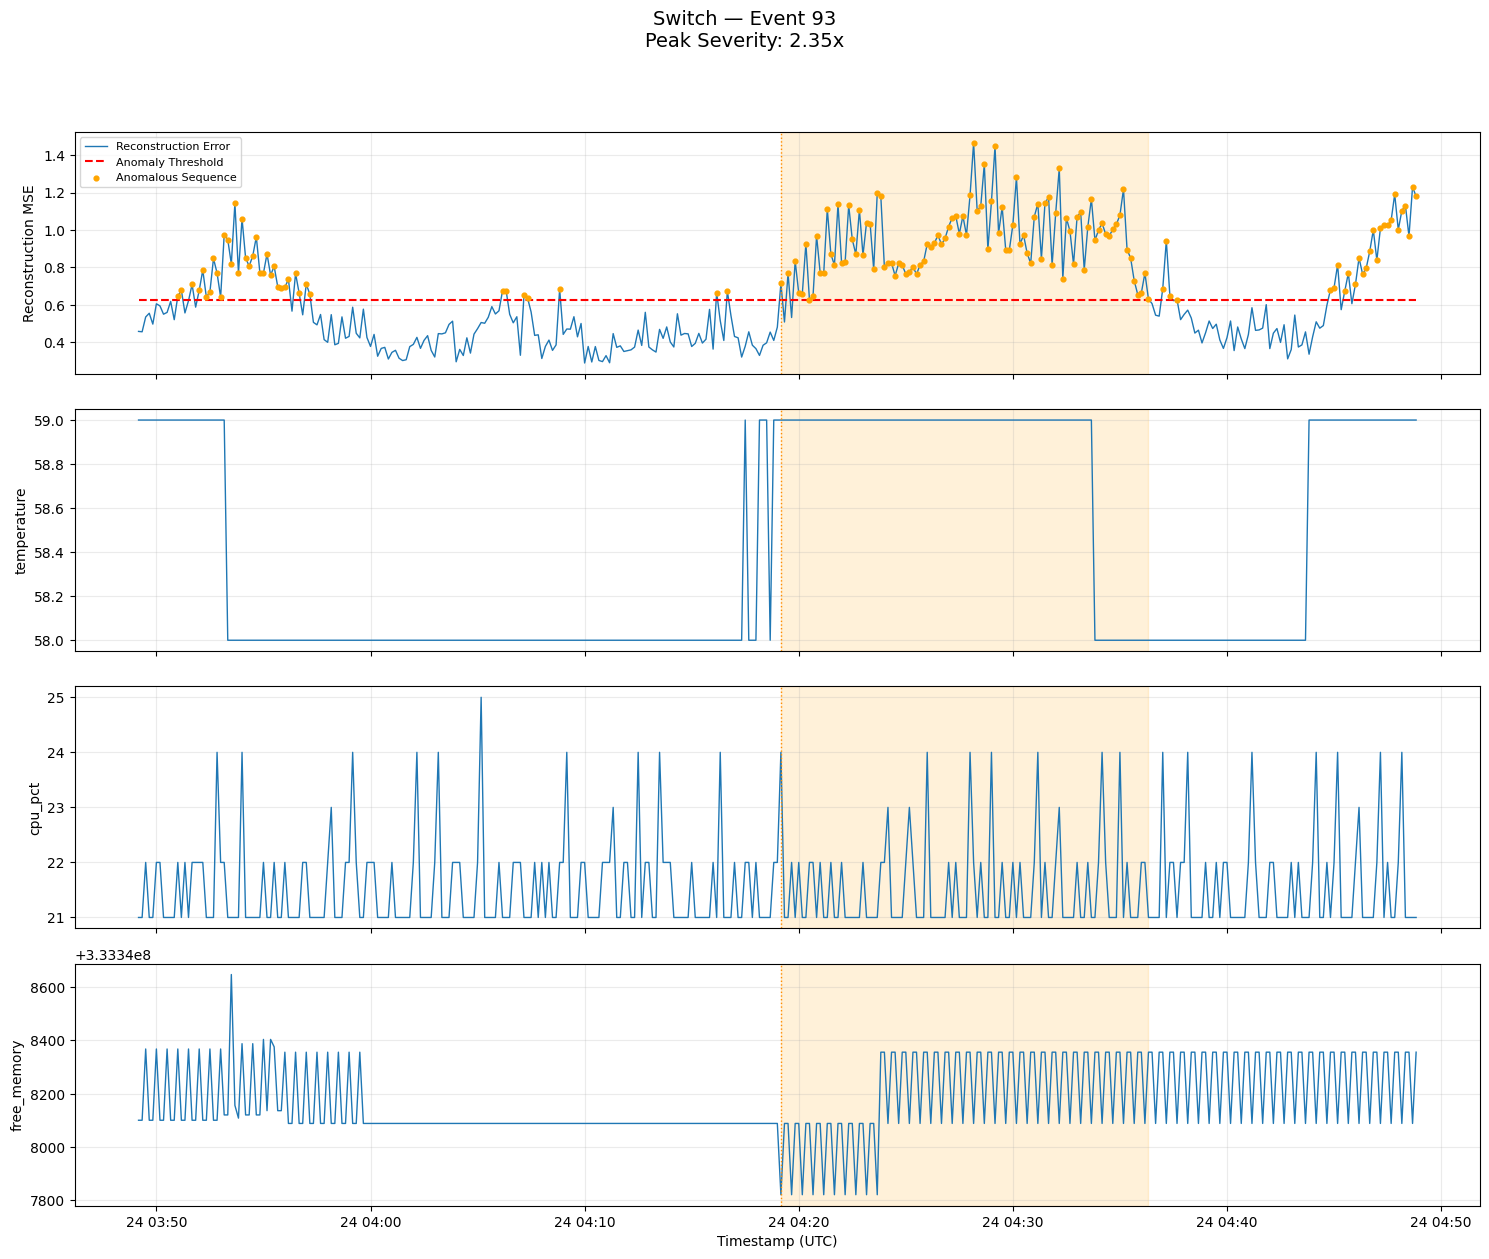

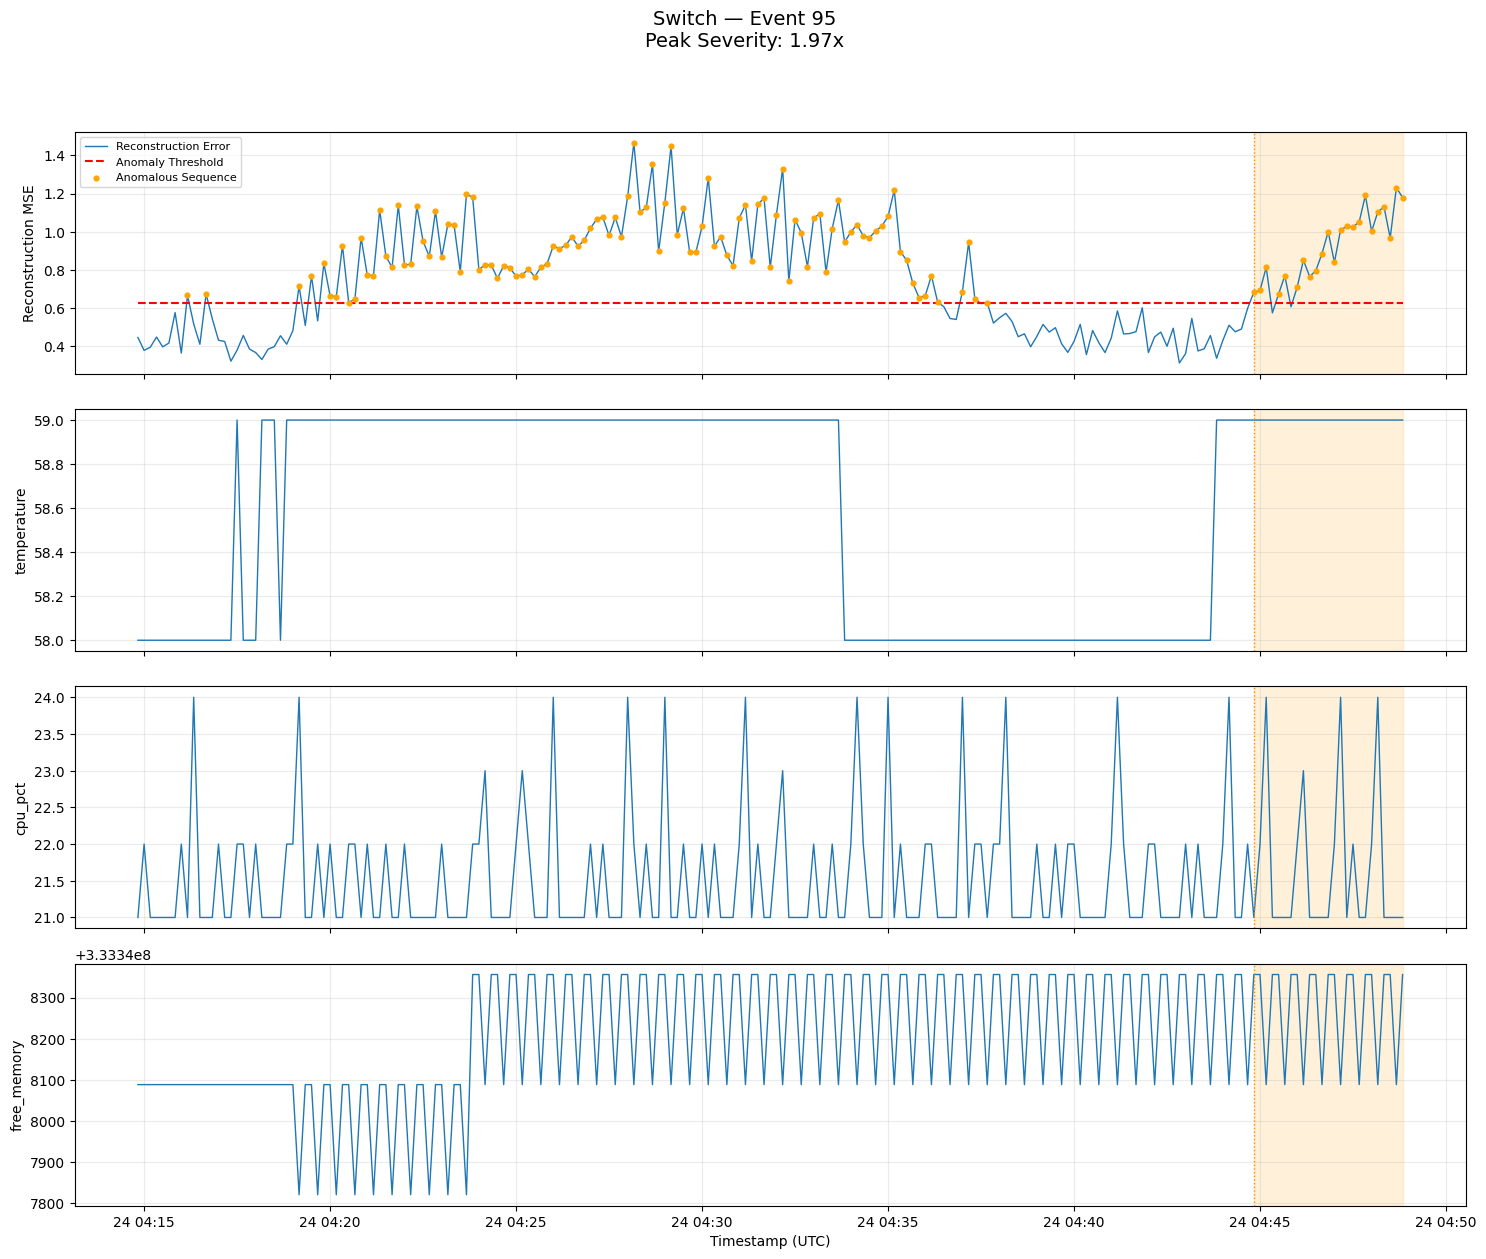

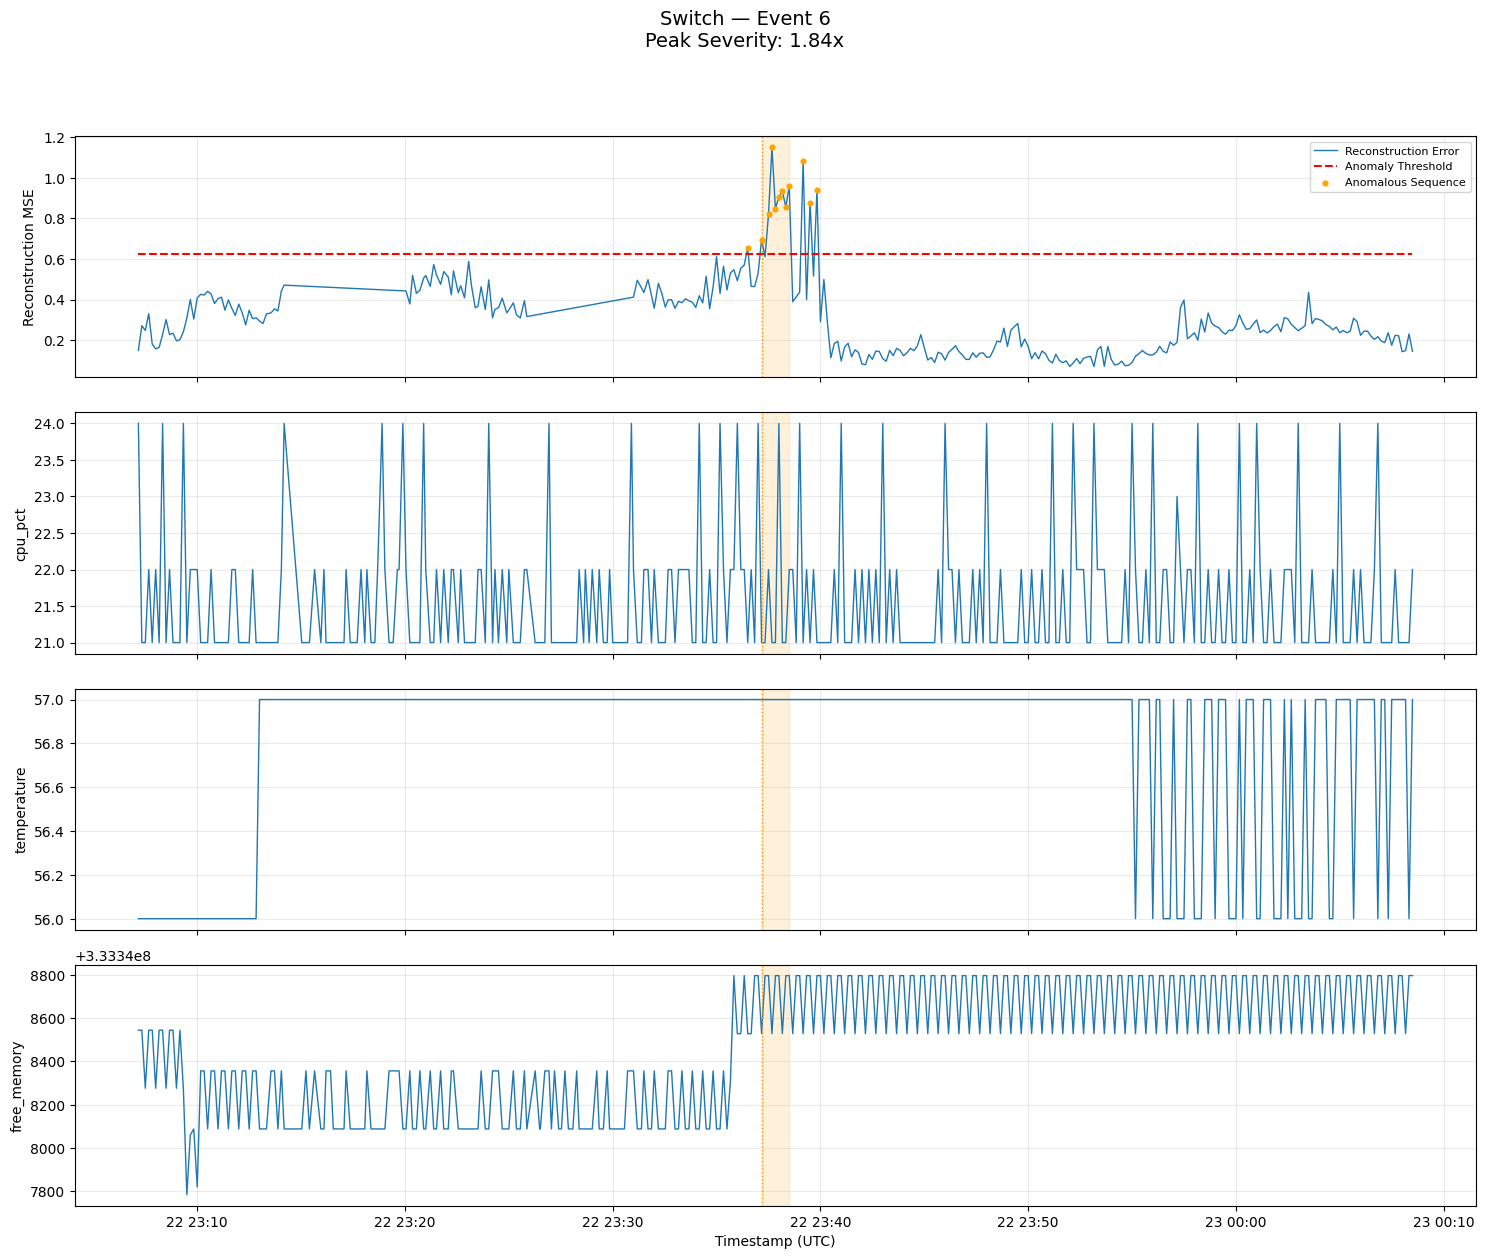


10.10 — Evaluating synthetic fault injections

10.11 — Fault detection performance


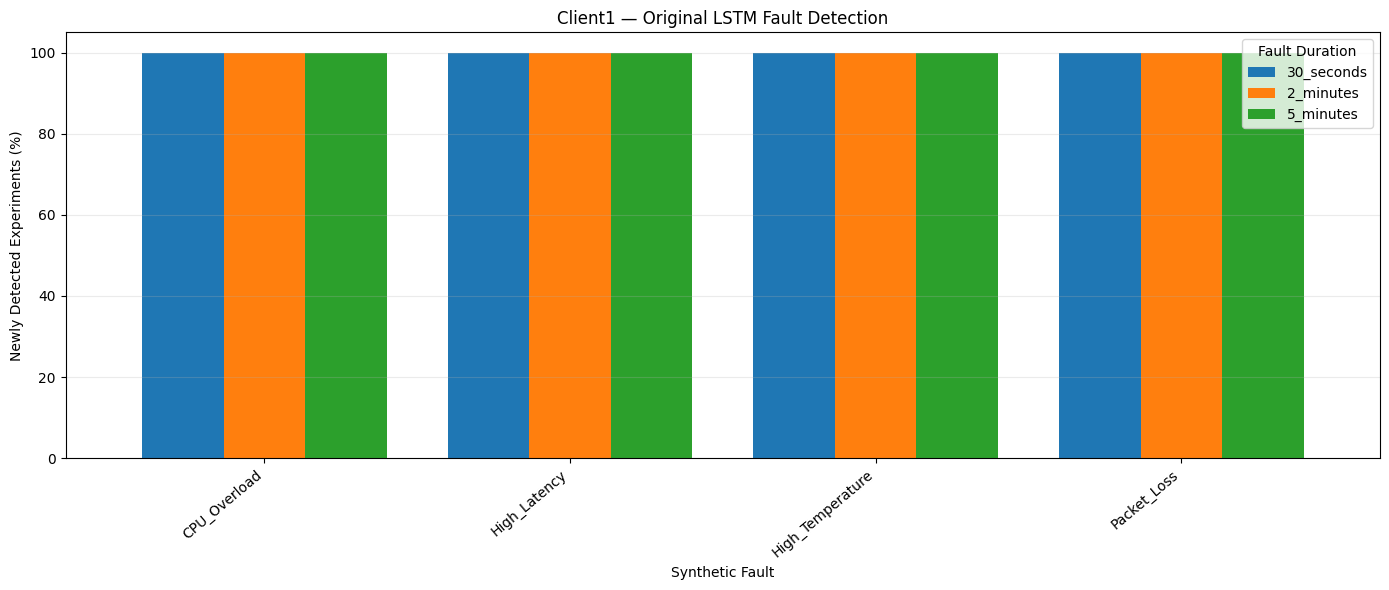

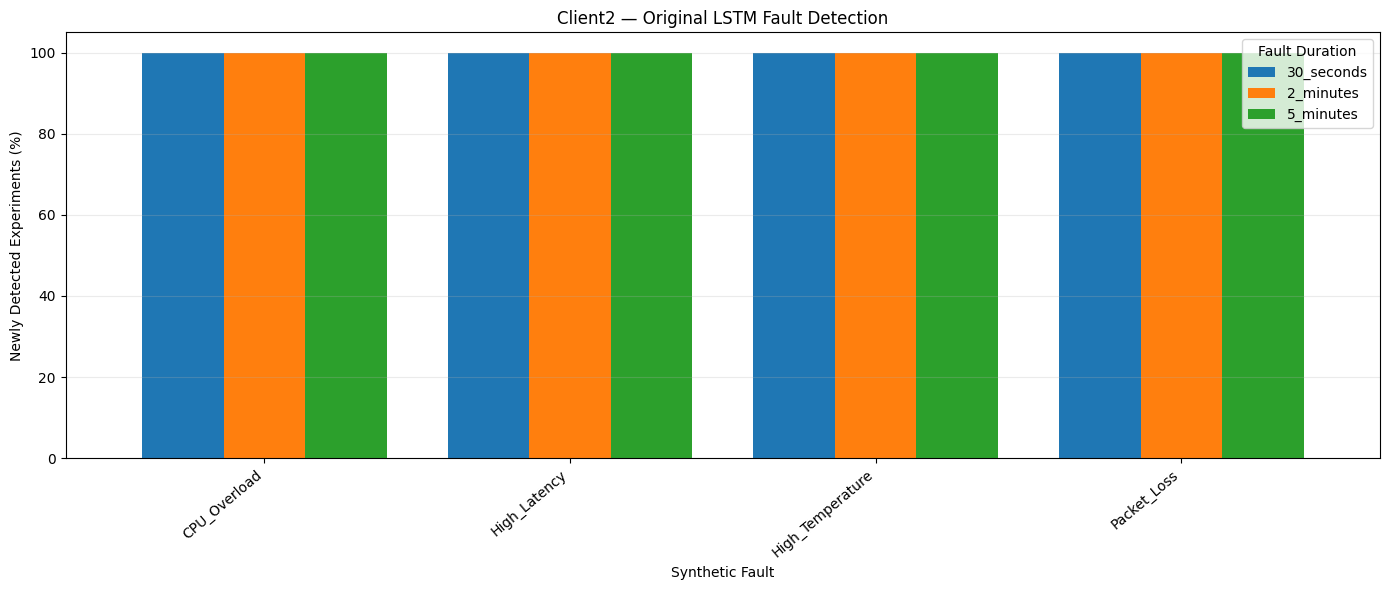

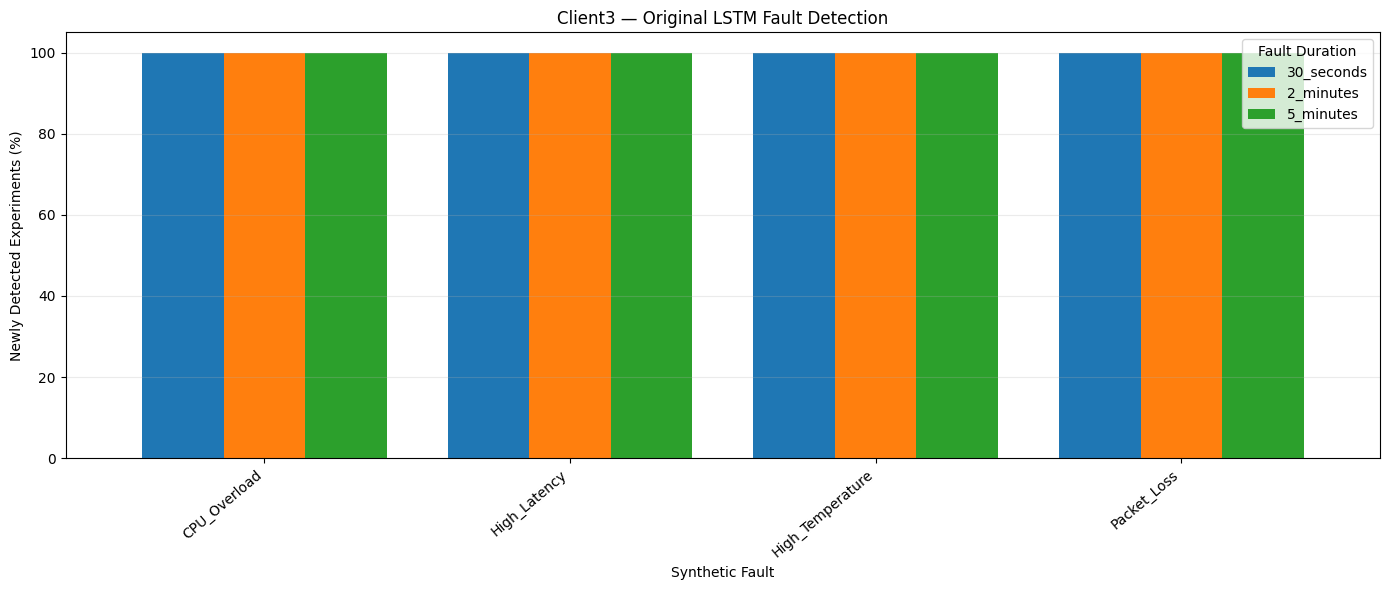

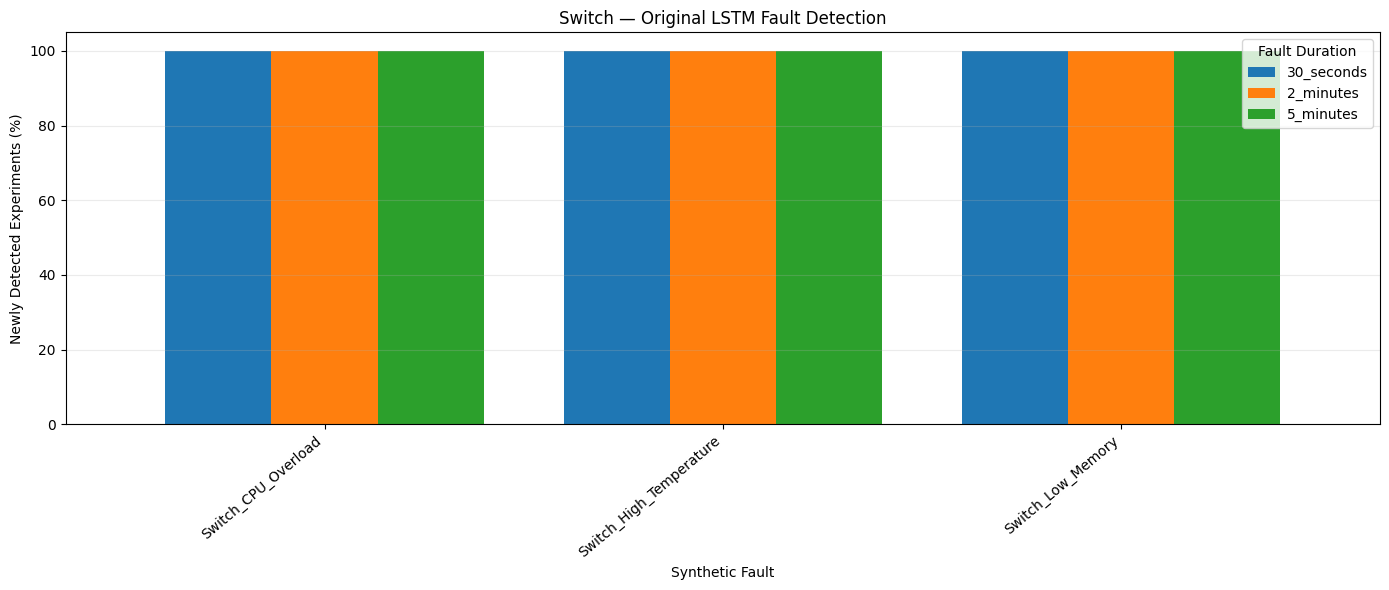

Loaded: c:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\LSTM_Results\Original_Fault_Injection\Original_Sequence_Results.csv
Cannot generate fault reconstruction-error box plots.
Missing columns: ['Fault']
Available columns: ['Experiment_ID', 'Device', 'timestamp', 'original_error', 'injected_error', 'original_anomaly', 'injected_anomaly', 'newly_detected']
Check whether Section 9 saved sequence-level fault-injection results.

SECTION 10.12 COMPLETE

10.13 — Original vs Expanded LSTM comparison
Experiment-level pairing unavailable. Both models must record injection number and start timestamp for paired comparison.

10.14 — Generating final results table

10.15 — Composite performance summary


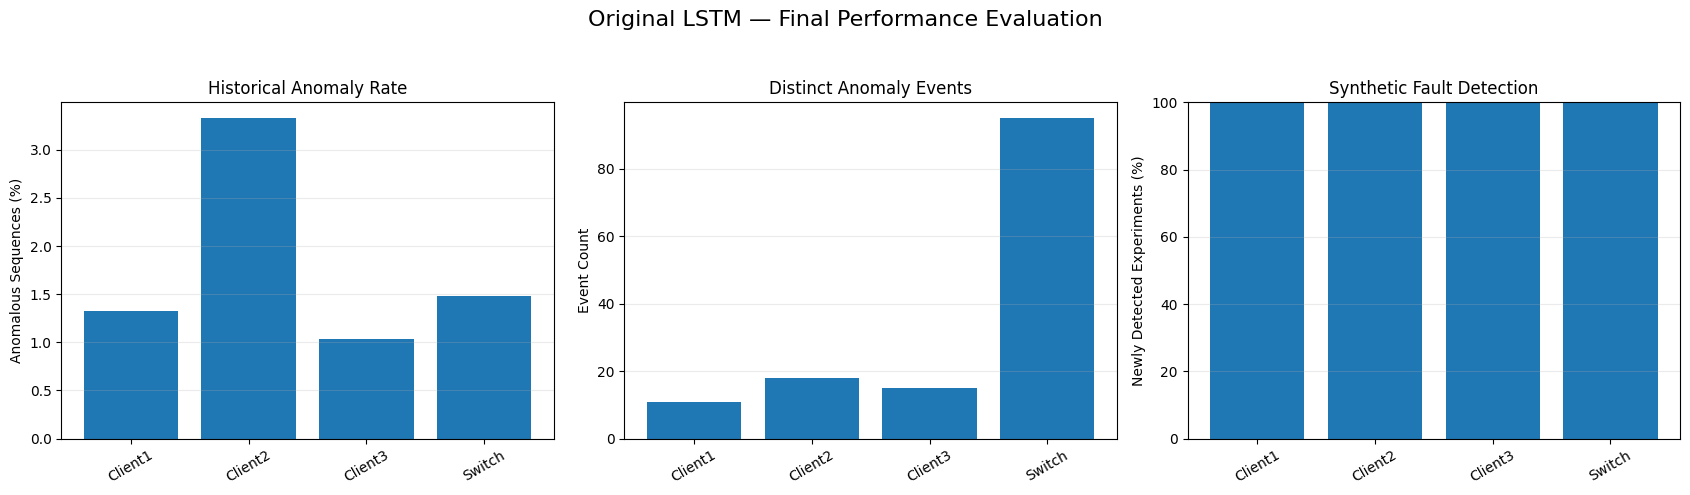


10.16 — Evaluating Capstone KPIs

CAPSTONE KPI SUMMARY:
 Device         Model  Synthetic_Recall_Pct  Synthetic_Recall_Target_Pct  Synthetic_Recall_Target_Met  Historical_Anomaly_Rate_Pct  False_Positive_Rate_Pct  Outperforms_Static_Thresholds  Data_Completeness_Pct  Total_Alerts  Attributed_Alerts  Explainability_Coverage_Pct
Client1 Original_LSTM                 100.0                         85.0                         True                     1.329198                      NaN                            NaN                    NaN           330                330                        100.0
Client2 Original_LSTM                 100.0                         85.0                         True                     3.327425                      NaN                            NaN                    NaN           826                826                        100.0
Client3 Original_LSTM                 100.0                         85.0                         True                     1.036

In [ ]:
# ================================================================
# SECTION 10 — FINAL RESULTS AND EVALUATION
# ORIGINAL-METRICS LSTM AUTOENCODER
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

# ================================================================
# 10.1 CONFIGURATION
# ================================================================

DEVICES = ["Client1", "Client2", "Client3", "Switch"]

BASE_DIR = Path.cwd()

ORIGINAL_DIR = BASE_DIR / "LSTM_Results"
EXPANDED_DIR = BASE_DIR / "Expanded_LSTM_Results"

if not ORIGINAL_DIR.exists():
    raise FileNotFoundError(
        "LSTM_Results directory not found."
    )

FINAL_DIR = ORIGINAL_DIR / "Final_Evaluation"

BOX_DIR = FINAL_DIR / "Box_Plots"
COMPOSITE_DIR = FINAL_DIR / "Composite_Plots"
FAULT_PLOT_DIR = FINAL_DIR / "Fault_Injection_Plots"
COMPARISON_DIR = FINAL_DIR / "Model_Comparison"
TABLE_DIR = FINAL_DIR / "Tables"

for folder in [
    FINAL_DIR,
    BOX_DIR,
    COMPOSITE_DIR,
    FAULT_PLOT_DIR,
    COMPARISON_DIR,
    TABLE_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

DPI = 200
SHOW_OUTLIERS = True

TOP_EVENTS = 3
CONTEXT_MINUTES = 30

DURATION_ORDER = [
    "30_seconds",
    "2_minutes",
    "5_minutes"
]

COMMON_CLIENT_FAULTS = [
    "CPU_Overload",
    "High_Latency",
    "Packet_Loss",
    "High_Temperature"
]

COMMON_SWITCH_FAULTS = [
    "Switch_CPU_Overload",
    "Switch_High_Temperature",
    "Switch_Low_Memory"
]

plt.rcParams.update({
    "figure.figsize": (12, 6),
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.grid": False
})

# ================================================================
# 10.2 GENERAL HELPER FUNCTIONS
# ================================================================

def numeric_values(values):

    return (
        pd.to_numeric(
            pd.Series(values),
            errors="coerce"
        )
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )


def bool_values(values):

    return (
        pd.Series(values)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )


def save_plot(directory, filename):

    plt.savefig(
        directory / filename,
        dpi=DPI,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


def valid_boxplot(ax, series_list, labels, title, ylabel):

    cleaned = [
        numeric_values(values).to_numpy()
        for values in series_list
    ]

    valid = [
        (values, label)
        for values, label in zip(cleaned, labels)
        if len(values) > 0
    ]

    if not valid:
        ax.text(
            0.5, 0.5,
            "No valid data",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        ax.set_title(title)
        return

    data, names = zip(*valid)

    ax.boxplot(
        data,
        tick_labels=names,
        showfliers=SHOW_OUTLIERS
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)


def metric_statistics(values):

    values = numeric_values(values)

    if values.empty:
        return {
            "Samples": 0,
            "Min": np.nan,
            "Q1": np.nan,
            "Median": np.nan,
            "Q3": np.nan,
            "Max": np.nan,
            "Mean": np.nan,
            "Std": np.nan
        }

    return {
        "Samples": len(values),
        "Min": float(values.min()),
        "Q1": float(values.quantile(0.25)),
        "Median": float(values.median()),
        "Q3": float(values.quantile(0.75)),
        "Max": float(values.max()),
        "Mean": float(values.mean()),
        "Std": float(values.std())
    }


def find_file(root, filenames):

    if isinstance(filenames, str):
        filenames = [filenames]

    if not root.exists():
        return None

    for filename in filenames:
        matches = sorted(root.rglob(filename))

        if matches:
            return matches[0]

    return None


def get_telemetry(device):

    if (
        "datasets" in globals()
        and device in datasets
    ):
        df = datasets[device].copy()

    else:
        path = (
            ORIGINAL_DIR / "Cleaned_Data"
            / f"{device}_Cleaned.csv"
        )

        if not path.exists():
            return None

        df = pd.read_csv(path)

    if "timestamp" not in df.columns:
        if "_time" in df.columns:
            df = df.rename(
                columns={"_time": "timestamp"}
            )
        else:
            return None

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True,
        errors="coerce"
    )

    return (
        df.dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )


def normalise_event_columns(events):

    # Support the original LSTM's capitalised
    # column names and the expanded model's format.

    aliases = {
        "Event_ID": "event_id",
        "Start_Time": "start_time",
        "End_Time": "end_time",
        "Duration_Minutes": "duration_minutes",
        "Peak_Severity_Ratio": "peak_threshold_ratio",
        "Dominant_Metric": "dominant_metric",
        "Top_3_Metrics": "top_3_metrics"
    }

    return events.rename(columns=aliases)


def standardise_fault_results(df):

    df = df.copy()

    # Original Section 9 and expanded-test Section 9
    # use slightly different naming conventions.

    aliases = {
        "Fault_Type": "Fault",
        "Newly_Detected": "Newly_Detected_Any",
        "Detected": "Detected_Any",
        "Peak_Severity_Ratio": "Peak_Threshold_Ratio",
        "New_Detection_Delay_Seconds":
            "Detection_Delay_Seconds"
    }

    for old, new in aliases.items():
        if old in df.columns and new not in df.columns:
            df = df.rename(columns={old: new})

    if "Duration" not in df.columns:

        if "Duration_Seconds" not in df.columns:
            raise ValueError(
                "Fault results have no duration column."
            )

        duration_map = {
            30: "30_seconds",
            120: "2_minutes",
            300: "5_minutes"
        }

        df["Duration"] = (
            pd.to_numeric(df["Duration_Seconds"])
            .map(duration_map)
        )

    for col in ["Detected_Any", "Newly_Detected_Any"]:

        if col not in df.columns:
            raise ValueError(
                f"Missing fault result column: {col}"
            )

        df[col] = bool_values(df[col]).to_numpy()

    if "Detection_Delay_Seconds" not in df.columns:
        df["Detection_Delay_Seconds"] = np.nan

    if "Experiment_ID" not in df.columns:
        df["Experiment_ID"] = [
            f"Original_Experiment_{i + 1}"
            for i in range(len(df))
        ]

    if "Injection_Number" not in df.columns:
        df["Injection_Number"] = np.nan

    if "Peak_Threshold_Ratio" not in df.columns:
        df["Peak_Threshold_Ratio"] = np.nan

    return df


# ================================================================
# 10.3 LOAD ORIGINAL LSTM RESULTS
# ================================================================

print("\n10.3 — Loading original LSTM results")

anomaly_data = {}
event_data = {}
telemetry_data = {}

# ------------------------------------------------------------
# 10.3.1 Load anomaly detection results
# ------------------------------------------------------------

for device in DEVICES:

    anomaly_path = (
        ORIGINAL_DIR
        / "Anomaly_Results"
        / f"{device}_Anomaly_Results.csv"
    )

    event_path = find_file(
        ORIGINAL_DIR / "Anomaly_Events",
        [
            f"{device}_Events.csv",
            f"{device}_Anomaly_Events.csv"
        ]
    )

    if not anomaly_path.exists():
        raise FileNotFoundError(anomaly_path)

    df = pd.read_csv(anomaly_path)

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True
    )

    df["is_anomaly"] = (
        bool_values(df["is_anomaly"]).to_numpy()
    )

    anomaly_data[device] = (
        df.sort_values("timestamp")
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Load event results
    # --------------------------------------------------------

    if event_path is not None:

        events = pd.read_csv(event_path)

        events = normalise_event_columns(events)

        if not events.empty:

            events["start_time"] = pd.to_datetime(
                events["start_time"],
                utc=True
            )

            events["end_time"] = pd.to_datetime(
                events["end_time"],
                utc=True
            )

        event_data[device] = events

    else:
        event_data[device] = pd.DataFrame()

    telemetry_data[device] = get_telemetry(device)

    print(
        f"{device}: "
        f"{len(anomaly_data[device])} test sequences"
    )

# ------------------------------------------------------------
# 10.3.2 Locate original synthetic fault results
# ------------------------------------------------------------

fault_file = find_file(
    ORIGINAL_DIR,
    [
        "Original_All_Fault_Injection_Results.csv",
        "Original_All_Fault_Results.csv",
        "Fault_Injection_Results.csv"
    ]
)

sequence_file = find_file(
    ORIGINAL_DIR,
    [
        "Original_All_Fault_Sequence_Results.csv",
        "Original_Sequence_Results.csv",
        "Fault_Sequence_Results.csv"
    ]
)

if fault_file is None:

    print("\nAvailable CSV files containing 'Fault':")

    for path in ORIGINAL_DIR.rglob("*Fault*.csv"):
        print(path.resolve())

    raise FileNotFoundError(
        "Original LSTM fault injection results not found. "
        "Run Section 9 before Section 10."
    )

fault_results = standardise_fault_results(
    pd.read_csv(fault_file)
)

fault_sequences = (
    pd.read_csv(sequence_file)
    if sequence_file is not None
    else pd.DataFrame()
)

if fault_results.empty:
    raise ValueError(
        "Original fault injection results are empty."
    )

print("\n" + "=" * 70)
print("SECTION 10 — ORIGINAL LSTM EVALUATION")
print("=" * 70)

print("Devices loaded:", len(anomaly_data))
print("Fault experiments:", len(fault_results))
print("Sequence-level records:", len(fault_sequences))
print("Fault file:", fault_file.resolve())


# ================================================================
# 10.4 RAW TELEMETRY — ORIGINAL METRIC BOX PLOTS
# ================================================================

print("\n10.4 — Generating original telemetry box plots")

telemetry_stats = []

for device in DEVICES:

    telemetry = telemetry_data[device]

    if telemetry is None:
        print(device, "— telemetry unavailable")
        continue

    if (
        "device_metrics" in globals()
        and device in device_metrics
    ):
        metrics = list(device_metrics[device])

    else:
        metrics = [
            col for col in telemetry.columns
            if col != "timestamp"
            and pd.api.types.is_numeric_dtype(
                telemetry[col]
            )
        ]

    metrics = [
        metric for metric in metrics
        if metric in telemetry.columns
    ]

    if not metrics:
        continue

    columns = 3
    rows = int(np.ceil(len(metrics) / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(18, rows * 3.7),
        squeeze=False
    )

    axes = axes.flatten()

    for index, metric in enumerate(metrics):

        values = numeric_values(
            telemetry[metric]
        )

        valid_boxplot(
            axes[index],
            [values],
            [metric],
            metric,
            "Recorded value"
        )

        axes[index].tick_params(
            axis="x",
            labelbottom=False
        )

        stats = metric_statistics(values)

        stats.update({
            "Device": device,
            "Metric": metric
        })

        telemetry_stats.append(stats)

    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.suptitle(
        f"{device} — Original Telemetry Metrics",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0, 1, 0.97])

    save_plot(
        BOX_DIR,
        f"{device}_Original_Telemetry_Boxplots.png"
    )

telemetry_stats_df = pd.DataFrame(
    telemetry_stats
)

telemetry_stats_df.to_csv(
    TABLE_DIR / "Original_Telemetry_Statistics.csv",
    index=False
)


# ================================================================
# 10.5 PER-METRIC RECONSTRUCTION ERROR BOX PLOTS
# ================================================================

print("\n10.5 — Per-metric reconstruction-error box plots")

metric_error_stats = []

for device in DEVICES:

    results = anomaly_data[device]

    metric_columns = [
        col for col in results.columns
        if col.endswith("_error")
        and col not in [
            "reconstruction_error",
            "most_unusual_metric_error"
        ]
    ]

    if not metric_columns:
        print(device, "— No per-metric errors found")
        continue

    columns = 3
    rows = int(np.ceil(
        len(metric_columns) / columns
    ))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(18, rows * 3.7),
        squeeze=False
    )

    axes = axes.flatten()

    for index, column in enumerate(metric_columns):

        metric = column.removesuffix("_error")

        values = numeric_values(
            results[column]
        )

        valid_boxplot(
            axes[index],
            [values],
            [metric],
            metric,
            "Reconstruction MSE"
        )

        axes[index].tick_params(
            axis="x",
            labelbottom=False
        )

        stats = metric_statistics(values)

        stats.update({
            "Device": device,
            "Metric": metric
        })

        metric_error_stats.append(stats)

    for ax in axes[len(metric_columns):]:
        ax.set_visible(False)

    fig.suptitle(
        f"{device} — Original Metric Reconstruction Errors",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0, 1, 0.97])

    save_plot(
        BOX_DIR,
        f"{device}_Metric_Error_Boxplots.png"
    )

metric_error_stats_df = pd.DataFrame(
    metric_error_stats
)

metric_error_stats_df.to_csv(
    TABLE_DIR / "Original_Metric_Error_Statistics.csv",
    index=False
)


# ================================================================
# 10.6 OVERALL RECONSTRUCTION ERROR BOX PLOTS
# ================================================================

print("\n10.6 — Overall reconstruction error comparison")

device_summary = []

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for ax, device in zip(
    axes.flatten(),
    DEVICES
):

    results = anomaly_data[device]

    threshold = float(
        results["threshold"].iloc[0]
    )

    errors = numeric_values(
        results["reconstruction_error"]
    )

    normal = results.loc[
        ~results["is_anomaly"],
        "reconstruction_error"
    ]

    abnormal = results.loc[
        results["is_anomaly"],
        "reconstruction_error"
    ]

    valid_boxplot(
        ax,
        [normal, abnormal],
        ["Normal", "Anomalous"],
        device,
        "Reconstruction MSE"
    )

    ax.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Validation threshold"
    )

    ax.set_yscale(
        "symlog",
        linthresh=max(threshold / 10, 1e-6)
    )

    ax.legend()

    anomaly_count = int(
        results["is_anomaly"].sum()
    )

    device_summary.append({
        "Device": device,
        "Test_Sequences": len(results),
        "Anomalous_Sequences": anomaly_count,
        "Anomaly_Rate_Pct": (
            anomaly_count / len(results) * 100
        ),
        "Threshold": threshold,
        "Mean_Test_Error": errors.mean(),
        "Median_Test_Error": errors.median(),
        "P99_Test_Error": errors.quantile(0.99),
        "Maximum_Test_Error": errors.max()
    })

fig.suptitle(
    "Original LSTM — Reconstruction Error Distributions",
    fontsize=16
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

save_plot(
    BOX_DIR,
    "Original_Device_Reconstruction_Error_Boxplots.png"
)

device_summary_df = pd.DataFrame(
    device_summary
)


# ================================================================
# 10.7 NORMALISED RECONSTRUCTION ERROR COMPARISON
# ================================================================

print("\n10.7 — Normalised reconstruction-error comparison")

normalised_data = []

for device in DEVICES:

    results = anomaly_data[device]

    threshold = float(
        results["threshold"].iloc[0]
    )

    if threshold <= 0:
        raise ValueError(
            f"{device}: Invalid reconstruction threshold"
        )

    ratios = (
        results["reconstruction_error"] / threshold
    )

    normalised_data.append(
        numeric_values(ratios)
    )

fig, ax = plt.subplots(figsize=(11, 6))

valid_boxplot(
    ax,
    normalised_data,
    DEVICES,
    "Original LSTM — Normalised Error by Device",
    "Reconstruction Error / Threshold"
)

ax.axhline(
    1.0,
    color="red",
    linestyle="--",
    label="Anomaly threshold"
)

ax.set_yscale(
    "symlog",
    linthresh=0.1
)

ax.legend()

save_plot(
    BOX_DIR,
    "Original_Normalised_Error_Comparison.png"
)


# ================================================================
# 10.8 ANOMALY EVENT EVALUATION
# ================================================================

print("\n10.8 — Evaluating anomaly events")

event_summary = []
combined_events = []

for device in DEVICES:

    events = event_data[device]

    if events.empty:

        event_summary.append({
            "Device": device,
            "Total_Events": 0,
            "Longest_Event_Minutes": 0,
            "Highest_Severity_Ratio": np.nan,
            "Strongest_Event_ID": np.nan,
            "Dominant_Metric": "N/A"
        })

        continue

    events = events.copy()
    events["Device"] = device

    combined_events.append(events)

    strongest = events.loc[
        events["peak_threshold_ratio"].idxmax()
    ]

    event_summary.append({
        "Device": device,
        "Total_Events": len(events),
        "Longest_Event_Minutes": float(
            events["duration_minutes"].max()
        ),
        "Highest_Severity_Ratio": float(
            events["peak_threshold_ratio"].max()
        ),
        "Strongest_Event_ID": strongest["event_id"],
        "Dominant_Metric": strongest["dominant_metric"]
    })

event_summary_df = pd.DataFrame(
    event_summary
)

event_summary_df.to_csv(
    TABLE_DIR / "Original_Event_Summary.csv",
    index=False
)

if combined_events:

    all_events_df = pd.concat(
        combined_events,
        ignore_index=True
    )

    all_events_df = all_events_df.sort_values(
        "peak_threshold_ratio",
        ascending=False
    )

    all_events_df.to_csv(
        TABLE_DIR / "Original_Events_Ranked.csv",
        index=False
    )


# ================================================================
# 10.9 COMPOSITE ANOMALY EVENT GRAPHS
# ================================================================

print("\n10.9 — Generating composite anomaly-event graphs")

for device in DEVICES:

    events = event_data[device]
    results = anomaly_data[device]
    telemetry = telemetry_data[device]

    if events.empty or telemetry is None:
        continue

    selected_events = (
        events.sort_values(
            "peak_threshold_ratio",
            ascending=False
        )
        .head(TOP_EVENTS)
    )

    for _, event in selected_events.iterrows():

        event_id = int(event["event_id"])

        start = event["start_time"]
        end = event["end_time"]

        plot_start = (
            start - pd.Timedelta(
                minutes=CONTEXT_MINUTES
            )
        )

        plot_end = (
            end + pd.Timedelta(
                minutes=CONTEXT_MINUTES
            )
        )

        # ----------------------------------------------------
        # Extract reconstruction errors around event
        # ----------------------------------------------------

        error_window = results.loc[
            (results["timestamp"] >= plot_start)
            & (results["timestamp"] <= plot_end)
        ]

        # ----------------------------------------------------
        # Extract recorded telemetry around event
        # ----------------------------------------------------

        telemetry_window = telemetry.loc[
            (telemetry["timestamp"] >= plot_start)
            & (telemetry["timestamp"] <= plot_end)
        ]

        candidate_metrics = [
            str(event["dominant_metric"])
        ]

        # Prefer the highest reconstruction-error metrics
        # at the event's peak anomalous sequence.

        event_errors = error_window.loc[
            (error_window["timestamp"] >= start)
            & (error_window["timestamp"] <= end)
        ]

        if not event_errors.empty:

            peak_row = event_errors.loc[
                event_errors["reconstruction_error"].idxmax()
            ]

            metric_error_columns = [
                col for col in results.columns
                if col.endswith("_error")
                and col not in [
                    "reconstruction_error",
                    "most_unusual_metric_error"
                ]
            ]

            ranked = sorted(
                metric_error_columns,
                key=lambda col: float(
                    peak_row[col]
                ) if pd.notna(peak_row[col])
                else -np.inf,
                reverse=True
            )

            candidate_metrics.extend([
                col.removesuffix("_error")
                for col in ranked[:3]
            ])

        candidate_metrics = [
            metric
            for metric in dict.fromkeys(
                candidate_metrics
            )
            if metric in telemetry_window.columns
        ][:3]

        n_panels = 1 + len(candidate_metrics)

        fig, axes = plt.subplots(
            n_panels,
            1,
            figsize=(15, 3.2 * n_panels),
            sharex=True,
            squeeze=False
        )

        axes = axes.flatten()

        # ----------------------------------------------------
        # Panel 1 — Reconstruction error and threshold
        # ----------------------------------------------------

        axes[0].plot(
            error_window["timestamp"],
            error_window["reconstruction_error"],
            label="Reconstruction Error",
            linewidth=1.0
        )

        axes[0].plot(
            error_window["timestamp"],
            error_window["threshold"],
            linestyle="--",
            color="red",
            label="Anomaly Threshold"
        )

        anomalous = error_window.loc[
            error_window["is_anomaly"]
        ]

        axes[0].scatter(
            anomalous["timestamp"],
            anomalous["reconstruction_error"],
            color="orange",
            s=12,
            label="Anomalous Sequence",
            zorder=3
        )

        axes[0].set_ylabel("Reconstruction MSE")
        axes[0].legend(loc="best", fontsize=8)

        # ----------------------------------------------------
        # Panels 2–4 — Recorded telemetry metrics
        # ----------------------------------------------------

        for index, metric in enumerate(
            candidate_metrics,
            start=1
        ):

            values = pd.to_numeric(
                telemetry_window[metric],
                errors="coerce"
            )

            axes[index].plot(
                telemetry_window["timestamp"],
                values,
                linewidth=1.0
            )

            axes[index].set_ylabel(metric)

        # ----------------------------------------------------
        # Highlight anomaly event
        # ----------------------------------------------------

        for ax in axes:

            ax.axvspan(
                start,
                end,
                color="orange",
                alpha=0.15
            )

            ax.axvline(
                start,
                color="darkorange",
                linestyle=":",
                linewidth=1
            )

            ax.grid(alpha=0.25)

        axes[-1].set_xlabel("Timestamp (UTC)")

        fig.suptitle(
            f"{device} — Event {event_id}\n"
            f"Peak Severity: "
            f"{event['peak_threshold_ratio']:.2f}x",
            fontsize=14
        )

        fig.tight_layout(rect=[0, 0, 1, 0.94])

        save_plot(
            COMPOSITE_DIR,
            f"{device}_Event_{event_id}_Composite.png"
        )


# ================================================================
# 10.10 SYNTHETIC FAULT-INJECTION EVALUATION
# ================================================================

print("\n10.10 — Evaluating synthetic fault injections")

fault_summary_df = (
    fault_results
    .groupby(
        ["Device", "Fault", "Duration"],
        as_index=False
    )
    .agg(
        Experiments=("Experiment_ID", "count"),
        Detected=("Detected_Any", "sum"),
        Newly_Detected=("Newly_Detected_Any", "sum"),
        Mean_Detection_Delay_Seconds=(
            "Detection_Delay_Seconds", "mean"
        ),
        Median_Peak_Threshold_Ratio=(
            "Peak_Threshold_Ratio", "median"
        )
    )
)

fault_summary_df["Detection_Rate_Pct"] = (
    fault_summary_df["Detected"]
    / fault_summary_df["Experiments"] * 100
)

fault_summary_df["New_Detection_Rate_Pct"] = (
    fault_summary_df["Newly_Detected"]
    / fault_summary_df["Experiments"] * 100
)

fault_summary_df.to_csv(
    TABLE_DIR / "Original_Fault_Injection_Summary.csv",
    index=False
)

# ------------------------------------------------------------
# Device-level summary
# ------------------------------------------------------------

device_fault_summary_df = (
    fault_results
    .groupby("Device", as_index=False)
    .agg(
        Experiments=("Experiment_ID", "count"),
        Detected=("Detected_Any", "sum"),
        Newly_Detected=("Newly_Detected_Any", "sum"),
        Mean_Detection_Delay_Seconds=(
            "Detection_Delay_Seconds", "mean"
        )
    )
)

device_fault_summary_df["Detection_Rate_Pct"] = (
    device_fault_summary_df["Detected"]
    / device_fault_summary_df["Experiments"] * 100
)

device_fault_summary_df["New_Detection_Rate_Pct"] = (
    device_fault_summary_df["Newly_Detected"]
    / device_fault_summary_df["Experiments"] * 100
)

device_fault_summary_df.to_csv(
    TABLE_DIR / "Original_Device_Fault_Summary.csv",
    index=False
)


# ================================================================
# 10.11 FAULT-DETECTION RATE PLOTS
# ================================================================

print("\n10.11 — Fault detection performance")

for device in DEVICES:

    sub = fault_summary_df.loc[
        fault_summary_df["Device"] == device
    ]

    if sub.empty:
        continue

    pivot = sub.pivot(
        index="Fault",
        columns="Duration",
        values="New_Detection_Rate_Pct"
    ).reindex(columns=DURATION_ORDER)

    ax = pivot.plot(
        kind="bar",
        figsize=(14, 6),
        width=0.8
    )

    ax.set_title(
        f"{device} — Original LSTM Fault Detection"
    )

    ax.set_xlabel("Synthetic Fault")
    ax.set_ylabel("Newly Detected Experiments (%)")
    ax.set_ylim(0, 105)
    ax.grid(axis="y", alpha=0.25)

    plt.xticks(rotation=40, ha="right")
    plt.legend(title="Fault Duration")

    plt.tight_layout()

    save_plot(
        FAULT_PLOT_DIR,
        f"{device}_Fault_Detection_Rates.png"
    )


# ================================================================
# 10.12 FAULT-INJECTION RECONSTRUCTION ERROR BOX PLOTS
# ================================================================

# ================================================================
# 10.12 FAULT-INJECTION RECONSTRUCTION ERROR BOX PLOTS
# FIXED — ORIGINAL METRICS LSTM
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ORIGINAL_DIR = Path.cwd() / "LSTM_Results"
BOX_DIR = ORIGINAL_DIR / "Final_Evaluation" / "Fault_Injection_Plots"
BOX_DIR.mkdir(parents=True, exist_ok=True)

DEVICES = ["Client1", "Client2", "Client3", "Switch"]

# ------------------------------------------------------------
# 10.12.1 Find saved sequence-level results
# ------------------------------------------------------------

filenames = [
    "Original_All_Fault_Sequence_Results.csv",
    "Original_Sequence_Results.csv",
    "Fault_Sequence_Results.csv"
]

sequence_path = None

for filename in filenames:
    matches = sorted(ORIGINAL_DIR.rglob(filename))
    if matches:
        sequence_path = matches[0]
        break

# ------------------------------------------------------------
# 10.12.2 Load and standardise columns
# ------------------------------------------------------------

if sequence_path is not None:
    fault_sequences = pd.read_csv(sequence_path)
    print("Loaded:", sequence_path)

elif "fault_sequences" not in globals():
    fault_sequences = pd.DataFrame()

fault_sequences = fault_sequences.rename(columns={
    "Fault_Type": "Fault",
    "Fault_Name": "Fault",
    "Original_Error": "original_error",
    "Injected_Error": "injected_error",
    "Original_MSE": "original_error",
    "Injected_MSE": "injected_error"
})

required = [
    "Device",
    "Fault",
    "original_error",
    "injected_error"
]

missing = [
    col for col in required
    if col not in fault_sequences.columns
]

# ------------------------------------------------------------
# 10.12.3 Generate plots if valid results exist
# ------------------------------------------------------------

if missing or fault_sequences.empty:

    print("Cannot generate fault reconstruction-error box plots.")
    print("Missing columns:", missing)
    print("Available columns:", fault_sequences.columns.tolist())

    print(
        "Check whether Section 9 saved sequence-level "
        "fault-injection results."
    )

else:

    for device in DEVICES:

        sub = fault_sequences.loc[
            fault_sequences["Device"] == device
        ]

        if sub.empty:
            continue

        faults = sorted(sub["Fault"].dropna().unique())

        if not faults:
            continue

        rows = int(np.ceil(len(faults) / 2))

        fig, axes = plt.subplots(
            rows, 2,
            figsize=(15, rows * 4),
            squeeze=False
        )

        axes = axes.flatten()

        for i, fault in enumerate(faults):

            fault_sub = sub.loc[
                sub["Fault"] == fault
            ]

            original = pd.to_numeric(
                fault_sub["original_error"],
                errors="coerce"
            ).dropna()

            injected = pd.to_numeric(
                fault_sub["injected_error"],
                errors="coerce"
            ).dropna()

            if original.empty or injected.empty:
                axes[i].set_visible(False)
                continue

            axes[i].boxplot(
                [original, injected],
                tick_labels=["Original", "Injected"],
                showfliers=True
            )

            axes[i].set_title(fault)
            axes[i].set_ylabel("Reconstruction MSE")
            axes[i].grid(axis="y", alpha=0.25)

        for ax in axes[len(faults):]:
            ax.set_visible(False)

        fig.suptitle(
            f"{device} — Original vs Injected Reconstruction Errors"
        )

        fig.tight_layout(rect=[0, 0, 1, 0.96])

        fig.savefig(
            BOX_DIR / f"{device}_Fault_Injection_Boxplots.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

print("\nSECTION 10.12 COMPLETE")


# ================================================================
# 10.13 ORIGINAL VS EXPANDED LSTM COMPARISON
# ================================================================

print("\n10.13 — Original vs Expanded LSTM comparison")

expanded_fault_path = find_file(
    EXPANDED_DIR,
    [
        "All_Fault_Injection_Results.csv",
        "AllMetrics_Fault_Results.csv"
    ]
)

if expanded_fault_path is None:

    expanded_fault_path = find_file(
        BASE_DIR / "LSTM_Results"
        / "All_Metrics_Fault_Injection",
        "AllMetrics_Fault_Results.csv"
    )

overall_comparison = pd.DataFrame()

if expanded_fault_path is None:

    print(
        "Expanded LSTM fault results not found. "
        "Comparison skipped."
    )

else:

    expanded_faults = standardise_fault_results(
        pd.read_csv(expanded_fault_path)
    )

    def is_common_fault(row):

        allowed = (
            COMMON_SWITCH_FAULTS
            if row["Device"] == "Switch"
            else COMMON_CLIENT_FAULTS
        )

        return row["Fault"] in allowed

    original_common = fault_results.loc[
        fault_results.apply(
            is_common_fault,
            axis=1
        )
    ].copy()

    expanded_common = expanded_faults.loc[
        expanded_faults.apply(
            is_common_fault,
            axis=1
        )
    ].copy()

    # --------------------------------------------------------
    # Match individual experiments when supported
    # --------------------------------------------------------

    comparison_keys = [
        "Device", "Fault", "Duration",
        "Injection_Number"
    ]

    can_pair = all(
        col in original_common.columns
        and col in expanded_common.columns
        for col in comparison_keys + ["Injection_Start"]
    ) and (
        original_common["Injection_Number"].notna().all()
        and expanded_common["Injection_Number"].notna().all()
    )

    comparison_df = pd.DataFrame()

    if can_pair:

        original_common["Injection_Start"] = pd.to_datetime(
            original_common["Injection_Start"],
            utc=True
        )

        expanded_common["Injection_Start"] = pd.to_datetime(
            expanded_common["Injection_Start"],
            utc=True
        )

        matched = original_common[
            comparison_keys
            + ["Newly_Detected_Any", "Injection_Start"]
        ].merge(
            expanded_common[
                comparison_keys
                + ["Newly_Detected_Any", "Injection_Start"]
            ],
            on=comparison_keys,
            suffixes=("_Original", "_Expanded"),
            validate="one_to_one"
        )

        matched["Matching_Timestamp"] = (
            matched["Injection_Start_Original"]
            == matched["Injection_Start_Expanded"]
        )

        matched.to_csv(
            COMPARISON_DIR / "Matched_Fault_Experiments.csv",
            index=False
        )

        paired = matched.loc[
            matched["Matching_Timestamp"]
        ].copy()

        if not paired.empty:

            comparisons = []

            for model_name, flag_col in [
                ("Original", "Newly_Detected_Any_Original"),
                ("Expanded", "Newly_Detected_Any_Expanded")
            ]:

                part = (
                    paired.groupby(
                        ["Device", "Fault", "Duration"],
                        as_index=False
                    )
                    .agg(
                        Experiments=("Injection_Number", "count"),
                        Newly_Detected=(flag_col, "sum")
                    )
                )

                part["Model"] = model_name

                part["Detection_Rate_Pct"] = (
                    part["Newly_Detected"]
                    / part["Experiments"] * 100
                )

                comparisons.append(part)

            comparison_df = pd.concat(
                comparisons,
                ignore_index=True
            )

        else:
            print(
                "No exactly matching injection timestamps. "
                "Controlled comparison skipped."
            )

    else:
        print(
            "Experiment-level pairing unavailable. "
            "Both models must record injection number "
            "and start timestamp for paired comparison."
        )

    # --------------------------------------------------------
    # Plot matched fault comparisons
    # --------------------------------------------------------

    if not comparison_df.empty:

        comparison_df.to_csv(
            COMPARISON_DIR
            / "Original_vs_Expanded_Fault_Comparison.csv",
            index=False
        )

        for device in DEVICES:

            sub = comparison_df.loc[
                comparison_df["Device"] == device
            ].copy()

            if sub.empty:
                continue

            sub["Scenario"] = (
                sub["Fault"] + " | " + sub["Duration"]
            )

            pivot = sub.pivot(
                index="Scenario",
                columns="Model",
                values="Detection_Rate_Pct"
            ).reindex(columns=["Original", "Expanded"])

            ax = pivot.plot(
                kind="bar",
                figsize=(15, 6),
                width=0.8
            )

            ax.set_title(
                f"{device} — Original vs Expanded LSTM"
            )

            ax.set_ylabel(
                "Newly Detected Experiments (%)"
            )

            ax.set_xlabel("Matched Fault Scenario")
            ax.set_ylim(0, 105)
            ax.grid(axis="y", alpha=0.25)

            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()

            save_plot(
                COMPARISON_DIR,
                f"{device}_Model_Comparison.png"
            )

        overall_comparison = (
            comparison_df
            .groupby("Model", as_index=False)
            .agg(
                Experiments=("Experiments", "sum"),
                Newly_Detected=("Newly_Detected", "sum")
            )
        )

        overall_comparison["Detection_Rate_Pct"] = (
            overall_comparison["Newly_Detected"]
            / overall_comparison["Experiments"] * 100
        )

        overall_comparison.to_csv(
            COMPARISON_DIR
            / "Overall_Common_Scenario_Comparison.csv",
            index=False
        )

        print("\nMatched comparison:")
        print(overall_comparison.to_string(index=False))


# ================================================================
# 10.14 FINAL RESULTS TABLE
# ================================================================

print("\n10.14 — Generating final results table")

final_results_df = (
    device_summary_df
    .merge(
        event_summary_df,
        on="Device",
        how="left"
    )
    .merge(
        device_fault_summary_df[
            [
                "Device",
                "Experiments",
                "Detected",
                "Newly_Detected",
                "Detection_Rate_Pct",
                "New_Detection_Rate_Pct",
                "Mean_Detection_Delay_Seconds"
            ]
        ],
        on="Device",
        how="left"
    )
)

final_results_df.to_csv(
    TABLE_DIR / "Original_Final_Model_Evaluation.csv",
    index=False
)


# ================================================================
# 10.15 COMPOSITE PERFORMANCE SUMMARY
# ================================================================

print("\n10.15 — Composite performance summary")

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

# ------------------------------------------------------------
# Panel 1 — Historical anomaly rate
# ------------------------------------------------------------

axes[0].bar(
    final_results_df["Device"],
    final_results_df["Anomaly_Rate_Pct"]
)

axes[0].set_title("Historical Anomaly Rate")
axes[0].set_ylabel("Anomalous Sequences (%)")

# ------------------------------------------------------------
# Panel 2 — Distinct anomaly events
# ------------------------------------------------------------

axes[1].bar(
    final_results_df["Device"],
    final_results_df["Total_Events"]
)

axes[1].set_title("Distinct Anomaly Events")
axes[1].set_ylabel("Event Count")

# ------------------------------------------------------------
# Panel 3 — Synthetic detection performance
# ------------------------------------------------------------

axes[2].bar(
    final_results_df["Device"],
    final_results_df["New_Detection_Rate_Pct"]
)

axes[2].set_title("Synthetic Fault Detection")
axes[2].set_ylabel("Newly Detected Experiments (%)")
axes[2].set_ylim(0, 100)

for ax in axes:

    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    "Original LSTM — Final Performance Evaluation",
    fontsize=16
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

save_plot(
    COMPOSITE_DIR,
    "Original_Device_Performance_Composite.png"
)


# ================================================================
# 10.16 CAPSTONE KPI EVALUATION
# ================================================================

print("\n10.16 — Evaluating Capstone KPIs")

kpi_records = []

for _, row in final_results_df.iterrows():

    device = row["Device"]

    synthetic_recall = float(
        row["New_Detection_Rate_Pct"]
    )

    alerts = anomaly_data[device].loc[
        anomaly_data[device]["is_anomaly"]
    ]

    total_alerts = len(alerts)

    if "most_unusual_metric" in alerts.columns:

        attributed_alerts = int(
            alerts["most_unusual_metric"]
            .notna()
            .sum()
        )

        coverage = (
            attributed_alerts / total_alerts * 100
            if total_alerts > 0
            else np.nan
        )

    else:

        attributed_alerts = 0
        coverage = np.nan

    kpi_records.append({
        "Device": device,
        "Model": "Original_LSTM",

        "Synthetic_Recall_Pct": synthetic_recall,
        "Synthetic_Recall_Target_Pct": 85.0,
        "Synthetic_Recall_Target_Met": (
            synthetic_recall >= 85
        ),

        "Historical_Anomaly_Rate_Pct": (
            row["Anomaly_Rate_Pct"]
        ),

        # Requires independently labelled normal data.
        "False_Positive_Rate_Pct": np.nan,

        # Requires static threshold baseline testing.
        "Outperforms_Static_Thresholds": np.nan,

        # Requires expected intervals before cleaning.
        "Data_Completeness_Pct": np.nan,

        "Total_Alerts": total_alerts,
        "Attributed_Alerts": attributed_alerts,
        "Explainability_Coverage_Pct": coverage
    })

kpi_df = pd.DataFrame(kpi_records)

kpi_df.to_csv(
    TABLE_DIR / "Original_Capstone_KPI_Evaluation.csv",
    index=False
)

print("\nCAPSTONE KPI SUMMARY:")
print(kpi_df.to_string(index=False))


# ================================================================
# 10.17 AUTOMATIC FINAL EVALUATION REPORT
# ================================================================

print("\n10.17 — Generating evaluation report")

total_experiments = int(
    device_fault_summary_df["Experiments"].sum()
)

total_new_detected = int(
    device_fault_summary_df["Newly_Detected"].sum()
)

overall_detection_rate = (
    total_new_detected / total_experiments * 100
    if total_experiments > 0
    else np.nan
)

report_lines = [
    "ORIGINAL-METRICS LSTM AUTOENCODER",
    "FINAL RESULTS AND EVALUATION",
    "=" * 70,
    "",
    "1. MODEL EVALUATION",
    "",
    "Each device uses an independent LSTM Autoencoder",
    "with a validation-derived anomaly threshold.",
    "",
    "Historical anomaly rates describe the percentage",
    "of test sequences exceeding this threshold.",
    ""
]

for _, row in final_results_df.iterrows():

    report_lines.extend([
        f"{row['Device']}:",
        f"  Test sequences: {int(row['Test_Sequences'])}",
        f"  Anomalous sequences: "
        f"{int(row['Anomalous_Sequences'])}",
        f"  Anomaly rate: "
        f"{row['Anomaly_Rate_Pct']:.2f}%",
        f"  Anomaly events: "
        f"{int(row['Total_Events'])}",
        f"  Synthetic experiments: "
        f"{int(row['Experiments'])}",
        f"  Newly detected experiments: "
        f"{int(row['Newly_Detected'])}",
        f"  Synthetic detection rate: "
        f"{row['New_Detection_Rate_Pct']:.2f}%",
        ""
    ])

report_lines.extend([
    "2. SYNTHETIC FAULT INJECTION",
    "",
    f"Total experiments: {total_experiments}",
    f"Newly detected experiments: {total_new_detected}",
    f"Overall detection rate: {overall_detection_rate:.2f}%",
    "",
    "An experiment counts as newly detected when at least",
    "one affected sequence becomes anomalous after injection",
    "and was not anomalous in the original test data.",
    "",
    "3. CAPSTONE QUALITY KPIS",
    "",
    "Synthetic recall target: >= 85%",
    "False-positive rate target: < 15%",
    "Static threshold target: Outperform",
    "Data completeness target: >= 95%",
    "Explainability: Each alert attributed to a metric",
    "",
    "4. LIMITATIONS",
    "",
    "- No labelled real device failures were used.",
    "- Synthetic detection is not real fault prediction.",
    "- Overlapping LSTM sequences are dependent.",
    "- Injected faults may use extreme fixed values.",
    "- Raw MSE differs between feature sets.",
    "- Validation thresholds are device-specific.",
    "- Synthetic detection delays are offline estimates.",
    "- Anomaly rate is not false-positive rate.",
    "- Metric attribution does not prove causality.",
    "- Data completeness requires pre-cleaning data.",
    "",
    "5. MODEL COMPARISON",
    "",
    "Compare original and expanded LSTM models using",
    "shared synthetic fault types, durations and",
    "identical injection timestamps whenever possible.",
    "",
    "6. OUTPUTS",
    "",
    f"Figures: {FINAL_DIR}",
    f"Tables: {TABLE_DIR}",
    "",
    "END OF EVALUATION"
])

report_path = (
    FINAL_DIR / "Original_Final_Evaluation_Report.txt"
)

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)


# ================================================================
# 10.18 FINAL OUTPUT
# ================================================================

print("\n" + "=" * 70)
print("SECTION 10 COMPLETE — ORIGINAL-METRICS LSTM")
print("=" * 70)

print("\nFINAL DEVICE EVALUATION:")

print(
    final_results_df[
        [
            "Device",
            "Test_Sequences",
            "Anomalous_Sequences",
            "Anomaly_Rate_Pct",
            "Total_Events",
            "Experiments",
            "Newly_Detected",
            "New_Detection_Rate_Pct"
        ]
    ].to_string(index=False)
)

print(
    "\nOverall synthetic fault detection:",
    f"{overall_detection_rate:.2f}%"
)

if not overall_comparison.empty:

    print("\nORIGINAL VS EXPANDED LSTM:")
    print(overall_comparison.to_string(index=False))

print("\nResults saved to:")
print(FINAL_DIR.resolve())

print("\nEvaluation report:")
print(report_path.resolve())
